In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import re
from scipy import stats
import utils
import seaborn as sns
import pingouin as pg
import matplotlib.cm as cm

import statsmodels.stats.power as smp
import statsmodels.api as sm
from statsmodels.stats.anova import AnovaRM
from tqdm import tqdm


from natsort import index_natsorted

# plt.rcParams['font.family'] = 'Times New Roman'
# plt.rcParams['font.family'] = 'Calibri'

path_figs = "./Figs/"

fingers = ['1', '2', '3', '4', '5']

iti = 1000 # msecs for inter-trial interval
planTime = 2000 # msecs for precue time
feedbackTime = 2000 # msecs for feedback time


total_sub_num = 20
num_sessions = 3
num_blocks_first_session = 4
num_blocks_second_session = 4
num_blocks_third_session = 4
num_blocks_fourth_session = 4
num_trials_per_block = 120
num_trials_baseline = 20

# sub_nums = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
# without Jaimie
sub_nums = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17, 18]
# sub_nums = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 15, 16, 17, 18]


utils.set_figure_style("1col")
sns.color_palette('colorblind')


[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [2]:
subjs = pd.read_csv(utils.path_misc+'subjs.csv', sep = '\t')

subjs = subjs[subjs['subNum'].isin(sub_nums)].reset_index(drop=True)


In [3]:
subjs.columns

Index(['subNum', 'BN', 'TN', 'trial_num_within_chord', 'TotalTrialNum',
       'targetForce1', 'targetForce2', 'targetForce3', 'targetForce4',
       'targetForce5', 'endForce1', 'endForce2', 'endForce3', 'endForce4',
       'endForce5', 'isTargetVisible', 'endForcePurturbed1',
       'endForcePurturbed2', 'endForcePurturbed3', 'endForcePurturbed4',
       'endForcePurturbed5', 'purturbation1', 'purturbation2', 'forceGain',
       'trialCorr', 'trialErrorType', 'num_targets', 'chord', 'day',
       'block_type', 'count'],
      dtype='str')

In [4]:
subjs_correct = utils.remove_error_trials(subjs).copy()

subjs_grouped = subjs_correct.groupby(['subNum','block_type']).agg({
    'count': 'sum',
}).reset_index()

subjs_grouped

,subNum,block_type,count
0,2,purturbed,663
1,2,unpurturbed,109
2,3,purturbed,864
3,3,unpurturbed,131
4,4,purturbed,862
5,4,unpurturbed,138
6,5,purturbed,796
7,5,unpurturbed,115
8,6,purturbed,924
9,6,unpurturbed,154


In [5]:
subjs_correct.columns

Index(['subNum', 'BN', 'TN', 'trial_num_within_chord', 'TotalTrialNum',
       'targetForce1', 'targetForce2', 'targetForce3', 'targetForce4',
       'targetForce5', 'endForce1', 'endForce2', 'endForce3', 'endForce4',
       'endForce5', 'isTargetVisible', 'endForcePurturbed1',
       'endForcePurturbed2', 'endForcePurturbed3', 'endForcePurturbed4',
       'endForcePurturbed5', 'purturbation1', 'purturbation2', 'forceGain',
       'trialCorr', 'trialErrorType', 'num_targets', 'chord', 'day',
       'block_type', 'count'],
      dtype='str')

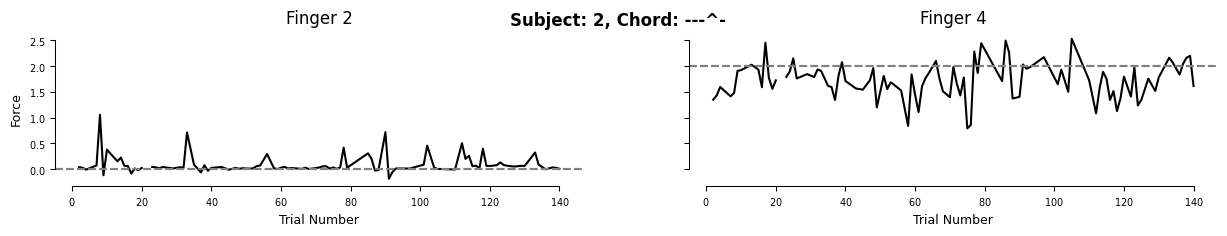

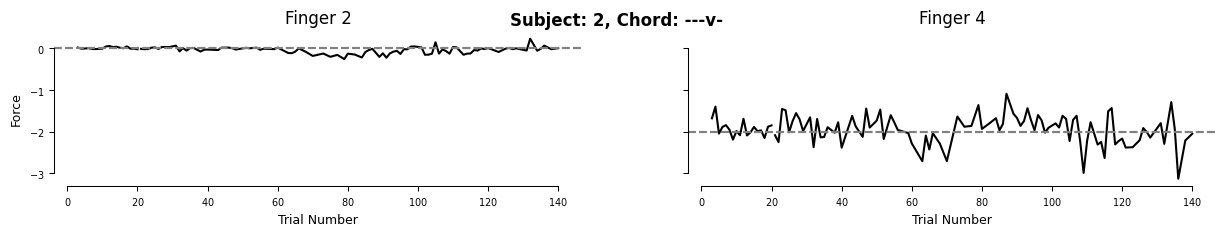

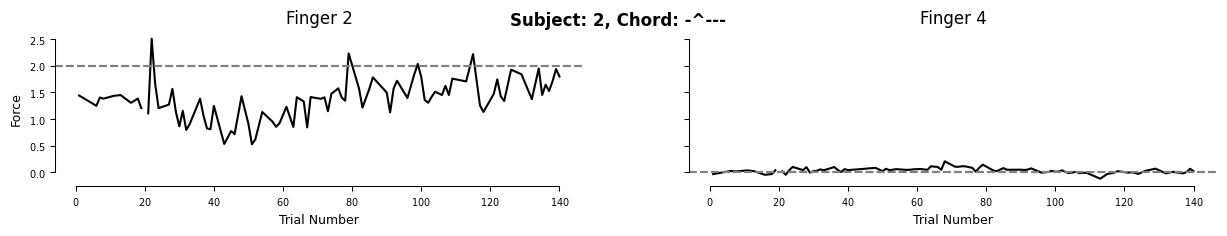

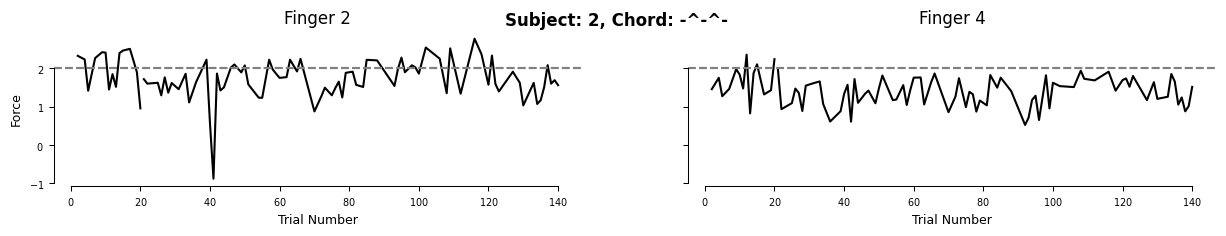

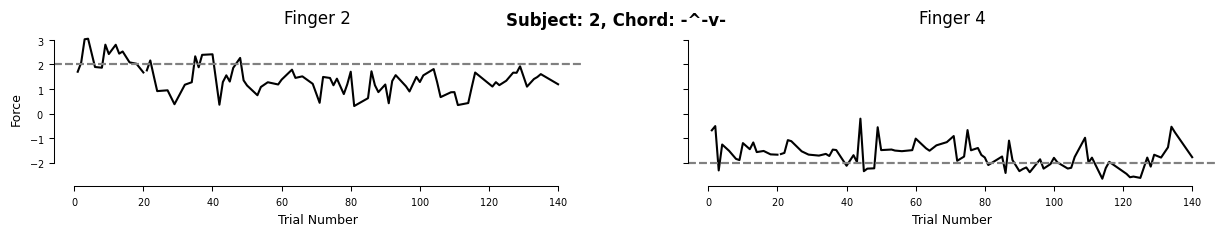

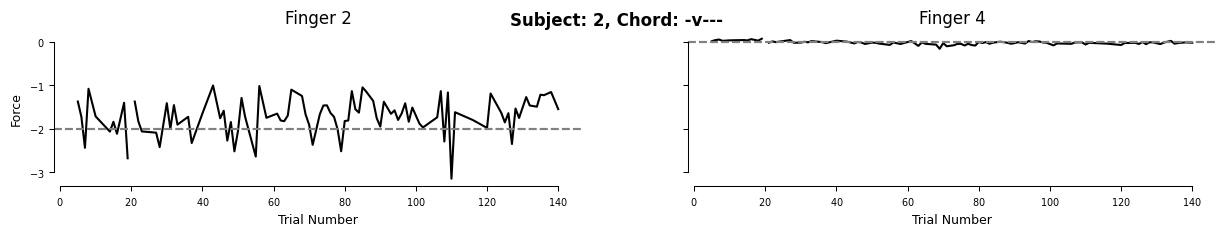

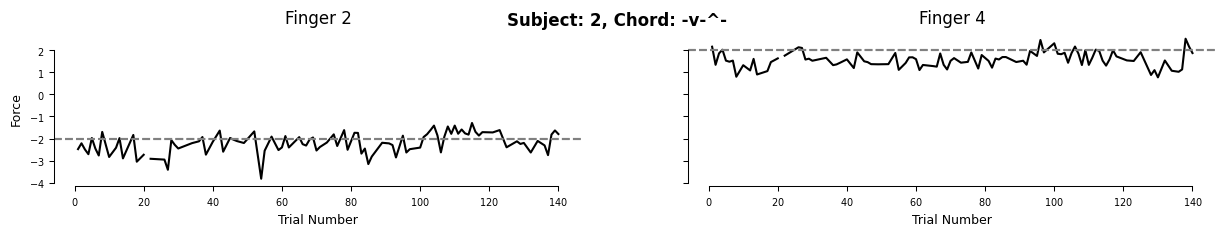

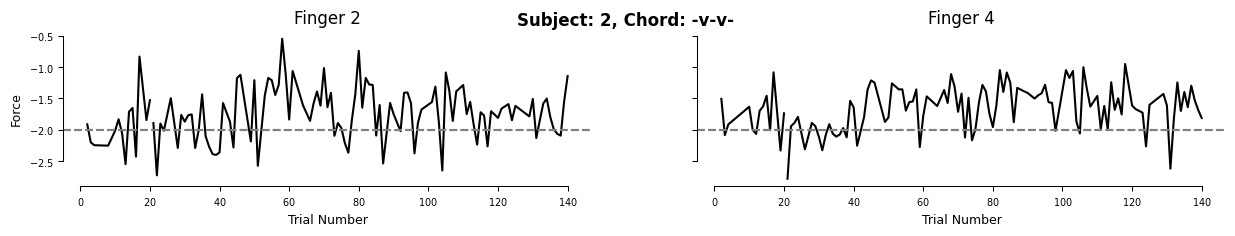

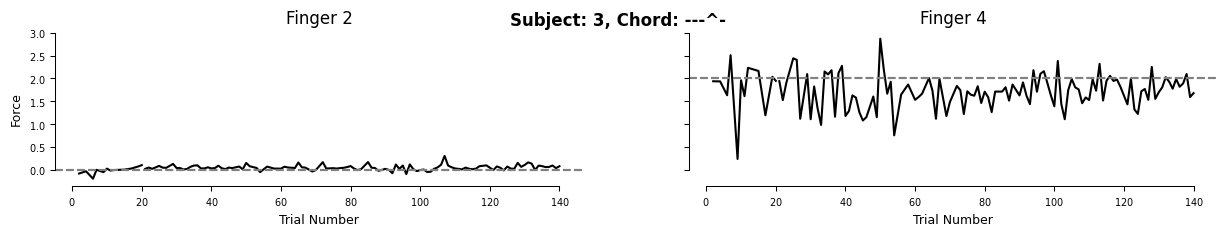

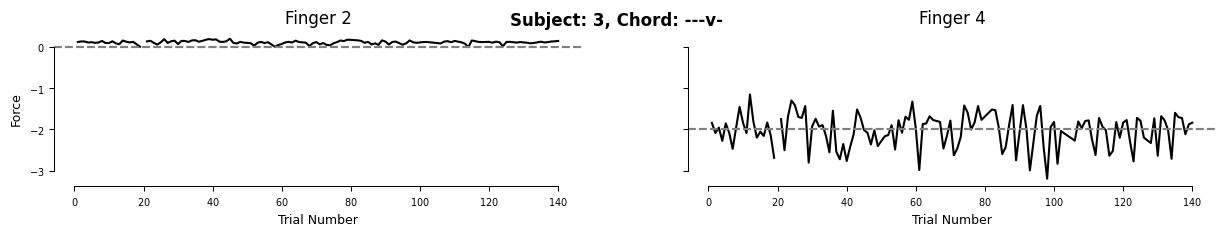

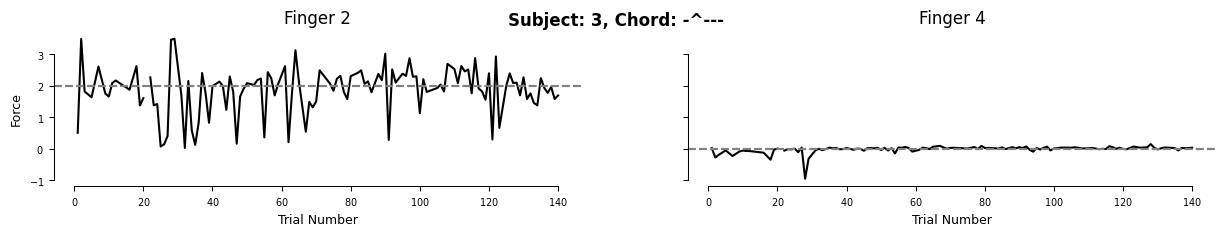

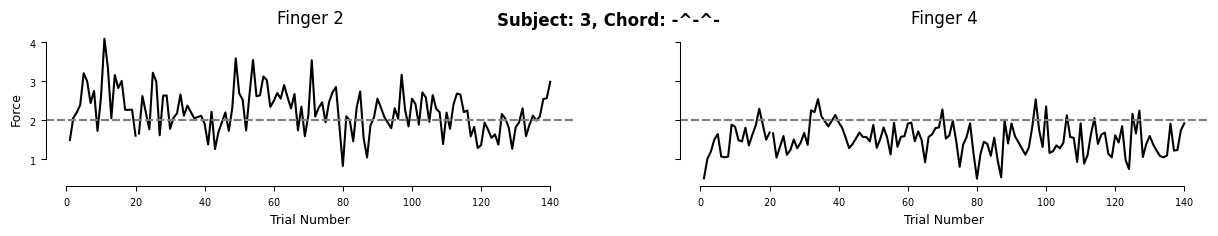

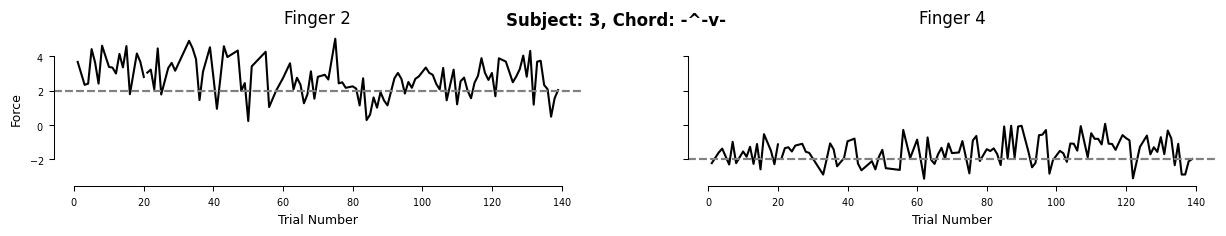

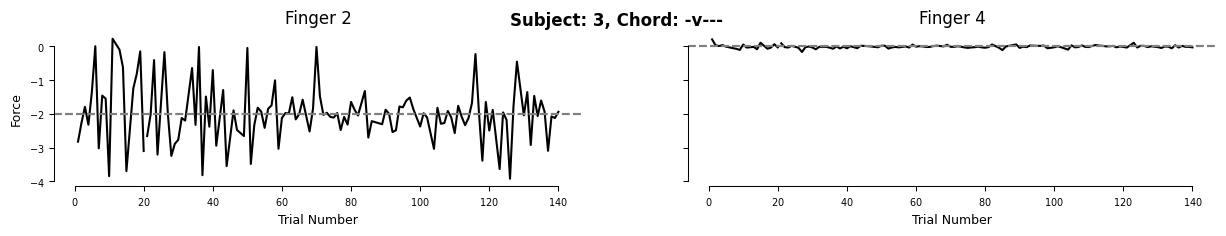

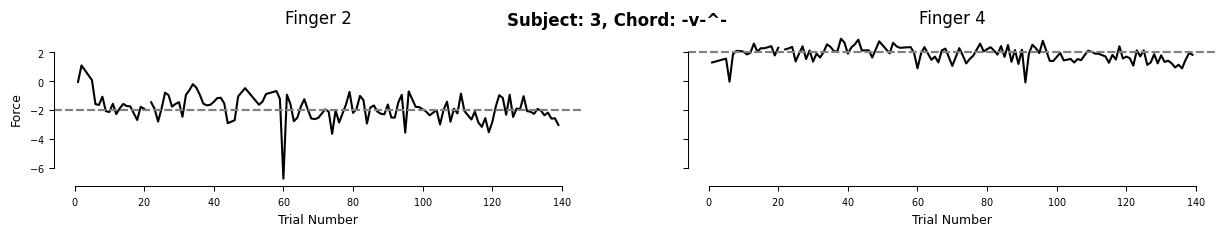

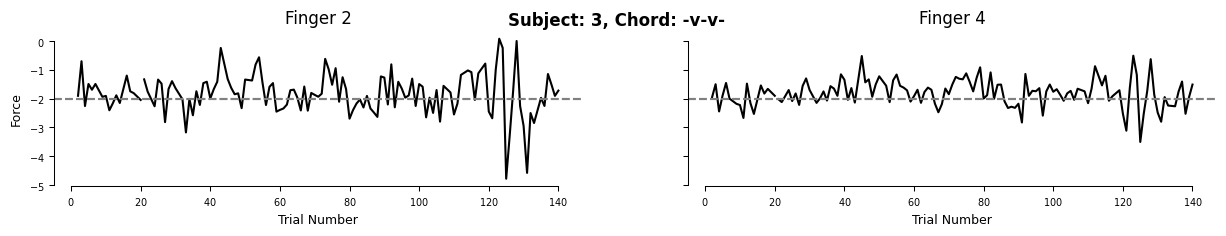

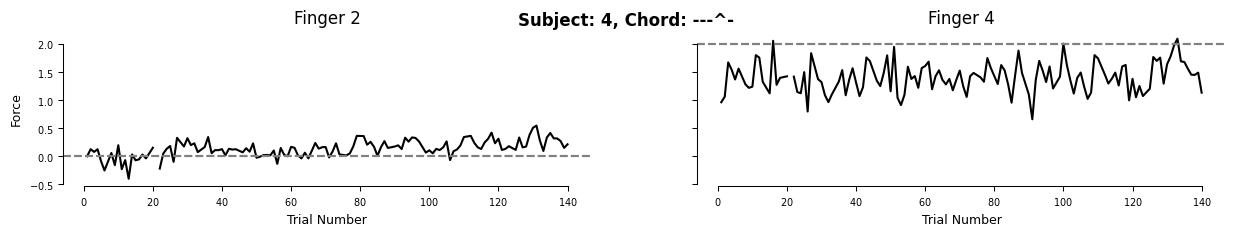

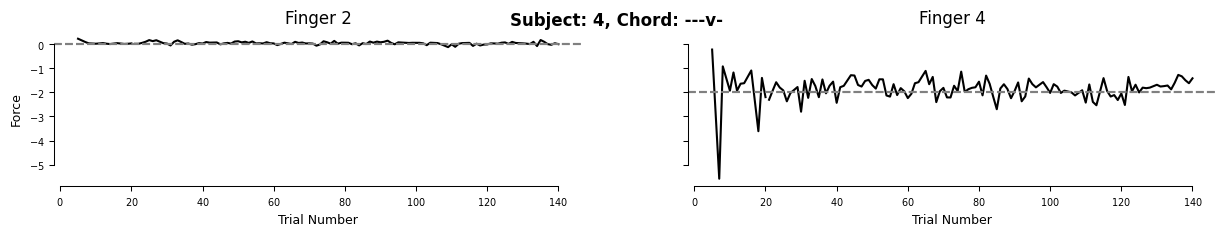

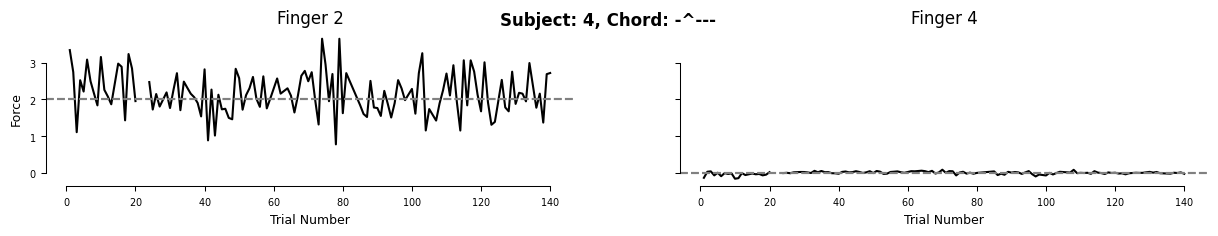

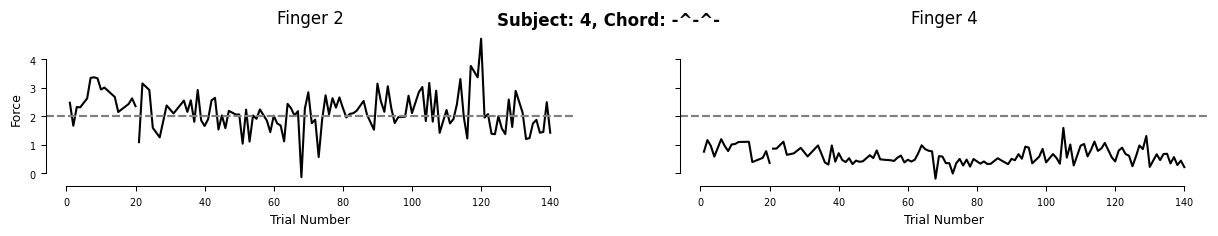

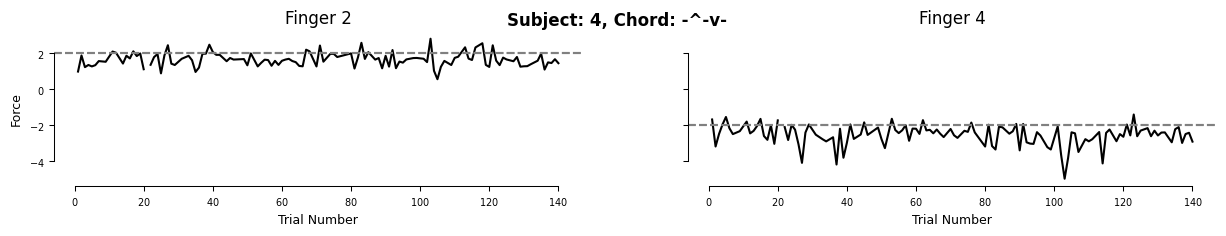

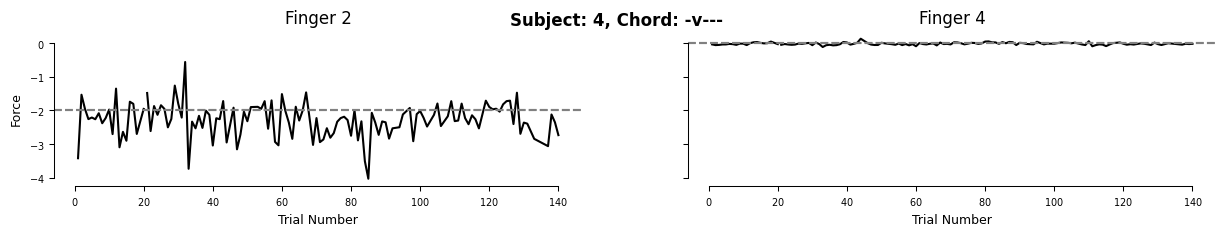

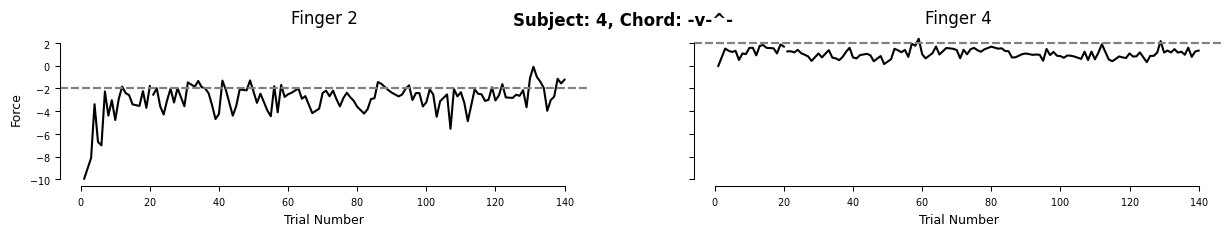

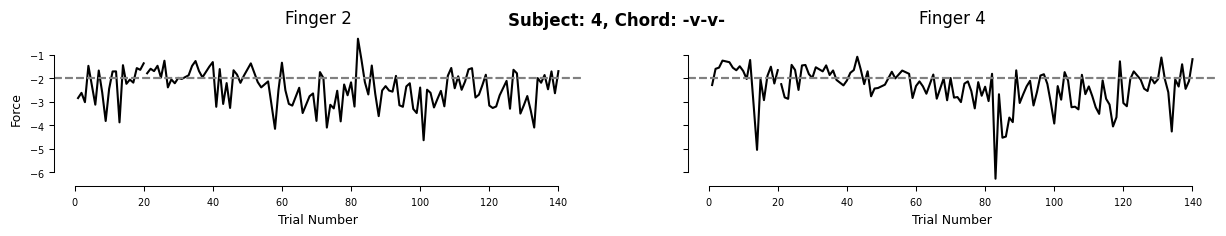

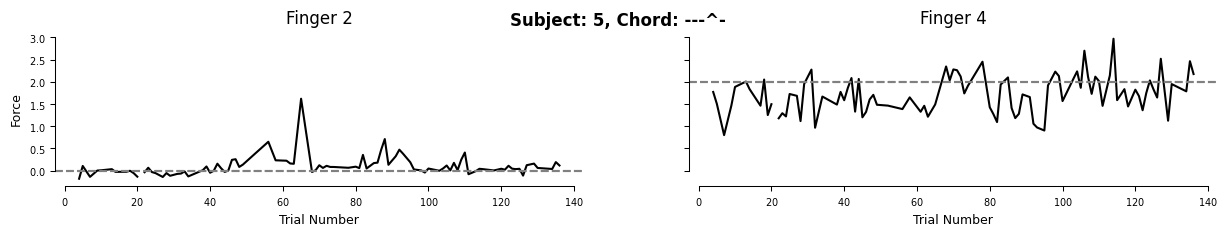

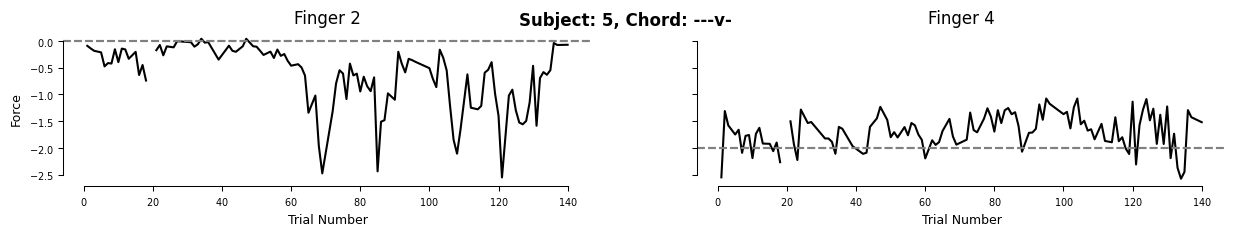

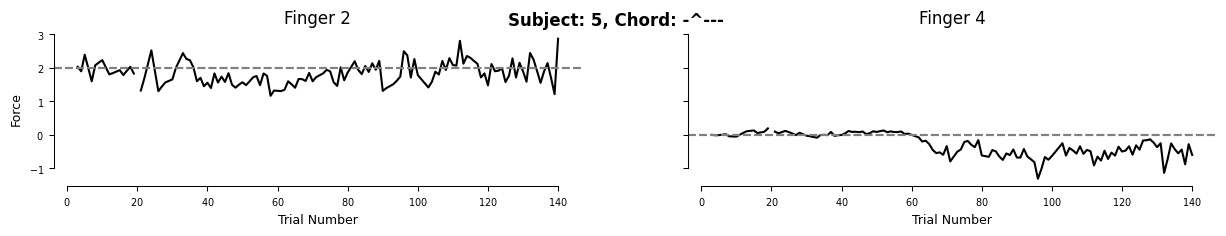

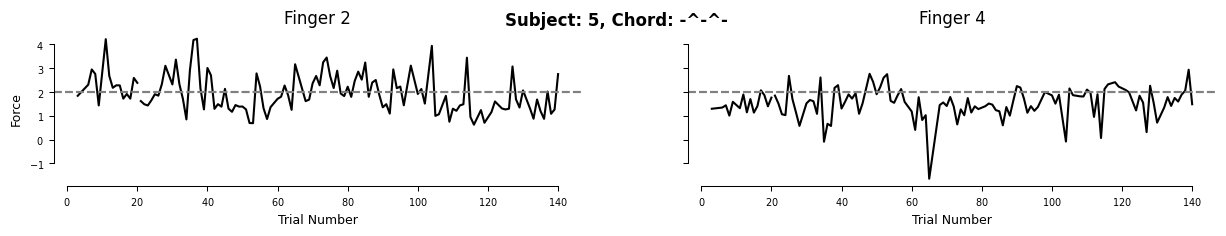

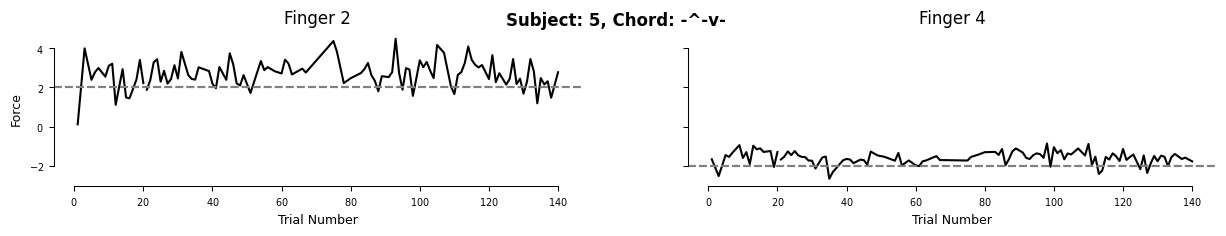

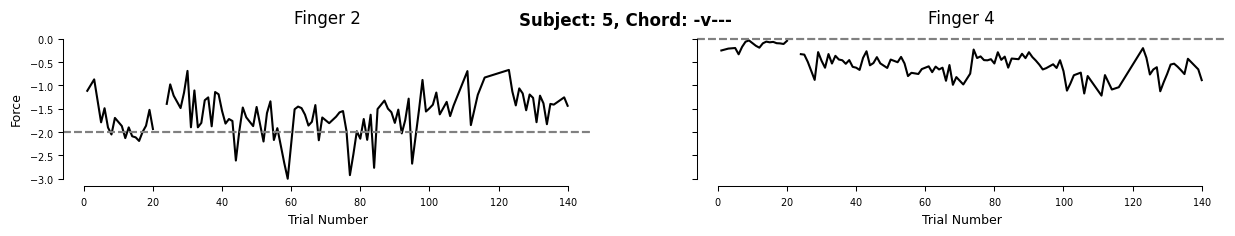

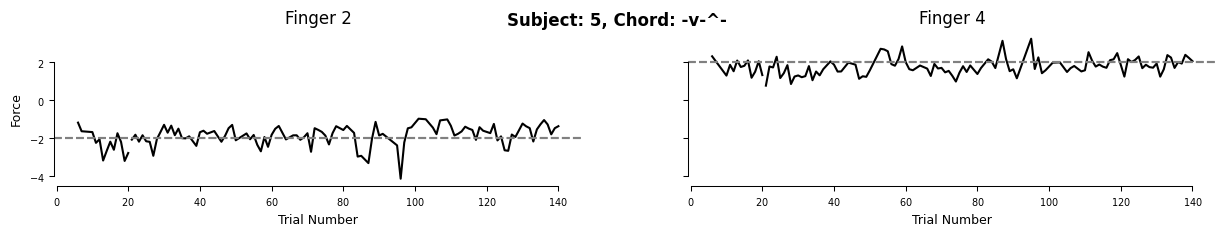

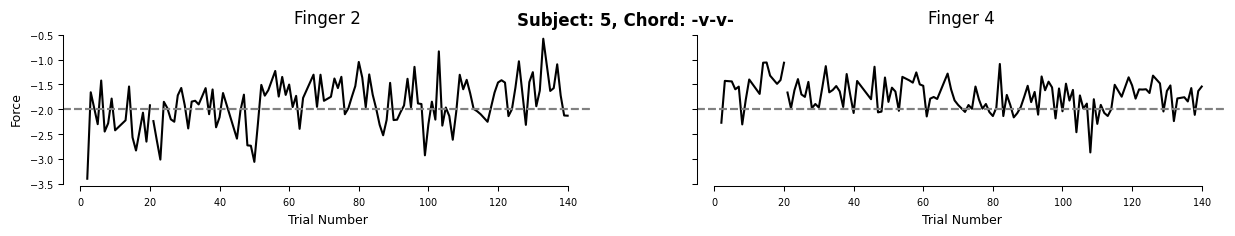

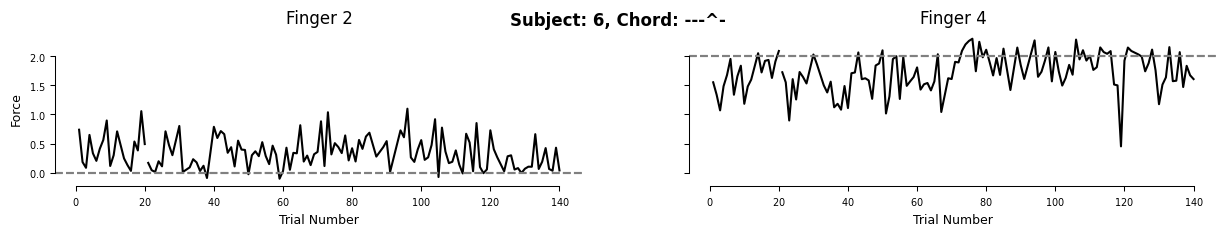

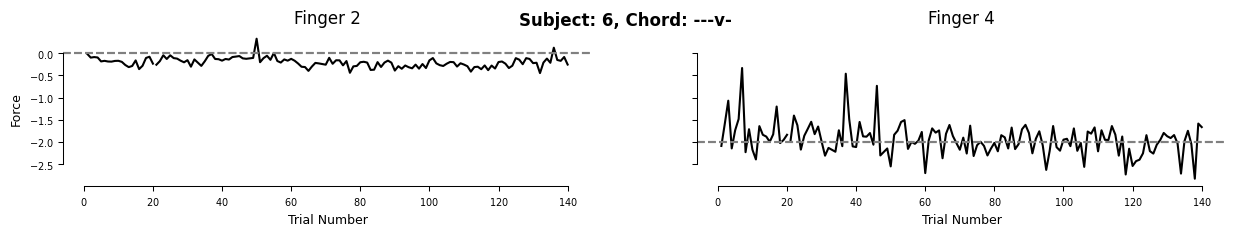

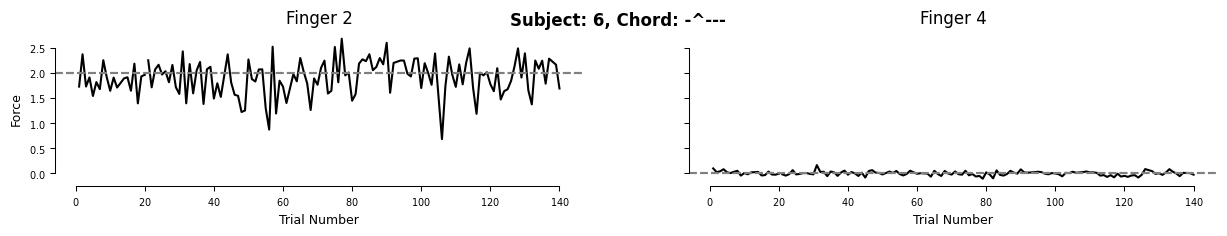

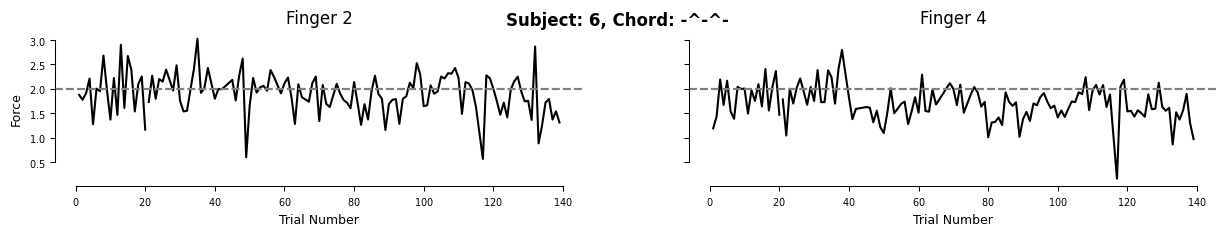

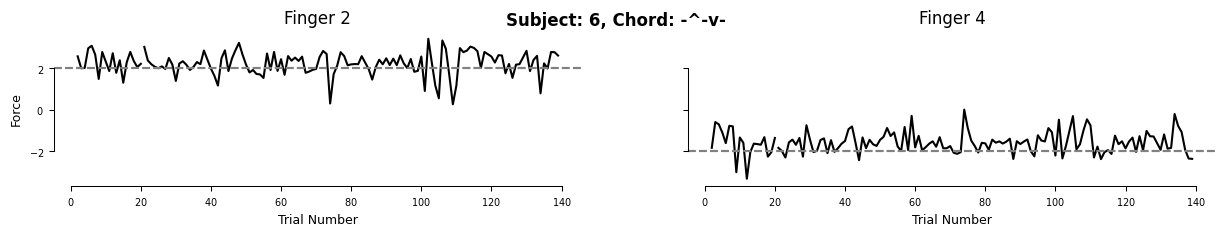

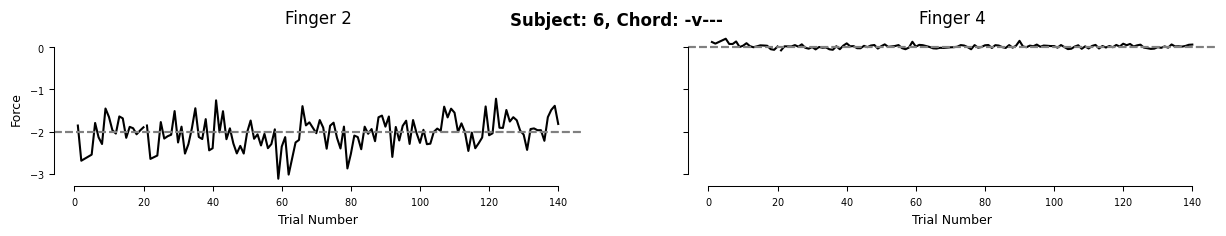

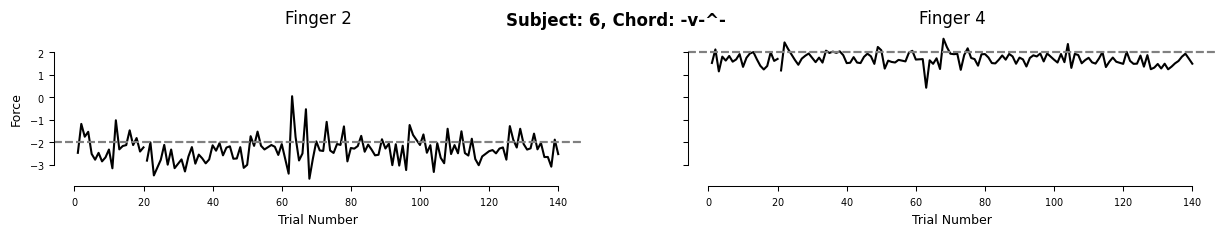

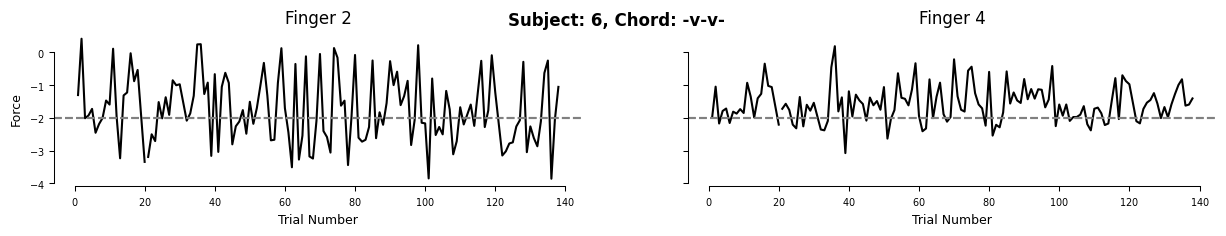

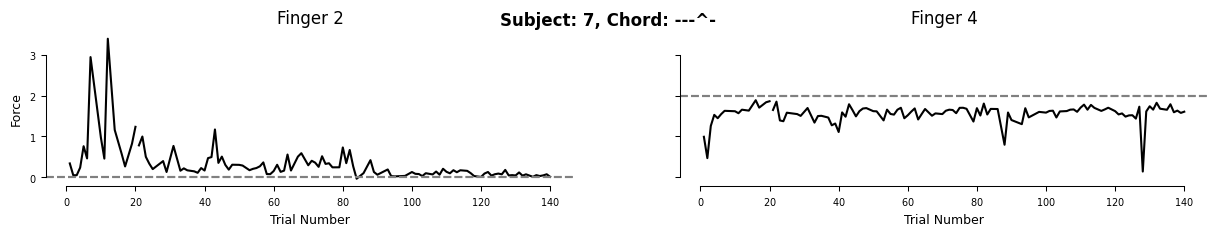

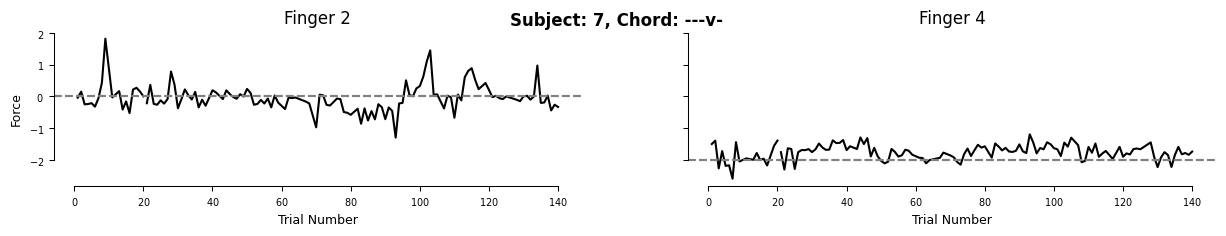

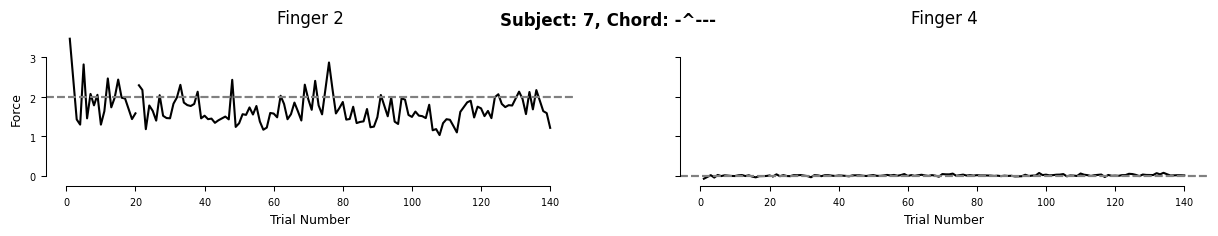

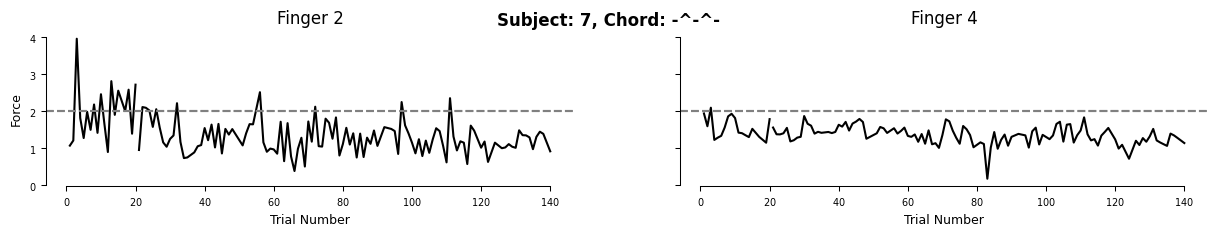

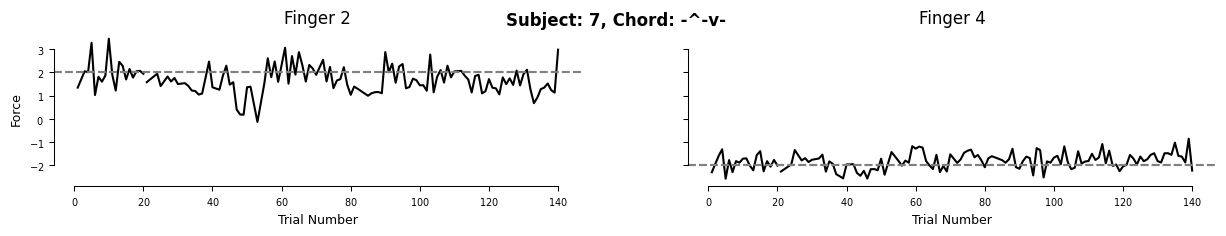

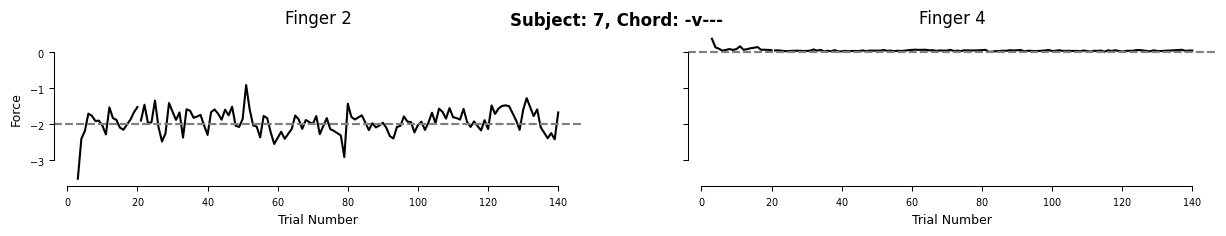

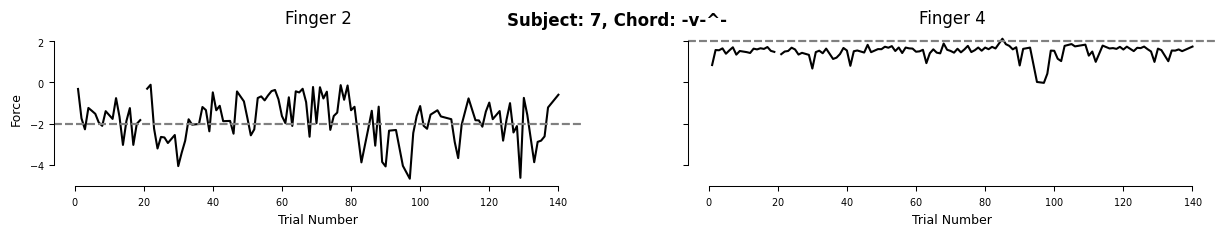

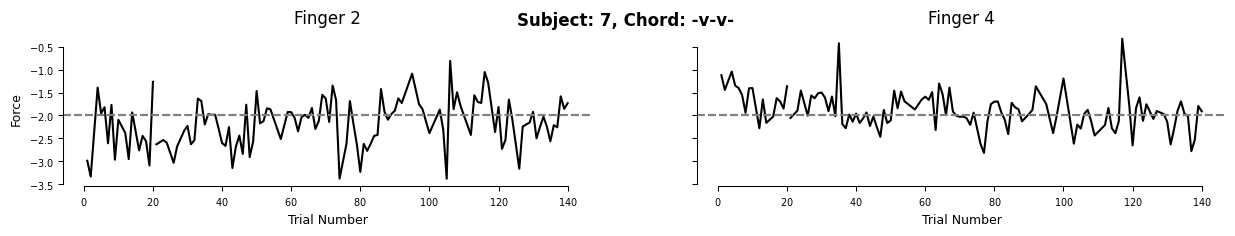

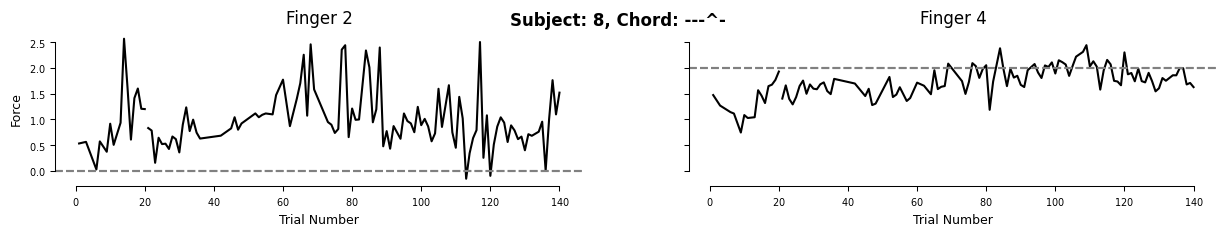

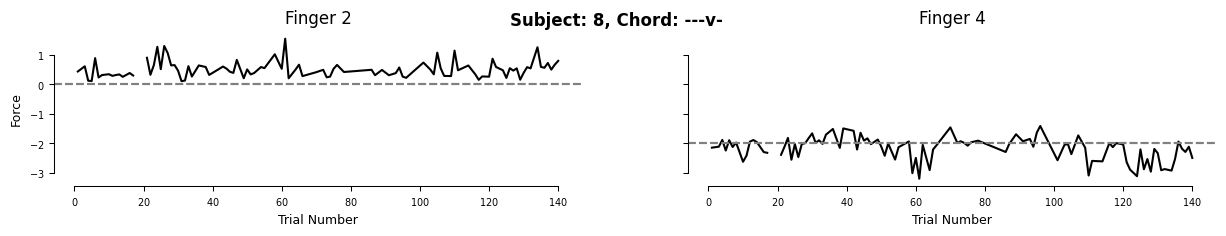

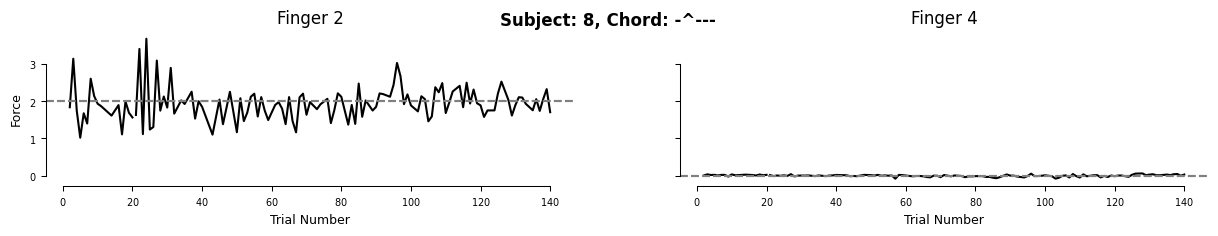

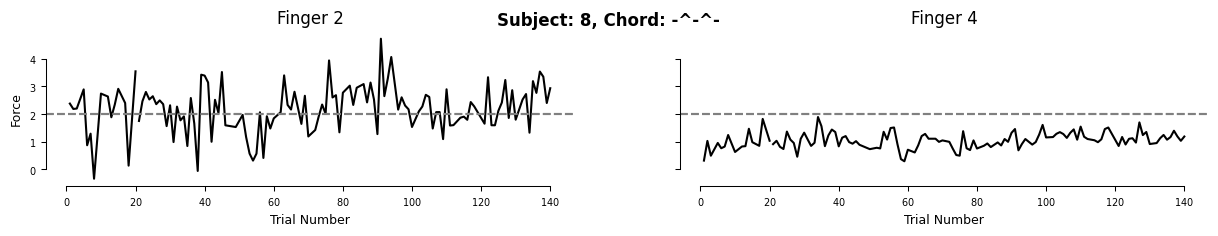

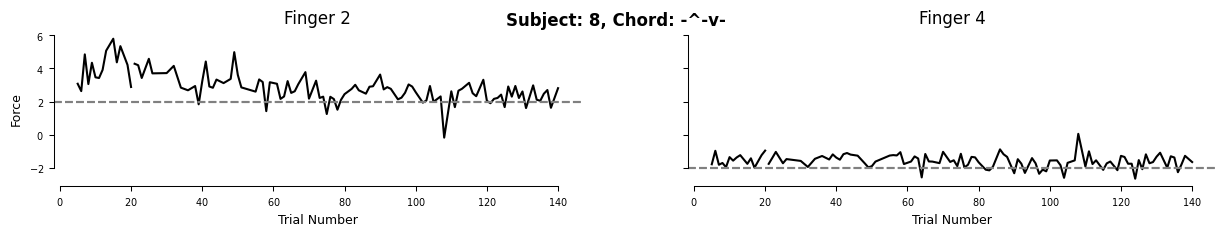

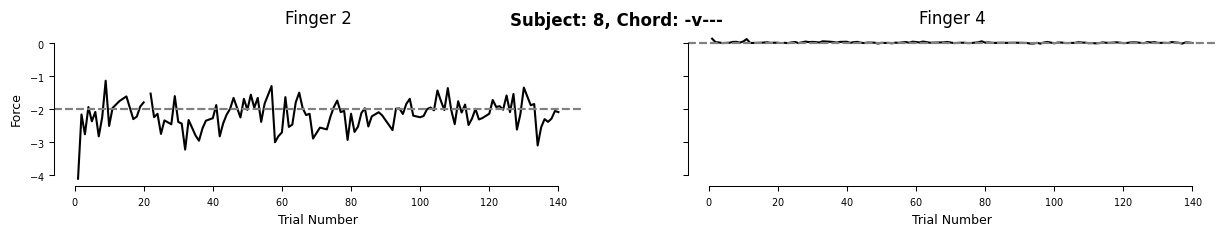

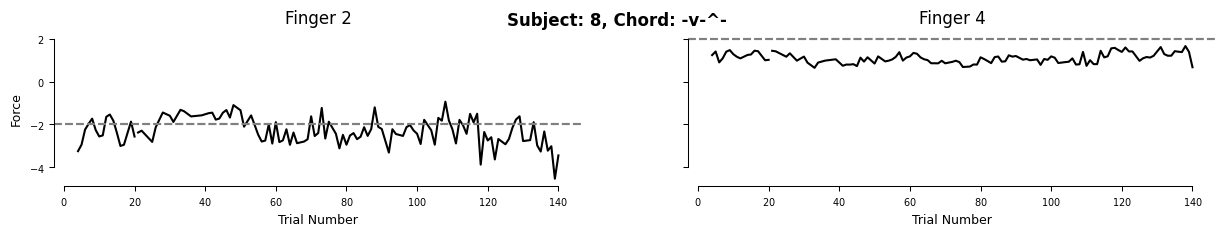

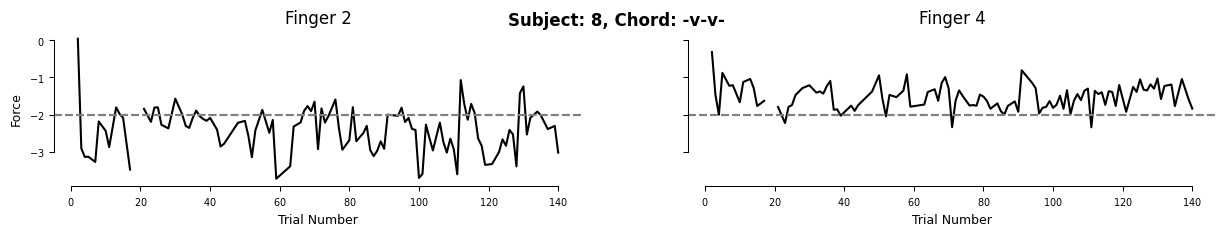

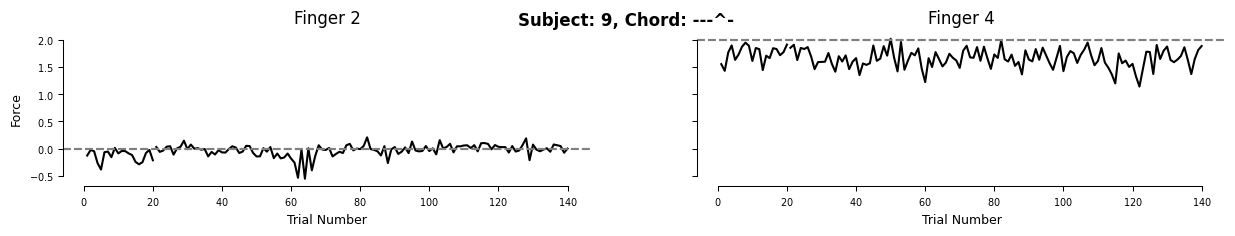

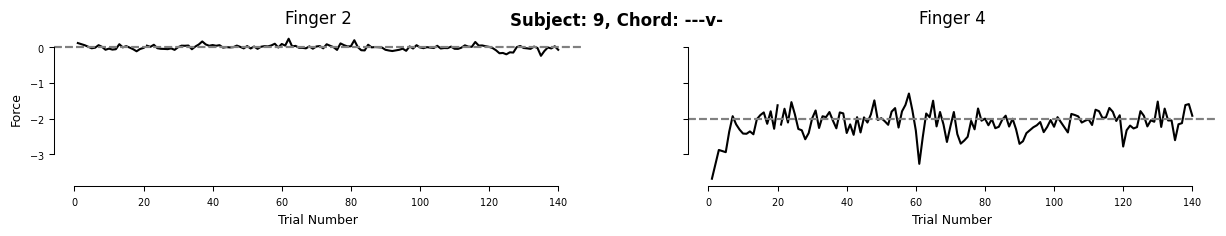

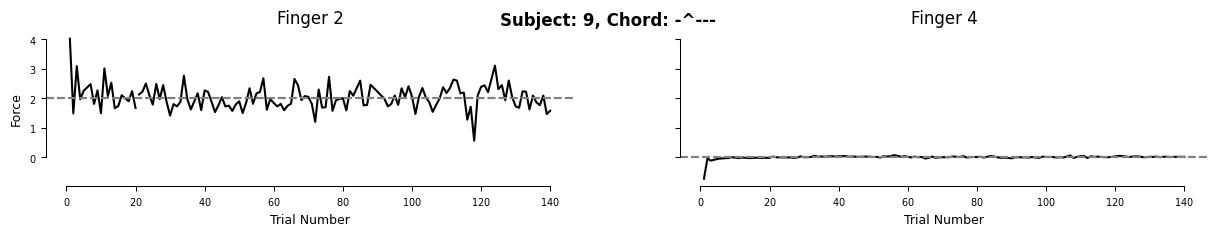

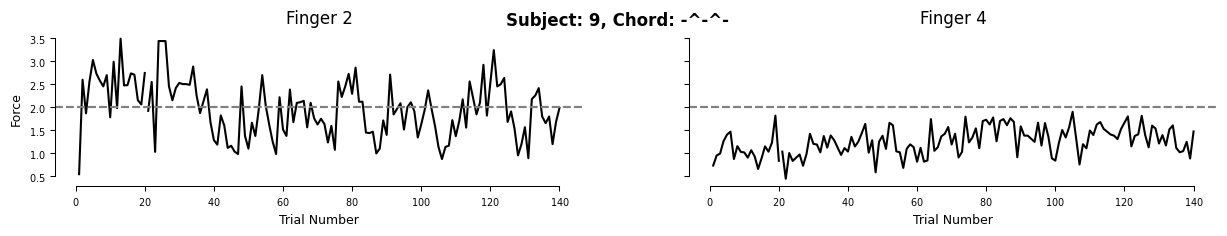

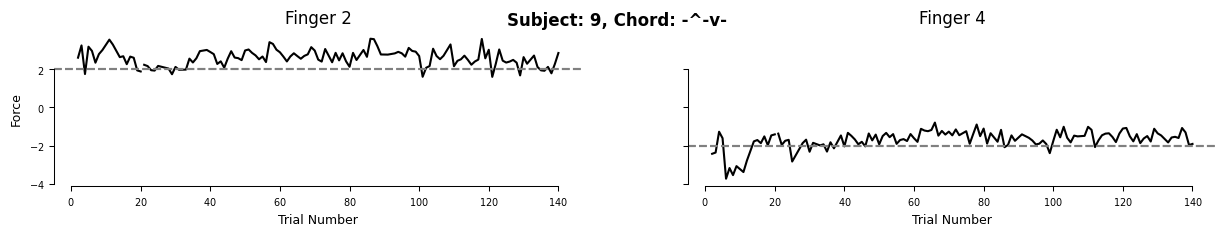

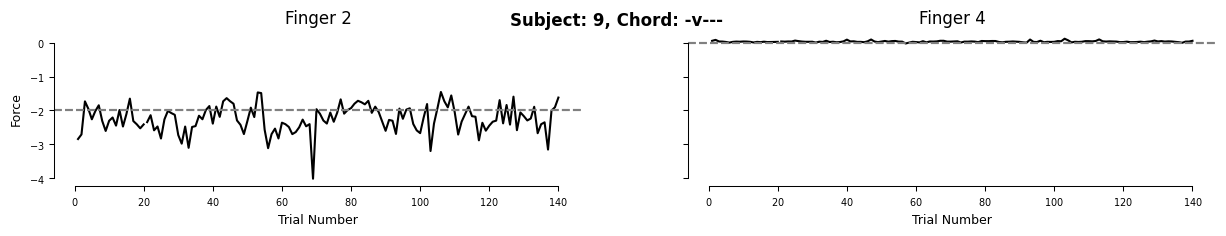

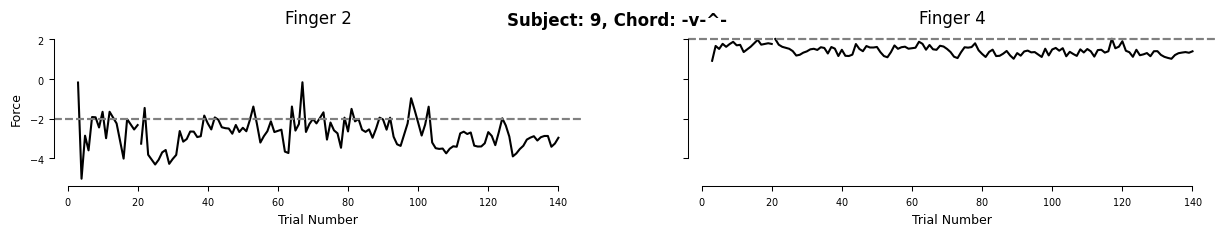

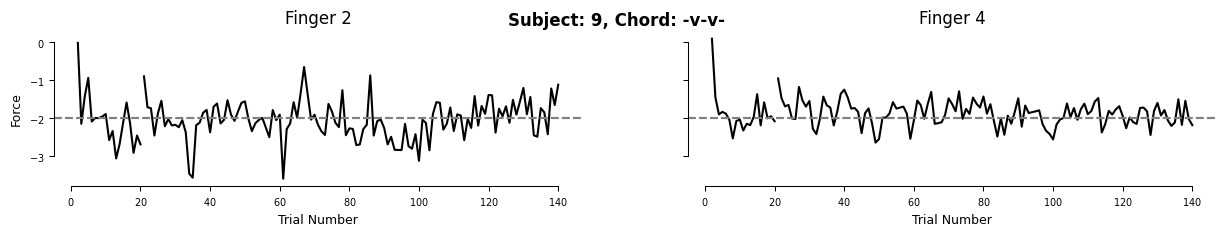

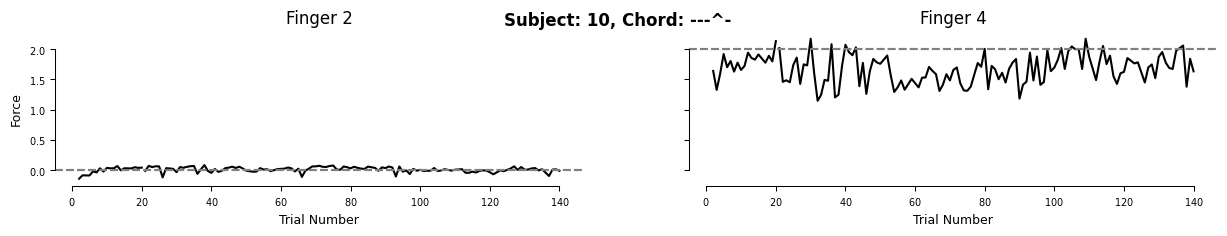

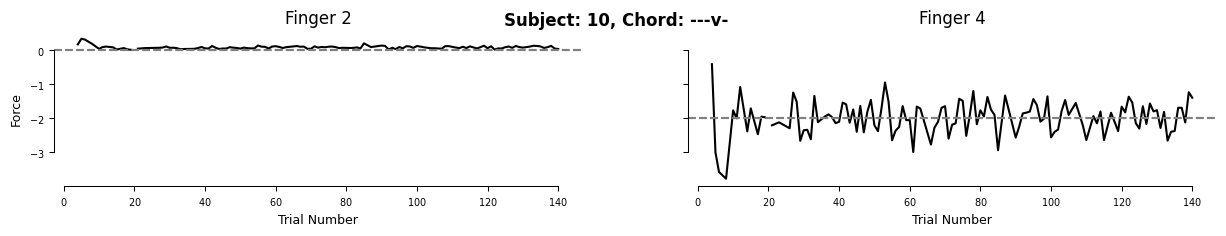

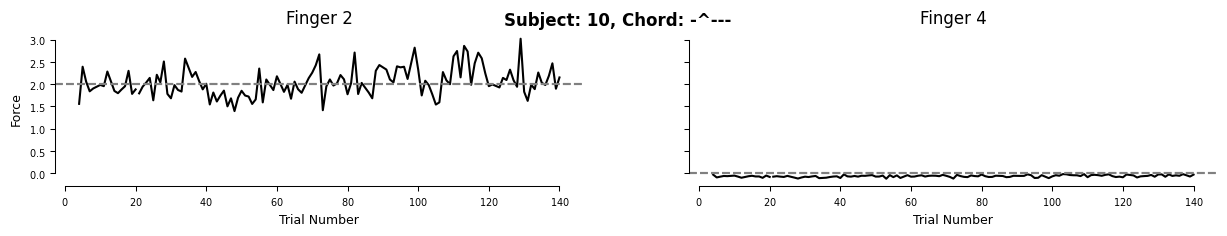

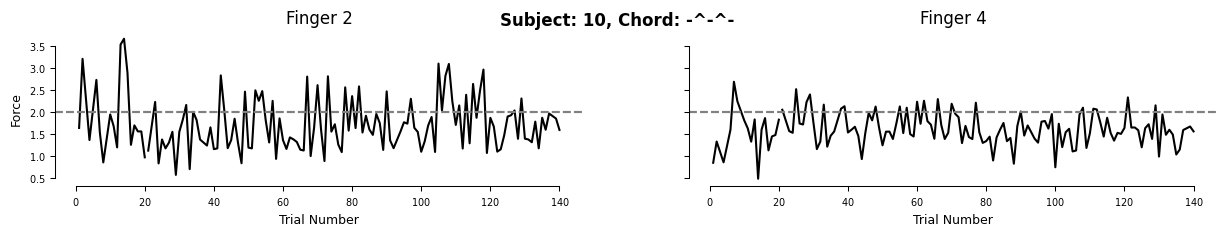

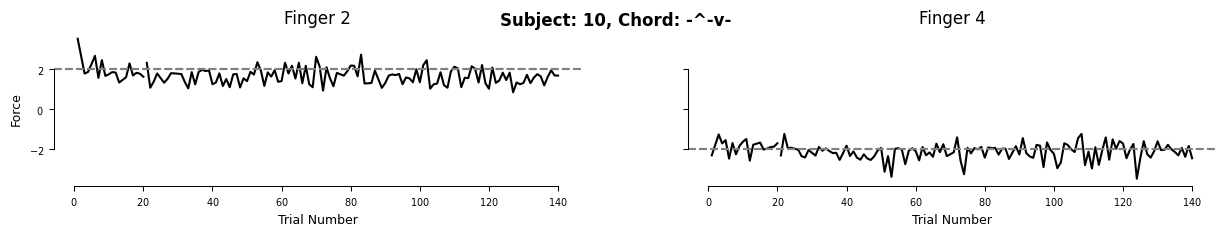

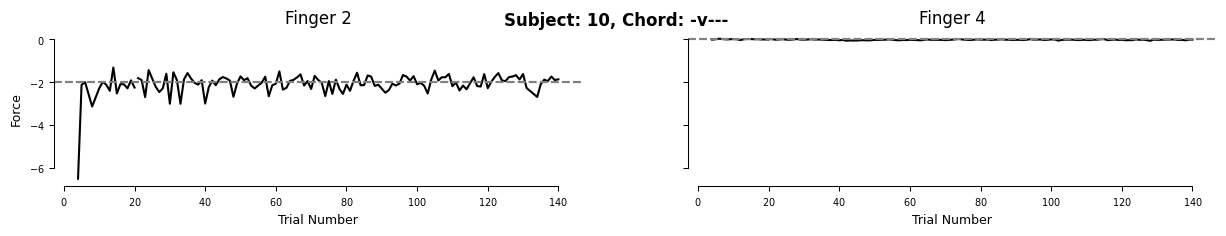

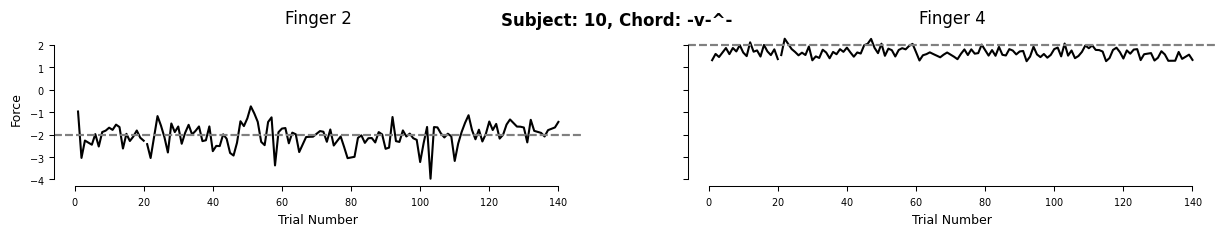

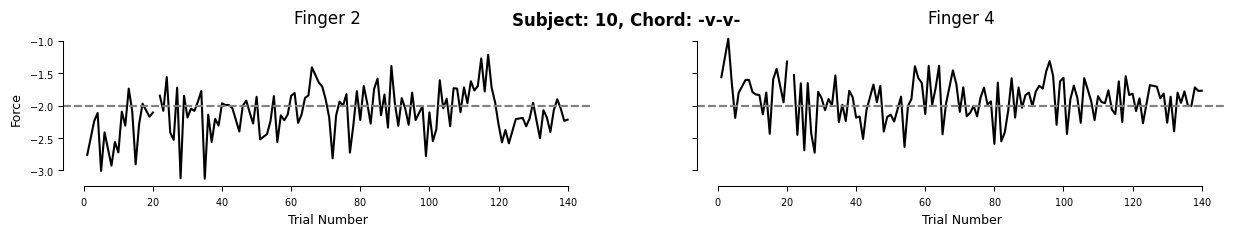

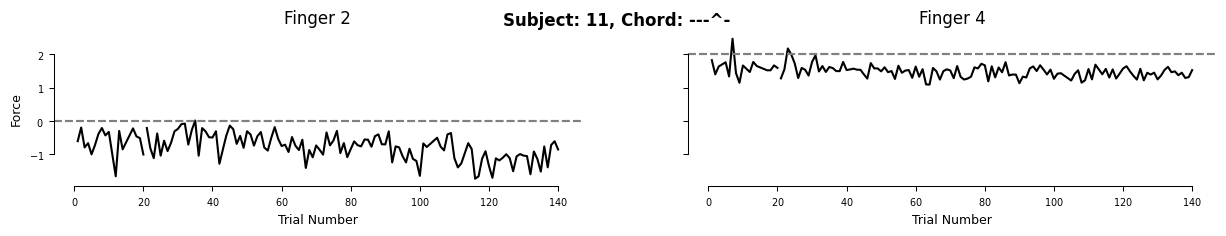

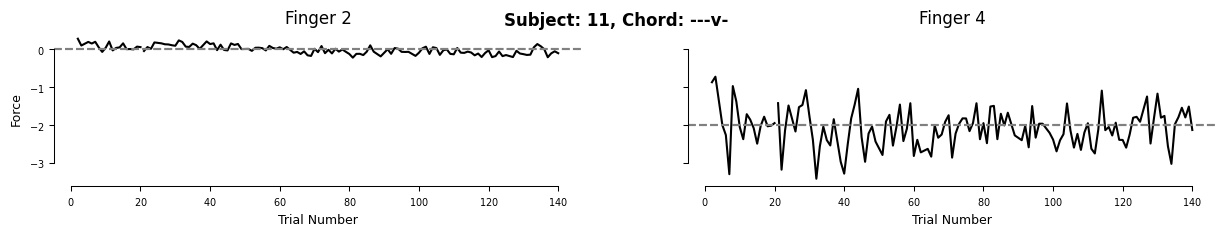

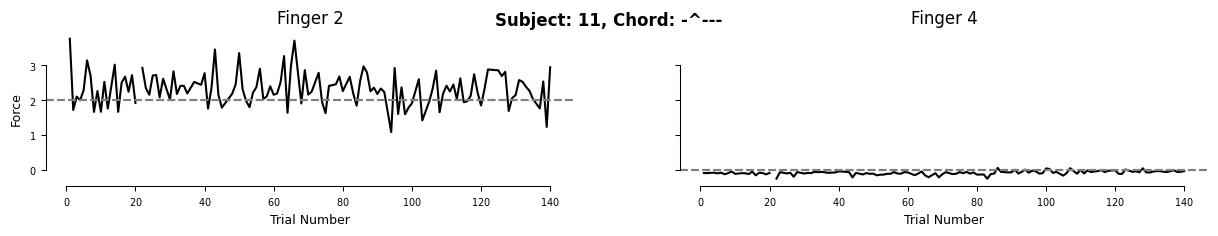

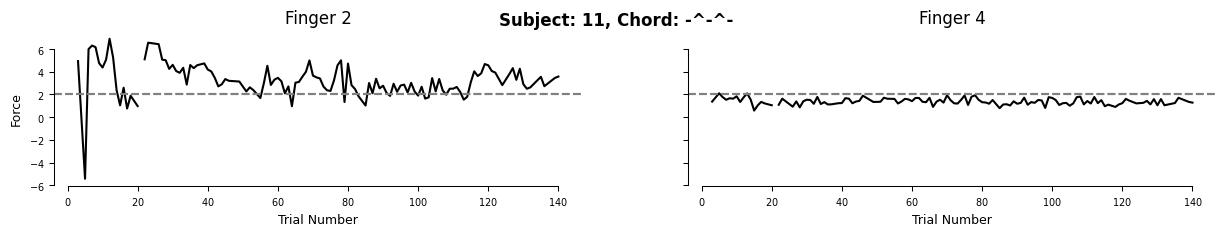

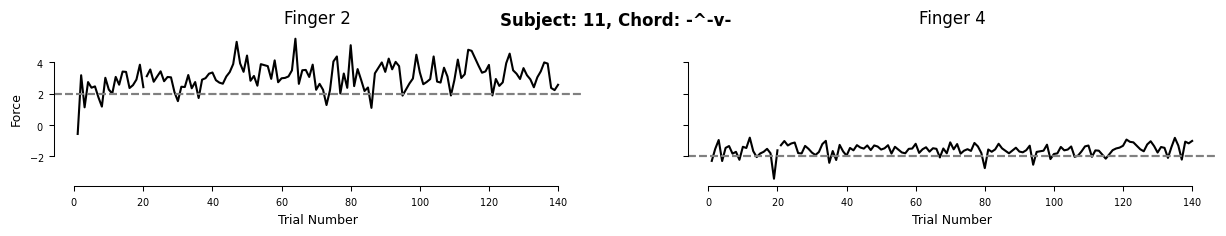

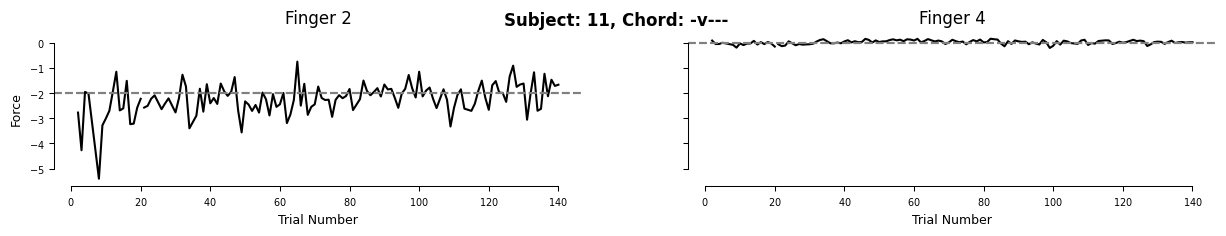

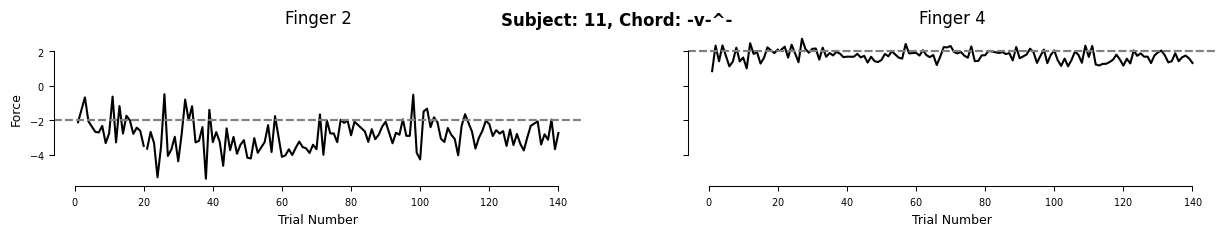

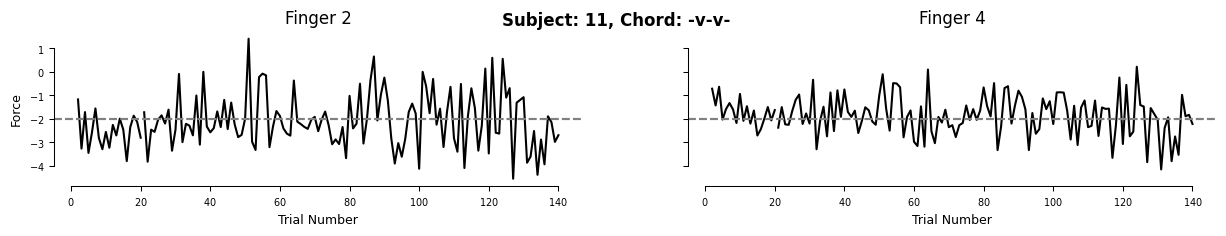

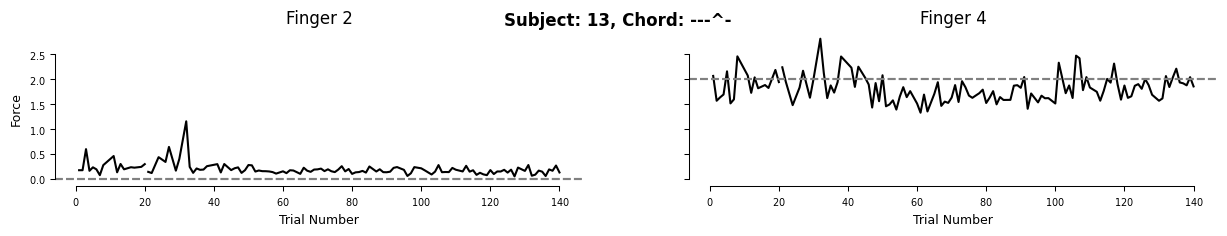

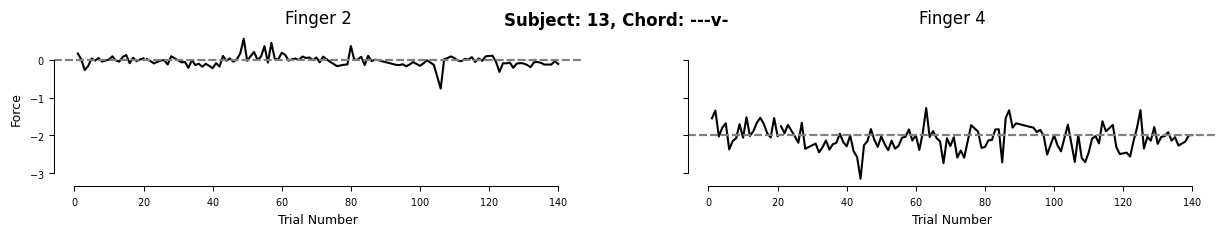

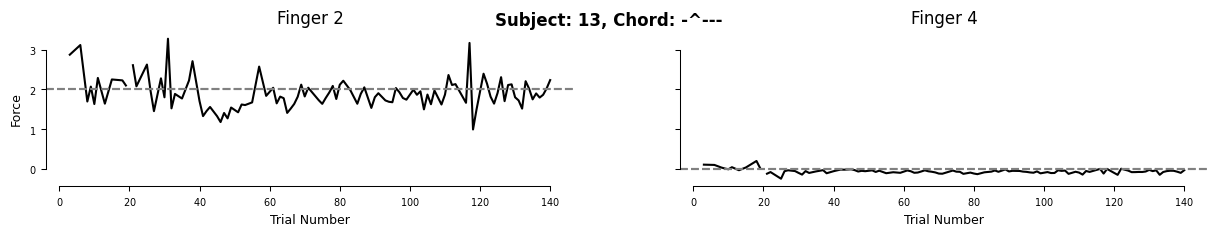

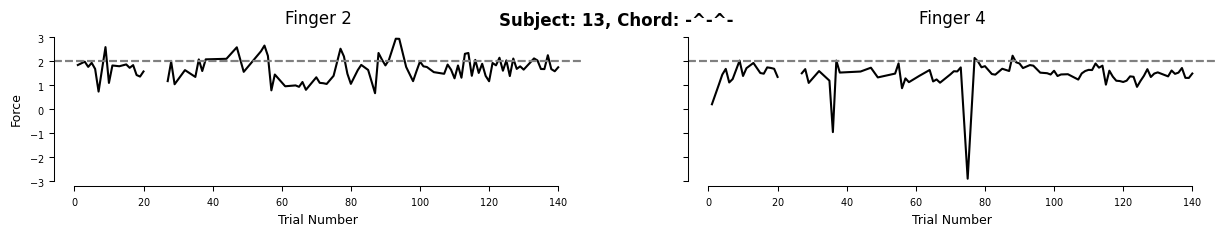

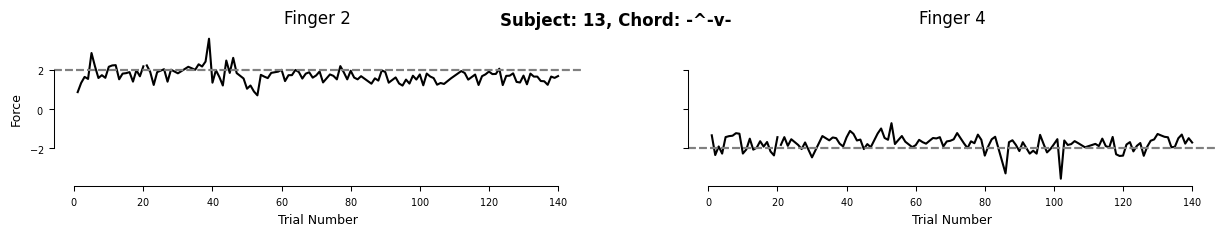

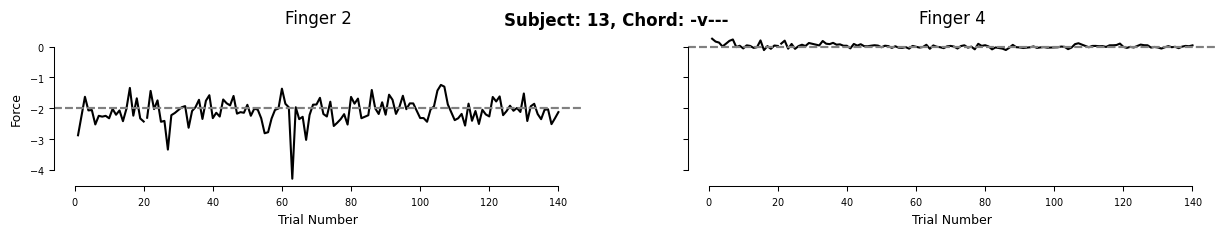

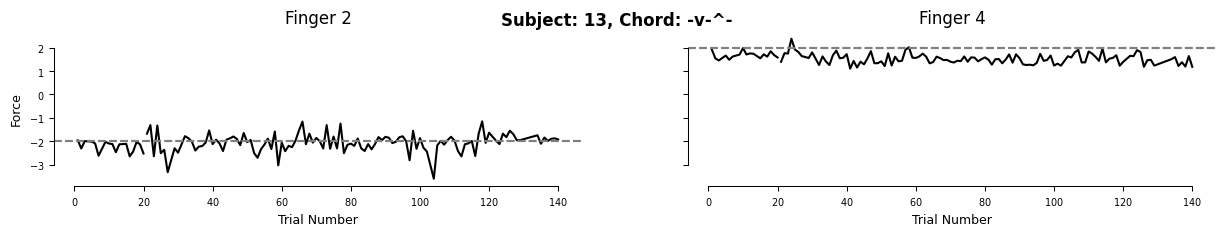

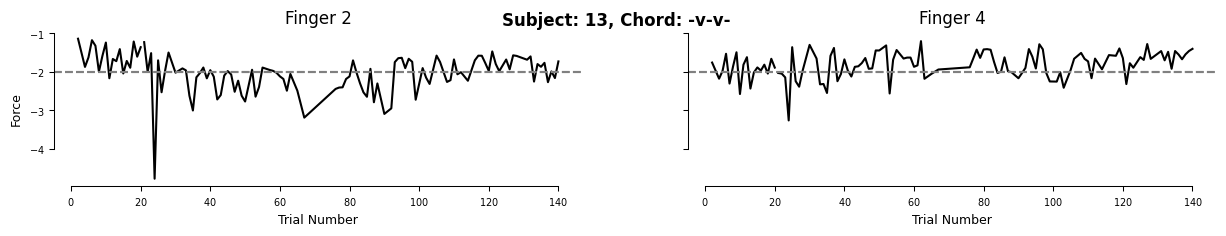

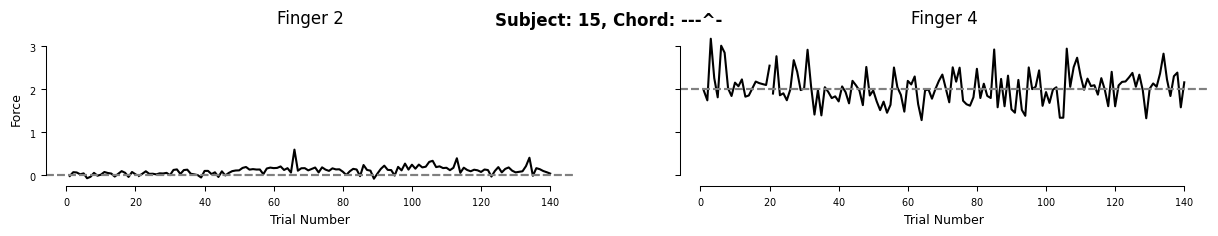

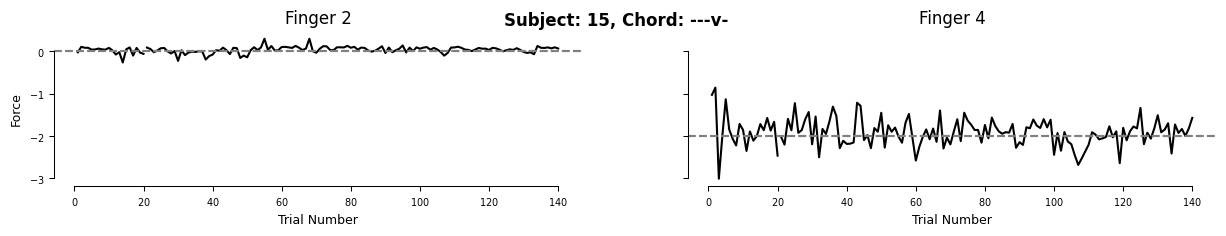

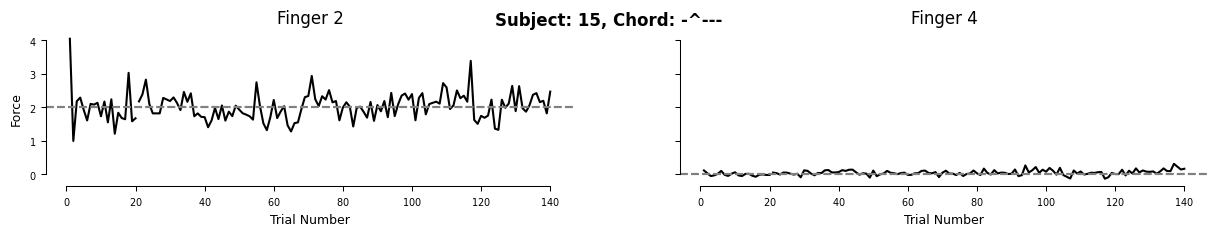

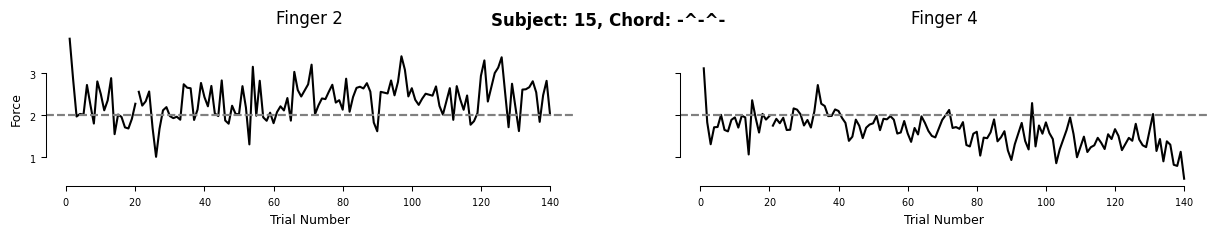

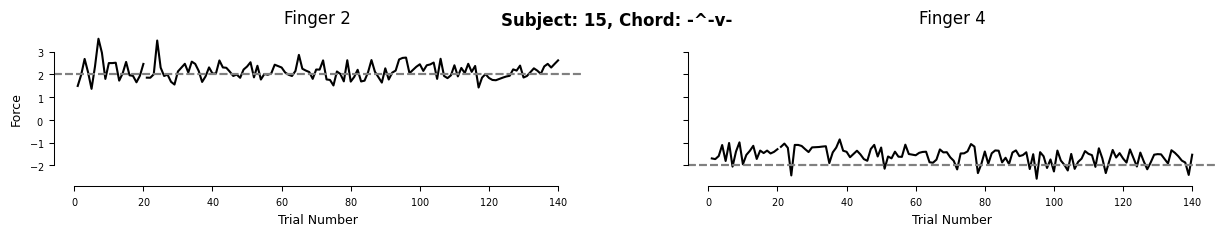

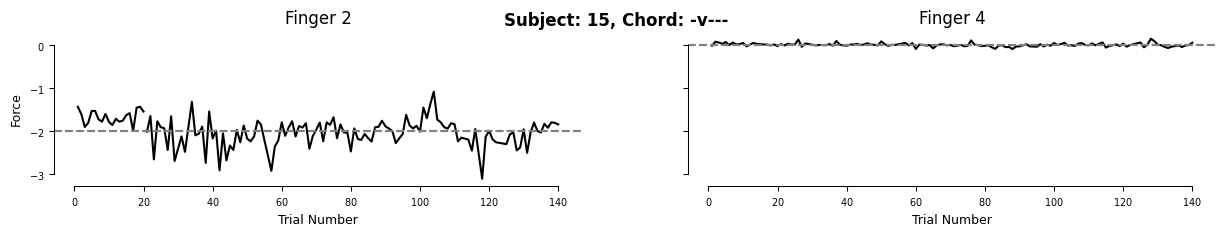

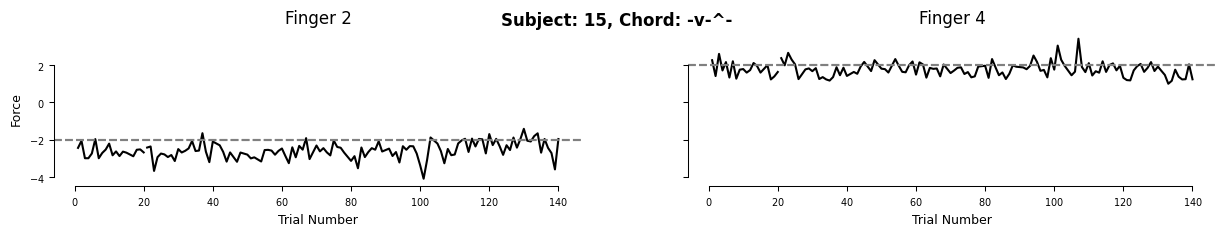

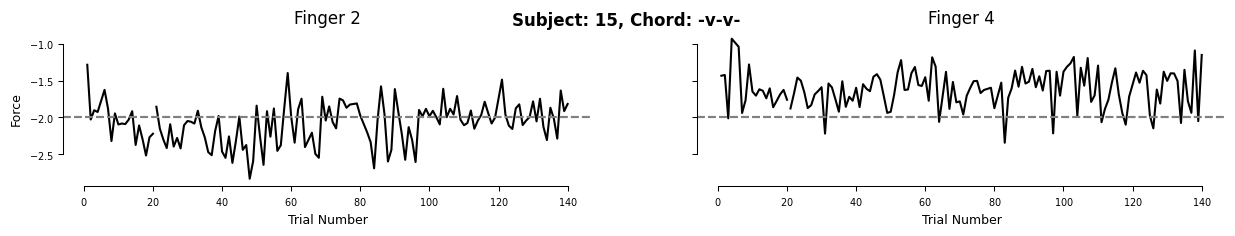

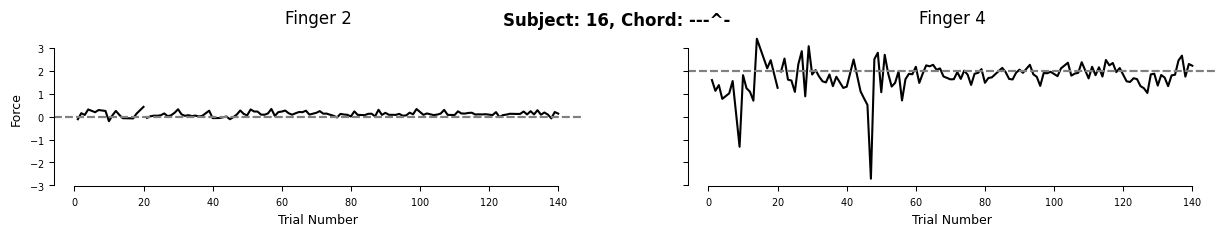

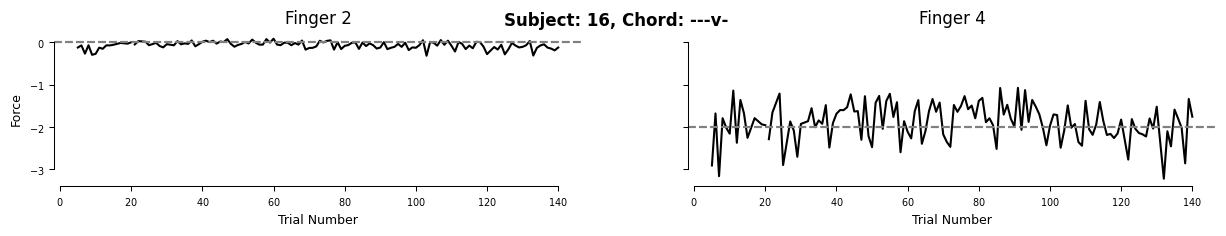

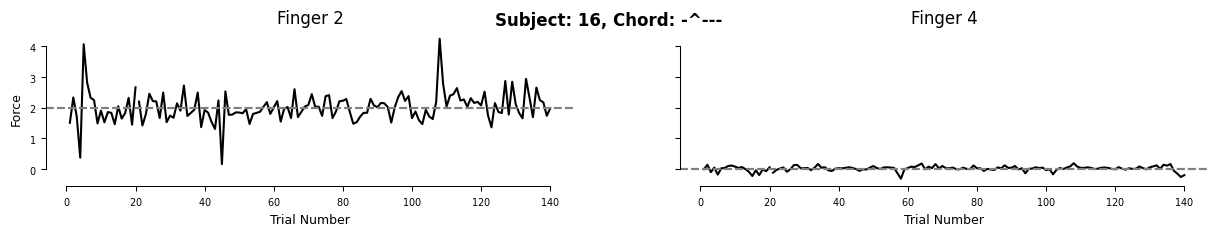

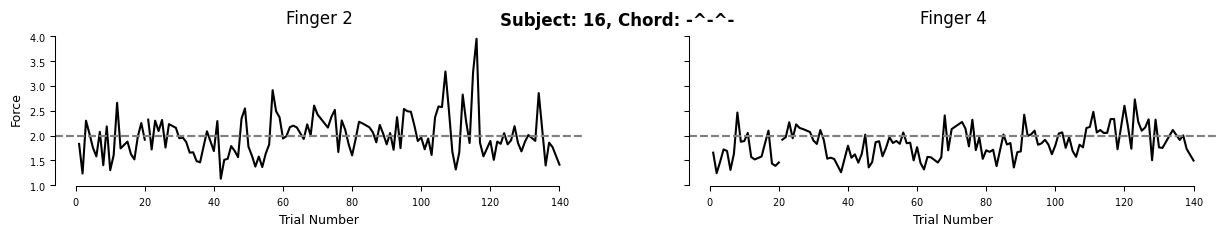

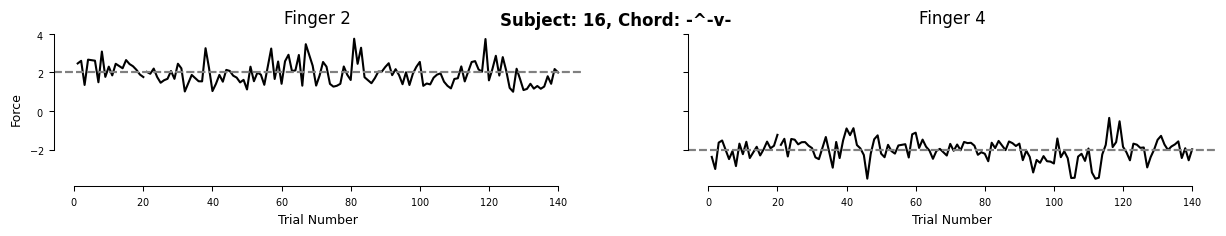

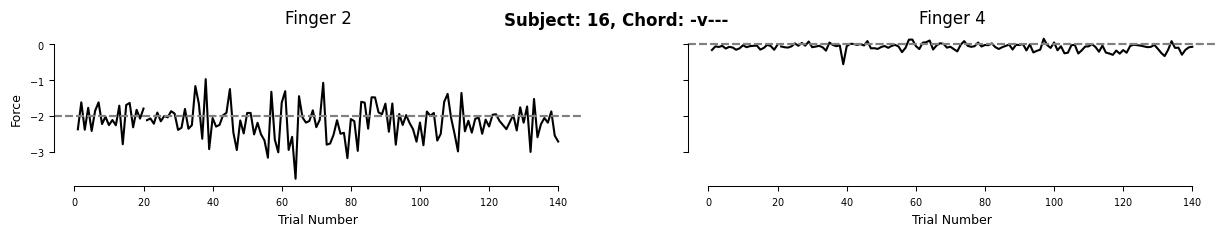

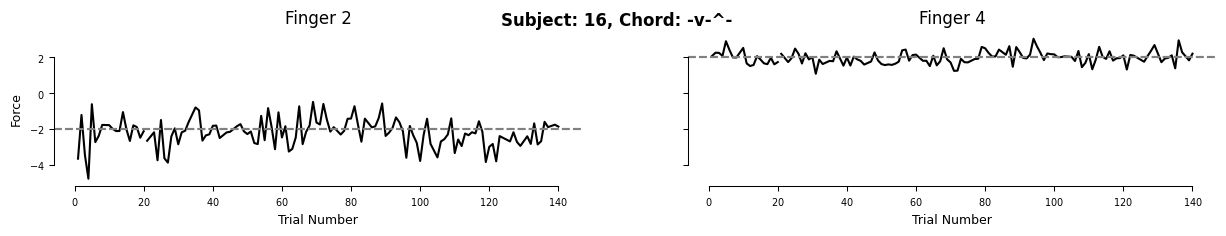

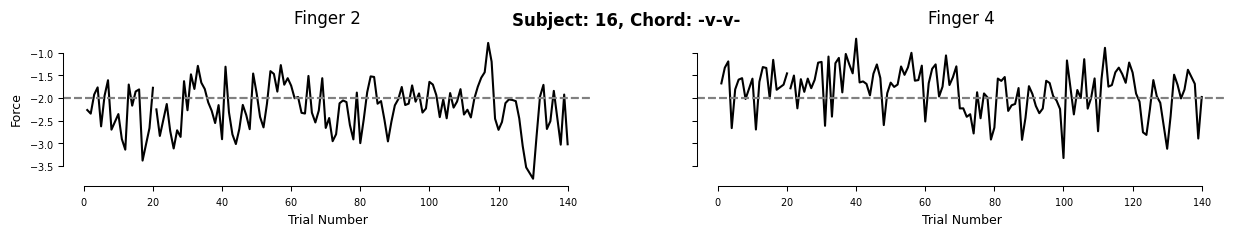

In [6]:
for subnum, subj_data in subjs_correct.groupby('subNum'):
    for chord, chord_data in subj_data.groupby('chord'):
        fig, axs = plt.subplots(1, 2, figsize=(15, 2), sharey=True)
        for block_type, block_type_data in chord_data.groupby('block_type'):
            for idx, finger in enumerate([2,4]):
                # sns.lineplot(data = block_type_data, x = 'trial_num_within_chord', y = f'endForce{finger}', 
                # ax = axs[idx], color = 'black', errorbar = 'se')
                sns.lineplot(data = block_type_data, x = 'trial_num_within_chord', y = f'endForce{finger}', 
                ax = axs[idx], color = 'black', errorbar = None)
                # sns.lineplot(data = block_type_data, x = 'trial_num_within_chord', y = f'endForcePurturbed{finger}', 
                # ax = axs[idx], color = 'gray', linestyle = '--')
                if block_type == 'purturbed':
                    # print(block_type_data[f'purturbation{idx+1}'])
                    pass
                axs[idx].axhline(block_type_data[f'targetForce{finger}'].iloc[0], color = 'gray', linestyle = '--')
                axs[idx].set_xlabel('Trial Number')
                axs[idx].set_ylabel('Force')
                axs[idx].set_title(f'Finger {finger}')
        
        sns.despine(trim = True)
                
        fig.suptitle(f'Subject: {subnum}, Chord: {chord}')
        plt.show()


## Parameter estimation methods

Two approaches are used in this notebook to estimate the state-space learning model parameters. The schematic below summarizes how each pipeline processes the data and what it outputs.

- **Method A (covariance shortcut):** closed-form estimate of the **B** matrix per subject × chord
- **Method B (Nelder–Mead MLE):** fiting **A** (retention) and **B** (learning) with the whole series of data per subject × chord.


# Method A

In [5]:
# # Model (target subtracted, so everything is a deviation from target):
# #   Z_t                                 : hidden state (plan)
# #   X_t = Z_t + nu_t                    : produced force   (endForce - target)
# #   Y_t = X_t + p_t = Z_t + nu_t + p_t  : perturbed force  (endForcePurturbed - target)
# #   Z_{t+1} = A Z_t - B Y_t             : learning rule (note the MINUS sign; the error
# #                                         fed back to the plan is the perturbed force Y_t)
# # where nu_t is the measurement / execution noise and p_t is the perturbation.

# # Method A estimates B by regressing the trial-to-trial change of the PERTURBED
# # force (Y_{t+1} - Y_t) on the perturbation p_t:
# #
# #   Y_{t+1} - Y_t = Z_{t+1} - Z_t + nu_{t+1} - nu_t + p_{t+1} - p_t
# #                 = A Z_t - B Y_t - Z_t + nu_{t+1} - nu_t + p_{t+1} - p_t
# #                 = (A - I) Z_t - (B + I) (nu_t + p_t) + nu_{t+1} + p_{t+1}
# #
# # Since p_t is zero-mean and uncorrelated with Z_t, nu_t, nu_{t+1}, p_{t+1}:
# #   cov(Y_{t+1} - Y_t, p_t) = -(B + I) var(p_t)
# #   ==> B = -( I + cov(Y_{t+1} - Y_t, p_t) @ var(p_t)^-1 )
# #
# # p_t is external: N(0, std = 0.5N), independent per finger and across trials.
# # Y_t is `endForcePurturbed` (produced force + perturbation).


# def estimate_method_A(Y, P):
#     "covariance / single-moment estimator of B: B = -(I + cov(dY, p) var(p)^-1)"
#     delta_Y = Y[1:] - Y[:-1] # shape (num_trials-1, 2)
#     P_t = P[:-1] # shape (num_trials-1, 2)
#     cov_Y_P = np.cov(delta_Y.T, P_t.T)
#     cov_Y_P = cov_Y_P[:2, 2:] # shape (2, 2)
#     var_P = np.cov(P_t.T) # shape (2, 2)

#     matrix_mult = cov_Y_P @ np.linalg.pinv(var_P)
#     B = -1* (np.eye(2) + matrix_mult)
#     return B

# betas = []

# for subj, subj_data in subjs_correct.groupby('subNum'):
#     for chord, chord_data in subj_data.groupby('chord'):
#         for block_type, block_type_data in chord_data.groupby('block_type'):
#             if block_type == 'purturbed':
#                 # print(f'Subject: {subj}, Block type: {block_type}, Chord: {chord}')

#                 # Y = perturbed force (endForcePurturbed), P = perturbation
#                 Y = block_type_data[[f'endForcePurturbed{i}' for i in [2, 4]]].values
#                 P = block_type_data[[f'purturbation{i}' for i in [1, 2]]].values
#                 B = estimate_method_A(Y, P)

#                 for idx, finger in enumerate([2,4]):
#                     if block_type_data[f'targetForce{finger}'].iloc[0] == 0:
#                         B[:, idx] = np.nan
#                 # print(B)

#                 betas.append({
#                     'subNum': subj,
#                     'chord': chord,
#                     'num_fingers': block_type_data['num_targets'].iloc[0],
#                     'B11': np.round(B[0, 0], 2),
#                     'B12': np.round(B[0, 1], 2),
#                     'B21': np.round(B[1, 0], 2),
#                     'B22': np.round(B[1, 1], 2),
#                 })

# betas_A = pd.DataFrame(betas)

# betas_A['mean_B_diag'] = betas_A[['B11', 'B22']].mean(axis = 1)
# betas_A['mean_B_off_diag'] = betas_A[['B12', 'B21']].mean(axis = 1)
# betas_A['chord_type'] = betas_A.apply(utils.determine_two_finger_chord_type, axis = 1)


# print("Group-mean self-learning rate (B):")
# print(f" method A: {betas_A['mean_B_diag'].mean():.3f}")





In [7]:
# Model (target subtracted, so everything is a deviation from target):
#   Z_t                                 : hidden state (plan)
#   X_t = Z_t + nu_t                    : produced force   (endForce - target)
#   Y_t = X_t + p_t = Z_t + nu_t + p_t  : perturbed force  (endForcePurturbed - target)
#   Z_{t+1} = A Z_t - B Y_t             : learning rule (note the MINUS sign; the error
#                                         fed back to the plan is the perturbed force Y_t)
# where nu_t is the measurement / execution noise and p_t is the perturbation.

# Method A estimates B by regressing lag 1 produced force on lag 0 purturbation
#
#   X_{t+1} = Z_{t+1} + nu_{t+1} = A Z_t - B Y_t + nu_{t+1} = 
#   = A Z_t - B (X_t + p_t) + nu_{t+1}
#
# Since p_t is zero-mean and uncorrelated with Z_t, X_t, nu_{t+1} 
# ==> cov(X_{t+1}, p_t) = -B var(p_t)
# ==> B = -cov(X_{t+1}, p_t) @ var(p_t)^-1
#
# p_t is external: N(0, std = 0.5N), independent per finger and across trials.
# Y_t is `endForcePurturbed` (produced force + perturbation).


def estimate_method_A(X, P):
    "covariance / single-moment estimator of B"
    lagged_X = X[1:]
    P_t = P[:-1]
    cov_X_P = np.cov(lagged_X.T, P_t.T)
    cov_X_P = cov_X_P[:2, 2:] # shape (2, 2)
    var_P = np.cov(P_t.T) # shape (2, 2)

    B = -cov_X_P @ np.linalg.pinv(var_P)
    return B

betas = []

for subj, subj_data in subjs_correct.groupby('subNum'):
    for chord, chord_data in subj_data.groupby('chord'):
        for block_type, block_type_data in chord_data.groupby('block_type'):
            if block_type == 'purturbed':
                # print(f'Subject: {subj}, Block type: {block_type}, Chord: {chord}')

                # Y = perturbed force (endForcePurturbed), P = perturbation
                Y = block_type_data[[f'endForcePurturbed{i}' for i in [2, 4]]].values
                P = block_type_data[[f'purturbation{i}' for i in [1, 2]]].values
                X = block_type_data[[f'endForce{i}' for i in [2, 4]]].values
                B = estimate_method_A(X, P)

                for idx, finger in enumerate([2,4]):
                    if block_type_data[f'targetForce{finger}'].iloc[0] == 0:
                        B[:, idx] = np.nan
                # print(B)

                betas.append({
                    'subNum': subj,
                    'chord': chord,
                    'num_fingers': block_type_data['num_targets'].iloc[0],
                    'B11': np.round(B[0, 0], 2),
                    'B12': np.round(B[0, 1], 2),
                    'B21': np.round(B[1, 0], 2),
                    'B22': np.round(B[1, 1], 2),
                })

betas_A = pd.DataFrame(betas)

betas_A['mean_B_diag'] = betas_A[['B11', 'B22']].mean(axis = 1)
betas_A['mean_B_off_diag'] = betas_A[['B12', 'B21']].mean(axis = 1)
betas_A['chord_type'] = betas_A.apply(utils.determine_two_finger_chord_type, axis = 1)


print("Group-mean self-learning rate (B):")
print(f" method A: {betas_A['mean_B_diag'].mean():.3f}")





Group-mean self-learning rate (B):
 method A: 0.183


In [8]:
betas_A[['B11', 'B22']]

,B11,B22
0,NaN,0.10
1,NaN,0.25
2,0.32,NaN
3,0.18,0.06
4,-0.06,0.14
...,...,...
123,0.50,0.06
124,0.27,0.15
125,0.36,NaN
126,0.33,0.28


In [9]:
### Error rates
subjs_grouped = subjs.groupby(['subNum', 'trialCorr'
]).size().reset_index(name = 'num_trials')
subjs_grouped.sort_values(by = ['subNum', 'trialCorr'])

,subNum,trialCorr,num_trials
0,2,0,348
1,2,1,772
2,3,0,125
3,3,1,995
4,4,0,120
5,4,1,1000
6,5,0,209
7,5,1,911
8,6,0,42
9,6,1,1078


In [10]:
betas_A

,subNum,chord,num_fingers,B11,B12,B21,B22,mean_B_diag,mean_B_off_diag,chord_type
0,2,---^-,1,NaN,0.01,NaN,0.10,0.100,0.010,one_finger
1,2,---v-,1,NaN,-0.03,NaN,0.25,0.250,-0.030,one_finger
2,2,-^---,1,0.32,NaN,-0.01,NaN,0.320,-0.010,one_finger
3,2,-^-^-,2,0.18,-0.09,-0.12,0.06,0.120,-0.105,symmetric
4,2,-^-v-,2,-0.06,-0.03,-0.17,0.14,0.040,-0.100,asymmetric
...,...,...,...,...,...,...,...,...,...,...
123,18,-^-^-,2,0.50,-0.03,-0.05,0.06,0.280,-0.040,symmetric
124,18,-^-v-,2,0.27,-0.16,0.03,0.15,0.210,-0.065,asymmetric
125,18,-v---,1,0.36,NaN,-0.04,NaN,0.360,-0.040,one_finger
126,18,-v-^-,2,0.33,0.12,0.02,0.28,0.305,0.070,asymmetric


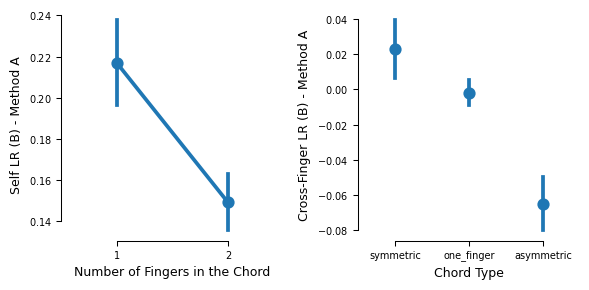

In [11]:
# Method C versions of the two summary plots
fig, axs = plt.subplots(1, 2, figsize=(6, 3))
grouped_data = betas_A.groupby(['subNum', 'num_fingers']).agg({
    'mean_B_diag': 'mean',
}).reset_index()
# sns.pointplot(data= betas_A, x='num_fingers', y='mean_B_diag', errorbar='se', ax=axs[0])
sns.pointplot(data= grouped_data, x='num_fingers', y='mean_B_diag', errorbar='se', ax=axs[0])
# sns.stripplot(data= grouped_data, x='num_fingers', y='mean_B_diag', ax=axs[0])
axs[0].set_xlabel('Number of Fingers in the Chord')
axs[0].set_ylabel('Self LR (B) - Method A')

grouped_data = betas_A.groupby(['subNum', 'chord_type']).agg({
    'mean_B_off_diag': 'mean',
}).reset_index().sort_values('mean_B_off_diag', ascending = False)

sns.pointplot(data= grouped_data, x='chord_type', y='mean_B_off_diag', errorbar='se',
              linestyle=' ', ax=axs[1])
axs[1].set_xlabel('Chord Type')
axs[1].set_ylabel('Cross-Finger LR (B) - Method A')
sns.despine(trim=True)
plt.tight_layout()
plt.show()

In [12]:
grouped_data = betas_A.groupby(['subNum', 'num_fingers']).agg({
    'mean_B_diag': 'mean',
}).reset_index()
grouped_data.sort_values(by = 'subNum')

,subNum,num_fingers,mean_B_diag
0,2,1,0.25750
1,2,2,0.14375
2,3,1,0.25250
3,3,2,0.26375
4,4,1,0.31000
5,4,2,0.15500
6,5,1,0.24000
7,5,2,0.14625
8,6,1,0.20000
9,6,2,0.17875


Paired t-test between one finger and two fingers: t = 3.321, p = 0.005, df = 15


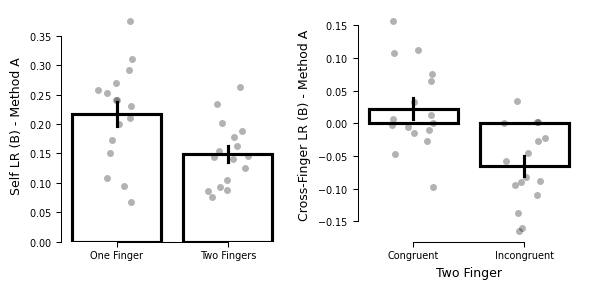

Sample t-test against 0 for congruent: t = 1.390, p = 0.185, df = 15
Sample t-test against 0 for incongruent: t = -4.269, p = 0.001, df = 15


In [13]:
# Method C versions of the two summary plots
fig, axs = plt.subplots(1, 2, figsize=(6, 3))
grouped_data = betas_A.groupby(['subNum', 'num_fingers']).agg({
    'mean_B_diag': 'mean',
}).reset_index().sort_values(by = ['subNum', 'num_fingers'])
# sns.pointplot(data= betas_A, x='num_fingers', y='mean_B_diag', errorbar='se', ax=axs[0])
# sns.pointplot(data= grouped_data, x='num_fingers', y='mean_B_diag', errorbar='se', ax=axs[0])
sns.barplot(data= grouped_data, x='num_fingers', y='mean_B_diag', ax=axs[0], fill = False, color = 'black', errorbar = 'se')
sns.stripplot(data= grouped_data, x='num_fingers', y='mean_B_diag', ax=axs[0], color = 'black', jitter = 0.2, alpha = 0.3)
axs[0].set_xlabel('')
axs[0].set_ylabel('Self LR (B) - Method A')
axs[0].set_xticks([0,1], ['One Finger', 'Two Fingers'])

# statistical test 
# paired t-test between one finger and two fingers
one_finger = grouped_data[grouped_data['num_fingers'] == 1]['mean_B_diag']
two_fingers = grouped_data[grouped_data['num_fingers'] == 2]['mean_B_diag']
result = stats.ttest_rel(one_finger, two_fingers)
print(f"Paired t-test between one finger and two fingers: t = {result.statistic:.3f}, p = {result.pvalue:.3f}, df = {result.df}")



grouped_data = betas_A.groupby(['subNum', 'chord_type']).agg({
    'mean_B_off_diag': 'mean',
}).reset_index().sort_values('mean_B_off_diag', ascending = False)
# filter out the one finger data
grouped_data = grouped_data[grouped_data['chord_type'] != 'one_finger']

# sns.pointplot(data= grouped_data, x='chord_type', y='mean_B_off_diag', errorbar='se',
#               linestyle=' ', ax=axs[1])
sns.barplot(data= grouped_data, x='chord_type', y='mean_B_off_diag', ax=axs[1], fill = False, color = 'black', errorbar = 'se')
sns.stripplot(data= grouped_data, x='chord_type', y='mean_B_off_diag', ax=axs[1], color = 'black', jitter = 0.2, alpha = 0.3)
axs[1].set_xlabel('Two Finger')
axs[1].set_ylabel('Cross-Finger LR (B) - Method A')
axs[1].set_xticks([0,1], ['Congruent', 'Incongruent'])
sns.despine(trim=True)
plt.tight_layout()
plt.show()

# statistical test 
# sample t-test against 0 for congruent and incongruent
congruent = grouped_data[grouped_data['chord_type'] == 'symmetric']['mean_B_off_diag']
incongruent = grouped_data[grouped_data['chord_type'] == 'asymmetric']['mean_B_off_diag']
result = stats.ttest_1samp(congruent, 0)
print(f"Sample t-test against 0 for congruent: t = {result.statistic:.3f}, p = {result.pvalue:.3f}, df = {result.df}")
result = stats.ttest_1samp(incongruent, 0)
print(f"Sample t-test against 0 for incongruent: t = {result.statistic:.3f}, p = {result.pvalue:.3f}, df = {result.df}")


Paired t-test between one finger and two fingers: t = 3.321, p = 0.005, df = 15


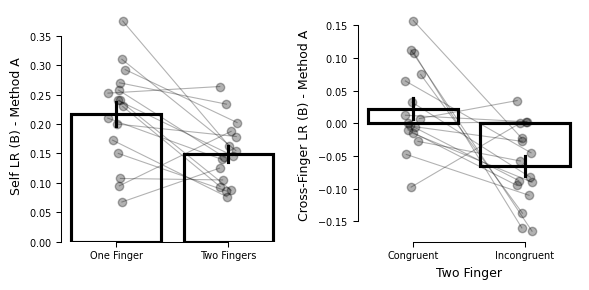

Sample t-test against 0 for congruent: t = 1.390, p = 0.185, df = 15
Sample t-test against 0 for incongruent: t = -4.269, p = 0.001, df = 15


In [14]:
# Same plot as above, with within-participant connections
fig, axs = plt.subplots(1, 2, figsize=(6, 3))
rng = np.random.default_rng(0)
jitter = 0.08

def plot_connected_participants(ax, data, x_col, y_col, x_order):
    """Scatter + lines so each participant's points are connected."""
    for _, sub_df in data.groupby('subNum'):
        sub_df = sub_df.drop_duplicates(x_col).set_index(x_col).reindex(x_order)
        xs = np.arange(len(x_order), dtype=float) + rng.uniform(-jitter, jitter, size=len(x_order))
        ys = sub_df[y_col].to_numpy()
        ax.plot(xs, ys, color='black', alpha=0.3, linewidth=0.8, zorder=2)
        ax.scatter(xs, ys, color='black', alpha=0.3, zorder=3)

grouped_data = betas_A.groupby(['subNum', 'num_fingers']).agg({
    'mean_B_diag': 'mean',
}).reset_index().sort_values(by=['subNum', 'num_fingers'])

sns.barplot(data=grouped_data, x='num_fingers', y='mean_B_diag', ax=axs[0],
            fill=False, color='black', errorbar='se', zorder=1)
plot_connected_participants(axs[0], grouped_data, 'num_fingers', 'mean_B_diag', [1, 2])
axs[0].set_xlabel('')
axs[0].set_ylabel('Self LR (B) - Method A')
axs[0].set_xticks([0, 1], ['One Finger', 'Two Fingers'])

# statistical test
# paired t-test between one finger and two fingers
one_finger = grouped_data[grouped_data['num_fingers'] == 1]['mean_B_diag']
two_fingers = grouped_data[grouped_data['num_fingers'] == 2]['mean_B_diag']
result = stats.ttest_rel(one_finger, two_fingers)
print(f"Paired t-test between one finger and two fingers: t = {result.statistic:.3f}, p = {result.pvalue:.3f}, df = {result.df}")


grouped_data = betas_A.groupby(['subNum', 'chord_type']).agg({
    'mean_B_off_diag': 'mean',
}).reset_index().sort_values('mean_B_off_diag', ascending=False)
# filter out the one finger data
grouped_data = grouped_data[grouped_data['chord_type'] != 'one_finger']
chord_order = ['symmetric', 'asymmetric']

sns.barplot(data=grouped_data, x='chord_type', y='mean_B_off_diag', ax=axs[1],
            fill=False, color='black', errorbar='se', order=chord_order, zorder=1)
plot_connected_participants(axs[1], grouped_data, 'chord_type', 'mean_B_off_diag', chord_order)
axs[1].set_xlabel('Two Finger')
axs[1].set_ylabel('Cross-Finger LR (B) - Method A')
axs[1].set_xticks([0, 1], ['Congruent', 'Incongruent'])
sns.despine(trim=True)
plt.tight_layout()
plt.show()

# statistical test
# sample t-test against 0 for congruent and incongruent
congruent = grouped_data[grouped_data['chord_type'] == 'symmetric']['mean_B_off_diag']
incongruent = grouped_data[grouped_data['chord_type'] == 'asymmetric']['mean_B_off_diag']
result = stats.ttest_1samp(congruent, 0)
print(f"Sample t-test against 0 for congruent: t = {result.statistic:.3f}, p = {result.pvalue:.3f}, df = {result.df}")
result = stats.ttest_1samp(incongruent, 0)
print(f"Sample t-test against 0 for incongruent: t = {result.statistic:.3f}, p = {result.pvalue:.3f}, df = {result.df}")


Paired t-test between one finger and two fingers: t = 3.321, p = 0.005, df = 15


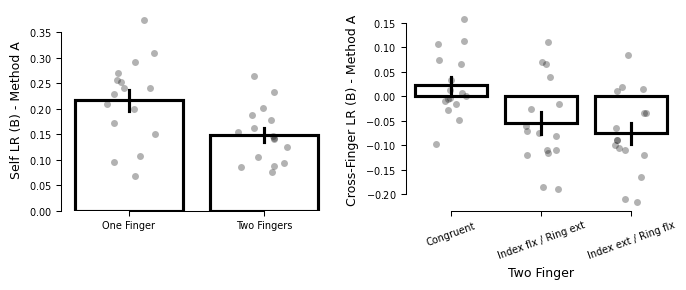

t-test against 0 for Congruent: t = 1.390, p = 0.185, df = 15
t-test against 0 for Index flx / Ring ext: t = -2.441, p = 0.027, df = 15
t-test against 0 for Index ext / Ring flx: t = -3.626, p = 0.002, df = 15
Paired t-test between incongruent directions: t = 0.695, p = 0.498, df = 15


In [15]:
# Same plot, splitting incongruent chords into the two directions
def incongruent_kind(row):
    if row['num_fingers'] != 2 or row['chord_type'] != 'asymmetric':
        return row['chord_type']
    index_action = row['chord'][1]
    ring_action = row['chord'][3]
    if index_action == 'v' and ring_action == '^':
        return 'index_flx_ring_ext'
    if index_action == '^' and ring_action == 'v':
        return 'index_ext_ring_flx'
    return 'asymmetric'

plot_df = betas_A.copy()
plot_df['incongruent_kind'] = plot_df.apply(incongruent_kind, axis=1)

fig, axs = plt.subplots(1, 2, figsize=(7, 3))
grouped_data = plot_df.groupby(['subNum', 'num_fingers']).agg({
    'mean_B_diag': 'mean',
}).reset_index().sort_values(by=['subNum', 'num_fingers'])
sns.barplot(data=grouped_data, x='num_fingers', y='mean_B_diag', ax=axs[0],
            fill=False, color='black', errorbar='se')
sns.stripplot(data=grouped_data, x='num_fingers', y='mean_B_diag', ax=axs[0],
              color='black', jitter=0.2, alpha=0.3)
axs[0].set_xlabel('')
axs[0].set_ylabel('Self LR (B) - Method A')
axs[0].set_xticks([0, 1], ['One Finger', 'Two Fingers'])

# statistical test
one_finger = grouped_data[grouped_data['num_fingers'] == 1]['mean_B_diag']
two_fingers = grouped_data[grouped_data['num_fingers'] == 2]['mean_B_diag']
result = stats.ttest_rel(one_finger, two_fingers)
print(f"Paired t-test between one finger and two fingers: t = {result.statistic:.3f}, p = {result.pvalue:.3f}, df = {result.df}")


chord_order = ['symmetric', 'index_flx_ring_ext', 'index_ext_ring_flx']
chord_labels = {
    'symmetric': 'Congruent',
    'index_flx_ring_ext': 'Index flx / Ring ext',
    'index_ext_ring_flx': 'Index ext / Ring flx',
}
grouped_data = plot_df.groupby(['subNum', 'incongruent_kind']).agg({
    'mean_B_off_diag': 'mean',
}).reset_index()
grouped_data = grouped_data[grouped_data['incongruent_kind'].isin(chord_order)]

sns.barplot(data=grouped_data, x='incongruent_kind', y='mean_B_off_diag', ax=axs[1],
            fill=False, color='black', errorbar='se', order=chord_order)
sns.stripplot(data=grouped_data, x='incongruent_kind', y='mean_B_off_diag', ax=axs[1],
              color='black', jitter=0.2, alpha=0.3, order=chord_order)
axs[1].set_xlabel('Two Finger')
axs[1].set_ylabel('Cross-Finger LR (B) - Method A')
axs[1].set_xticks(range(len(chord_order)), [chord_labels[c] for c in chord_order])
axs[1].tick_params(axis='x', rotation=20)
sns.despine(trim=True)
plt.tight_layout()
plt.show()

# statistical tests against 0
for kind in chord_order:
    vals = grouped_data[grouped_data['incongruent_kind'] == kind]['mean_B_off_diag']
    result = stats.ttest_1samp(vals, 0)
    print(f"t-test against 0 for {chord_labels[kind]}: t = {result.statistic:.3f}, p = {result.pvalue:.3f}, df = {result.df}")

flx_ext = grouped_data[grouped_data['incongruent_kind'] == 'index_flx_ring_ext']['mean_B_off_diag']
ext_flx = grouped_data[grouped_data['incongruent_kind'] == 'index_ext_ring_flx']['mean_B_off_diag']
result = stats.ttest_rel(flx_ext, ext_flx)
print(f"Paired t-test between incongruent directions: t = {result.statistic:.3f}, p = {result.pvalue:.3f}, df = {result.df}")


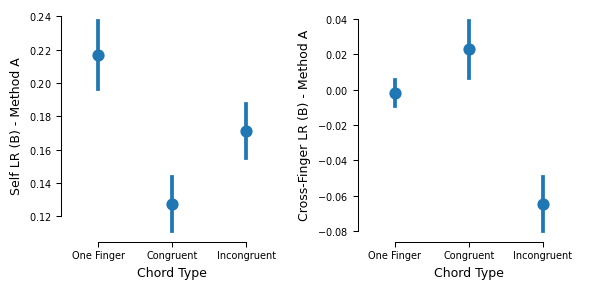

In [17]:
# Method C versions of the two summary plots
fig, axs = plt.subplots(1, 2, figsize=(6, 3))
label_orders = ['one_finger', 'symmetric', 'asymmetric']
order_map = {label: i for i, label in enumerate(label_orders)}
label_names = {
    'one_finger': 'One Finger',
    'symmetric': 'Congruent',
    'asymmetric': 'Incongruent',
}
grouped_data = betas_A.groupby(['subNum', 'chord_type']).agg({
    'mean_B_diag': 'mean',
}).reset_index().sort_values('chord_type', key=lambda x: x.map(order_map))
# sns.pointplot(data= betas_A, x='num_fingers', y='mean_B_diag', errorbar='se', ax=axs[0])
sns.pointplot(data= grouped_data, x='chord_type', y='mean_B_diag', errorbar='se', ax=axs[0], linestyle = ' ')
# sns.stripplot(data= grouped_data, x='num_fingers', y='mean_B_diag', ax=axs[0])
axs[0].set_xlabel('Chord Type')
axs[0].set_ylabel('Self LR (B) - Method A')
axs[0].set_xticks(range(len(label_orders)))
axs[0].set_xticklabels([label_names[label] for label in label_orders])


grouped_data = betas_A.groupby(['subNum', 'chord_type']).agg({
    'mean_B_off_diag': 'mean',
}).reset_index().sort_values('chord_type', key=lambda x: x.map(order_map))

sns.pointplot(data= grouped_data, x='chord_type', y='mean_B_off_diag', errorbar='se',
              linestyle=' ', ax=axs[1])
axs[1].set_xlabel('Chord Type')
axs[1].set_ylabel('Cross-Finger LR (B) - Method A')
axs[1].set_xticks(range(len(label_orders)))
axs[1].set_xticklabels([label_names[label] for label in label_orders])
sns.despine(trim=True)
plt.tight_layout()
plt.show()

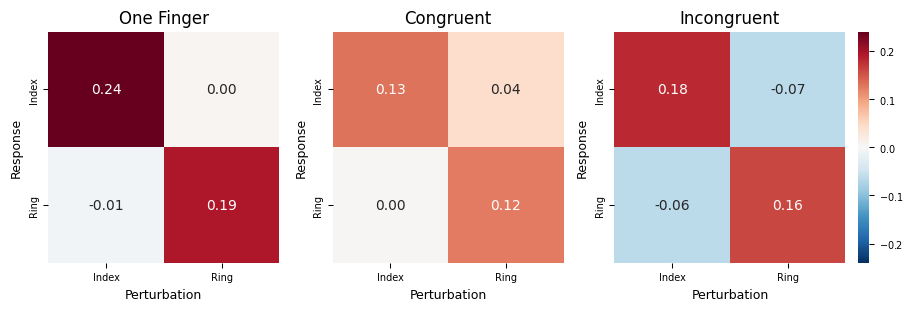

In [18]:
grouped_data = betas_A.groupby(['subNum', 'chord_type']).agg({
    'B11': 'mean',
    'B12': 'mean',
    'B21': 'mean',
    'B22': 'mean',
}).reset_index()

# average across subjects
group_mean = grouped_data.groupby('chord_type')[['B11', 'B12', 'B21', 'B22']].mean()

chord_types = ['one_finger', 'symmetric', 'asymmetric']
finger_labels = ['Index', 'Ring']
chord_type_names = {
    'one_finger': 'One Finger',
    'symmetric': 'Congruent',
    'asymmetric': 'Incongruent',
}

def to_B_matrix(row):
    return np.array([
        [row['B11'], row['B12']],
        [row['B21'], row['B22']],
    ])

# shared color scale across all 3 heatmaps
vals = group_mean.loc[chord_types].values
vlim = np.nanmax(np.abs(vals))

fig, axs = plt.subplots(1, 3, figsize=(9, 3), constrained_layout=True)

for ax, chord_type in zip(axs, chord_types):
    B = to_B_matrix(group_mean.loc[chord_type])

    sns.heatmap(
        B,
        ax=ax,
        annot=True,
        fmt='.2f',
        cmap='RdBu_r',
        center=0,
        vmin=-vlim,
        vmax=vlim,
        xticklabels=finger_labels,
        yticklabels=finger_labels,
        cbar=ax is axs[-1],
        square=True,
    )
    ax.set_title(chord_type_names[chord_type].replace('_', ' ').title())
    ax.set_ylabel('Response')
    ax.set_xlabel('Perturbation')

plt.show()

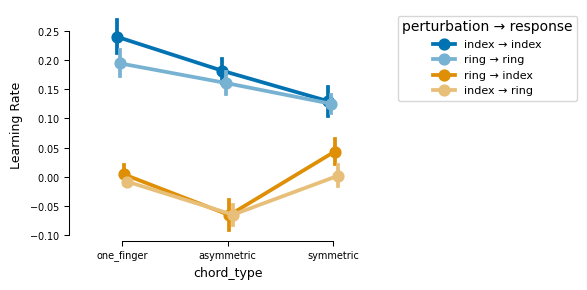

In [20]:
melted_data = grouped_data.melt(
    id_vars=['chord_type', 'subNum'],
    value_vars=['B11', 'B12', 'B21', 'B22'],
    value_name='Learning Rate',
    var_name='parameter',
)

label_map = {
    'B11': 'index → index',
    'B12': 'ring → index',
    'B21': 'index → ring',
    'B22': 'ring → ring',
}

melted_data['parameter'] = melted_data['parameter'].map(label_map)


cb = sns.color_palette('colorblind')
diag_shades = sns.light_palette(cb[0], n_colors=3)
offdiag_shades = sns.light_palette(cb[1], n_colors=3)

palette = {
    label_map['B11']: diag_shades[2],
    label_map['B22']: diag_shades[1],
    label_map['B12']: offdiag_shades[2],
    label_map['B21']: offdiag_shades[1],
}

hue_order = [
    label_map['B11'],
    label_map['B22'],
    label_map['B12'],
    label_map['B21'],
]

label_map = {'one_finger': 0, 'asymmetric': 1, 'symmetric': 2}

melted_data.sort_values('chord_type', key=lambda x: x.map(label_map), inplace=True)

plt.figure(figsize=(6, 3))
sns.pointplot(
    data=melted_data,
    x='chord_type',
    y='Learning Rate',
    hue='parameter',
    hue_order=hue_order,
    palette=palette,
    errorbar='se',
    dodge=True,
)
sns.despine(trim=True)
plt.legend(title='perturbation → response', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

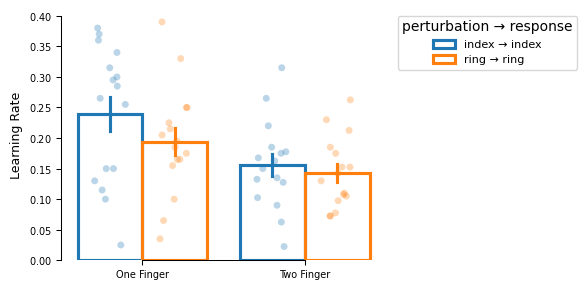

In [21]:
grouped_data = betas_A.groupby(['subNum', 'num_fingers']).agg({
    'B11': 'mean',
    'B12': 'mean',
    'B21': 'mean',
    'B22': 'mean',
}).reset_index()

melted_data = grouped_data.melt(
    id_vars=['num_fingers', 'subNum'],
    value_vars=['B11', 'B12', 'B21', 'B22'],
    value_name='Learning Rate',
    var_name='parameter',
)

label_map = {
    'B11': 'index → index',
    'B12': 'ring → index',
    'B21': 'index → ring',
    'B22': 'ring → ring',
}

chord_type_map = {
    1: 'One Finger',
    2: 'Two Finger',
}

melted_data['parameter'] = melted_data['parameter'].map(label_map)

melted_data['num_fingers'] = melted_data['num_fingers'].map(chord_type_map)

# filter cross learning rate data
melted_data = melted_data[~melted_data['parameter'].isin(['ring → index', 'index → ring'])]



cb = sns.color_palette('colorblind')
diag_shades = sns.light_palette(cb[0], n_colors=3)
offdiag_shades = sns.light_palette(cb[1], n_colors=3)

# palette = {
#     label_map['B11']: diag_shades[2],
#     label_map['B22']: diag_shades[1],
#     label_map['B12']: offdiag_shades[2],
#     label_map['B21']: offdiag_shades[1],
# }

hue_order = [
    label_map['B11'],
    label_map['B22'],
    # label_map['B12'],
    # label_map['B21'],
]


melted_data.sort_values('num_fingers', key=lambda x: x.map(chord_type_map), inplace=True)

plt.figure(figsize=(6, 3))
# sns.pointplot(
#     data=melted_data,
#     x='chord_type',
#     y='Learning Rate',
#     hue='parameter',
#     hue_order=hue_order,
#     # palette=palette,
#     errorbar='se',
#     dodge=True,
# )
sns.barplot(
    data=melted_data,
    x='num_fingers',
    y='Learning Rate',
    hue='parameter',
    hue_order=hue_order,
    # palette=palette,
    fill = False,
    errorbar = 'se',
)
sns.stripplot(
    data=melted_data,
    x='num_fingers',
    y='Learning Rate',
    hue='parameter',
    hue_order=hue_order,
    # palette=palette,
    alpha = 0.3,
    dodge = True,
    jitter = 0.2,
    legend = False,
)
plt.xlabel('')
sns.despine(trim=True)
plt.legend(title='perturbation → response', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

In [22]:
def is_flex_ext_or_both(row):
    num_fingers = row['num_fingers']
    chord = row['chord']
    index_action = chord[1]
    ring_action = chord[3]
    # print(chord)
    # print(index_action, ring_action)
    mapping = {
        '^': 'extension',
        'v': 'flexion',
        '-': 'rest',
    }
    index_action = mapping[index_action]
    ring_action = mapping[ring_action]
    if num_fingers == 1:
        if index_action == 'flexion' or ring_action == 'flexion':
            return 'one_finger_flexion'
        elif index_action == 'extension' or ring_action == 'extension':
            return 'one_finger_extension'

    elif num_fingers == 2:
        if index_action == 'flexion' and ring_action == 'flexion':
            return 'congruent_flexion'
        elif index_action == 'extension' and ring_action == 'extension':
            return 'congruent_extension'
        else:
            return 'incongruent'
            

In [23]:
betas_A['flex_ext_or_both'] = betas_A.apply(is_flex_ext_or_both, axis = 1)

In [24]:
betas_A

,subNum,chord,num_fingers,B11,B12,B21,B22,mean_B_diag,mean_B_off_diag,chord_type,flex_ext_or_both
0,2,---^-,1,NaN,0.01,NaN,0.10,0.100,0.010,one_finger,one_finger_extension
1,2,---v-,1,NaN,-0.03,NaN,0.25,0.250,-0.030,one_finger,one_finger_flexion
2,2,-^---,1,0.32,NaN,-0.01,NaN,0.320,-0.010,one_finger,one_finger_extension
3,2,-^-^-,2,0.18,-0.09,-0.12,0.06,0.120,-0.105,symmetric,congruent_extension
4,2,-^-v-,2,-0.06,-0.03,-0.17,0.14,0.040,-0.100,asymmetric,incongruent
...,...,...,...,...,...,...,...,...,...,...,...
123,18,-^-^-,2,0.50,-0.03,-0.05,0.06,0.280,-0.040,symmetric,congruent_extension
124,18,-^-v-,2,0.27,-0.16,0.03,0.15,0.210,-0.065,asymmetric,incongruent
125,18,-v---,1,0.36,NaN,-0.04,NaN,0.360,-0.040,one_finger,one_finger_flexion
126,18,-v-^-,2,0.33,0.12,0.02,0.28,0.305,0.070,asymmetric,incongruent


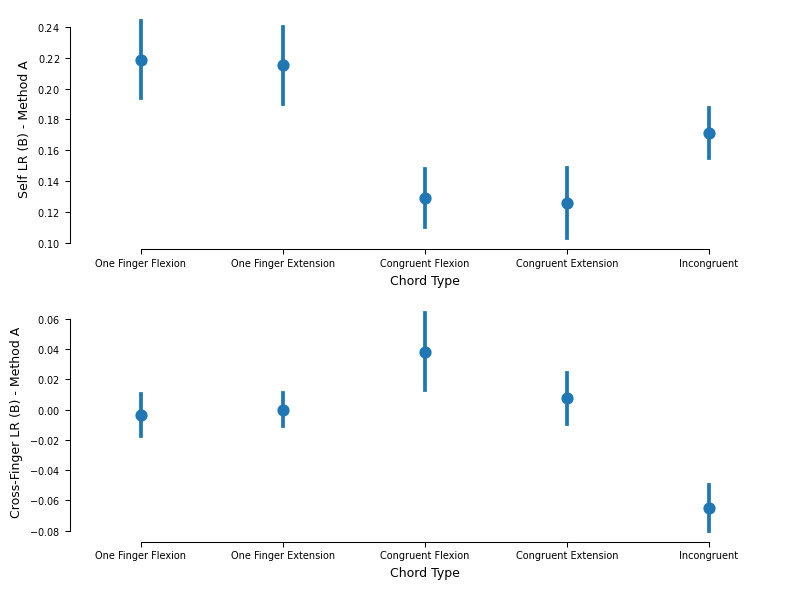

In [25]:
# Method C versions of the two summary plots
fig, axs = plt.subplots(2, 1, figsize=(8, 6))
# label_orders = ['one_finger', 'symmetric', 'asymmetric']
label_orders = ['one_finger_flexion', 'one_finger_extension', 'congruent_flexion', 'congruent_extension', 'incongruent']
label_names = {
    'one_finger_flexion': 'One Finger Flexion',
    'one_finger_extension': 'One Finger Extension',
    'congruent_flexion': 'Congruent Flexion',
    'congruent_extension': 'Congruent Extension',
    'incongruent': 'Incongruent',
}
order_map = {label: i for i, label in enumerate(label_orders)}
grouped_data = betas_A.groupby(['subNum', 'flex_ext_or_both']).agg({
    'mean_B_diag': 'mean',
}).reset_index().sort_values('flex_ext_or_both', key=lambda x: x.map(order_map))
# sns.pointplot(data= betas_A, x='num_fingers', y='mean_B_diag', errorbar='se', ax=axs[0])
sns.pointplot(data= grouped_data, x='flex_ext_or_both', y='mean_B_diag', errorbar='se', ax=axs[0], linestyle = ' ')
# sns.stripplot(data= grouped_data, x='num_fingers', y='mean_B_diag', ax=axs[0])
axs[0].set_xlabel('Chord Type')
axs[0].set_ylabel('Self LR (B) - Method A')
axs[0].set_xticks(range(len(label_orders)))
axs[0].set_xticklabels([label_names[label] for label in label_orders])

grouped_data = betas_A.groupby(['subNum', 'flex_ext_or_both']).agg({
    'mean_B_off_diag': 'mean',
}).reset_index().sort_values('flex_ext_or_both', key=lambda x: x.map(order_map))

sns.pointplot(data= grouped_data, x='flex_ext_or_both', y='mean_B_off_diag', errorbar='se',
              linestyle=' ', ax=axs[1])
axs[1].set_xlabel('Chord Type')
axs[1].set_ylabel('Cross-Finger LR (B) - Method A')
axs[1].set_xticks(range(len(label_orders)))
axs[1].set_xticklabels([label_names[label] for label in label_orders])
sns.despine(trim=True)
plt.tight_layout()
plt.show()

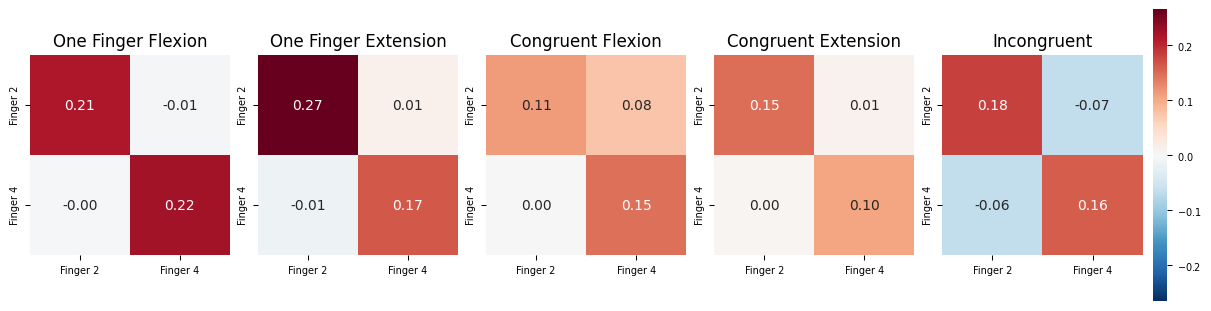

In [26]:
grouped_data = betas_A.groupby(['subNum', 'flex_ext_or_both']).agg({
    'B11': 'mean',
    'B12': 'mean',
    'B21': 'mean',
    'B22': 'mean',
}).reset_index()

# average across subjects
group_mean = grouped_data.groupby('flex_ext_or_both')[['B11', 'B12', 'B21', 'B22']].mean()

# chord_types = ['one_finger', 'symmetric', 'asymmetric']
chord_types = ['one_finger_flexion', 'one_finger_extension', 'congruent_flexion', 'congruent_extension', 'incongruent']
finger_labels = ['Finger 2', 'Finger 4']

def to_B_matrix(row):
    return np.array([
        [row['B11'], row['B12']],
        [row['B21'], row['B22']],
    ])

# shared color scale across all 3 heatmaps
vals = group_mean.loc[chord_types].values
vlim = np.nanmax(np.abs(vals))

fig, axs = plt.subplots(1, 5, figsize=(12, 3), constrained_layout=True)

for ax, chord_type in zip(axs, chord_types):
    B = to_B_matrix(group_mean.loc[chord_type])

    sns.heatmap(
        B,
        ax=ax,
        annot=True,
        fmt='.2f',
        cmap='RdBu_r',
        center=0,
        vmin=-vlim,
        vmax=vlim,
        xticklabels=finger_labels,
        yticklabels=finger_labels,
        cbar=ax is axs[-1],
        square=True,
    )
    ax.set_title(chord_type.replace('_', ' ').title())
    # ax.set_xlabel('Perturbation')
    # ax.set_ylabel('Response')

plt.show()

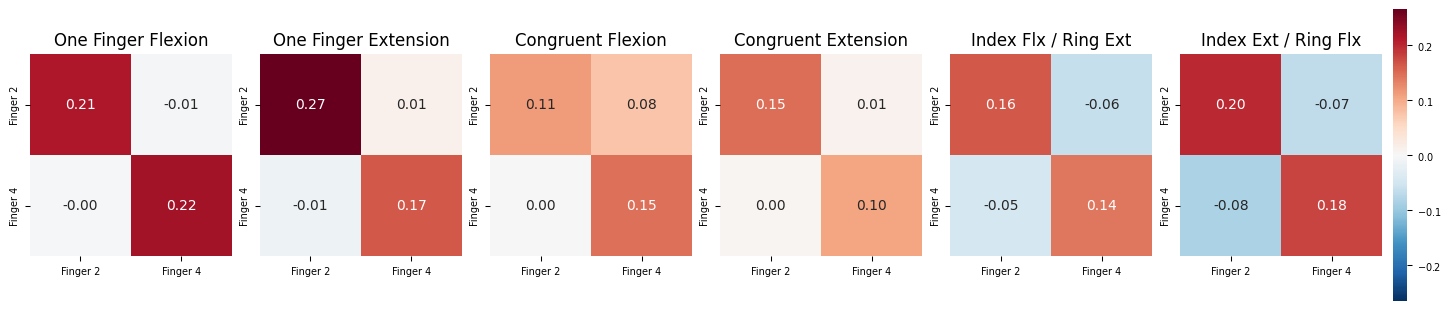

In [27]:
plot_df = betas_A.copy()

def flex_ext_split_incongruent(row):
    label = row['flex_ext_or_both']
    if label != 'incongruent':
        return label
    index_action = row['chord'][1]
    ring_action = row['chord'][3]
    if index_action == 'v' and ring_action == '^':
        return 'index_flx_ring_ext'
    if index_action == '^' and ring_action == 'v':
        return 'index_ext_ring_flx'
    return 'incongruent'

plot_df['flex_ext_split'] = plot_df.apply(flex_ext_split_incongruent, axis=1)

grouped_data = plot_df.groupby(['subNum', 'flex_ext_split']).agg({
    'B11': 'mean',
    'B12': 'mean',
    'B21': 'mean',
    'B22': 'mean',
}).reset_index()

# average across subjects
group_mean = grouped_data.groupby('flex_ext_split')[['B11', 'B12', 'B21', 'B22']].mean()

chord_types = [
    'one_finger_flexion',
    'one_finger_extension',
    'congruent_flexion',
    'congruent_extension',
    'index_flx_ring_ext',
    'index_ext_ring_flx',
]
chord_type_names = {
    'one_finger_flexion': 'One Finger Flexion',
    'one_finger_extension': 'One Finger Extension',
    'congruent_flexion': 'Congruent Flexion',
    'congruent_extension': 'Congruent Extension',
    'index_flx_ring_ext': 'Index Flx / Ring Ext',
    'index_ext_ring_flx': 'Index Ext / Ring Flx',
}
finger_labels = ['Finger 2', 'Finger 4']

def to_B_matrix(row):
    return np.array([
        [row['B11'], row['B12']],
        [row['B21'], row['B22']],
    ])

vals = group_mean.loc[chord_types].values
vlim = np.nanmax(np.abs(vals))

fig, axs = plt.subplots(1, 6, figsize=(14.4, 3), constrained_layout=True)

for ax, chord_type in zip(axs, chord_types):
    B = to_B_matrix(group_mean.loc[chord_type])

    sns.heatmap(
        B,
        ax=ax,
        annot=True,
        fmt='.2f',
        cmap='RdBu_r',
        center=0,
        vmin=-vlim,
        vmax=vlim,
        xticklabels=finger_labels,
        yticklabels=finger_labels,
        cbar=ax is axs[-1],
        square=True,
    )
    ax.set_title(chord_type_names[chord_type])

plt.show()


# Method B

processing subject 2, chord ---^-
Optimization terminated successfully.
         Current function value: 12.017213
         Iterations: 372
         Function evaluations: 556
processing subject 2, chord ---v-
Optimization terminated successfully.
         Current function value: 10.733068
         Iterations: 603
         Function evaluations: 884
processing subject 2, chord -^---
Optimization terminated successfully.
         Current function value: 9.375858
         Iterations: 668
         Function evaluations: 983
processing subject 2, chord -^-^-
Optimization terminated successfully.
         Current function value: 25.699985
         Iterations: 1470
         Function evaluations: 2144
processing subject 2, chord -^-v-
Optimization terminated successfully.
         Current function value: 32.654585
         Iterations: 1589
         Function evaluations: 2293
processing subject 2, chord -v---
Optimization terminated successfully.
         Current function value: 13.209418
       

/var/folders/wg/16zn32014z5grhdv06dk49f00000gn/T/ipykernel_91218/4050184284.py:102: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(1,2, figsize = (15,2), sharey = True)


processing subject 4, chord -v---
Optimization terminated successfully.
         Current function value: 27.614278
         Iterations: 457
         Function evaluations: 696
processing subject 4, chord -v-^-
Optimization terminated successfully.
         Current function value: 109.112195
         Iterations: 602
         Function evaluations: 901
processing subject 4, chord -v-v-
Optimization terminated successfully.
         Current function value: 130.965571
         Iterations: 684
         Function evaluations: 1009
processing subject 5, chord ---^-
Optimization terminated successfully.
         Current function value: 17.232371
         Iterations: 577
         Function evaluations: 865
processing subject 5, chord ---v-
Optimization terminated successfully.
         Current function value: 39.294584
         Iterations: 316
         Function evaluations: 491
processing subject 5, chord -^---
Optimization terminated successfully.
         Current function value: 15.376620
       

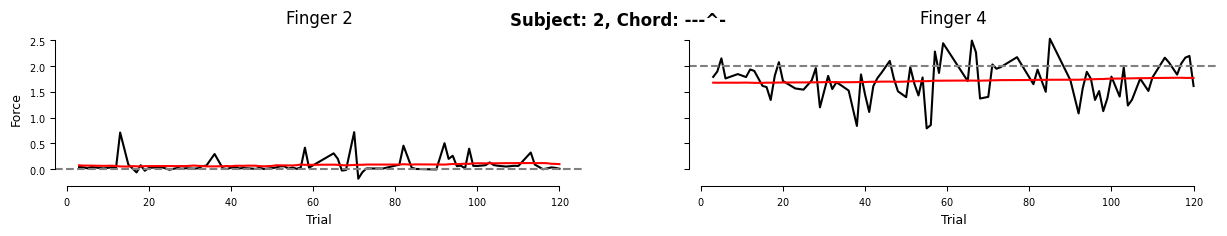

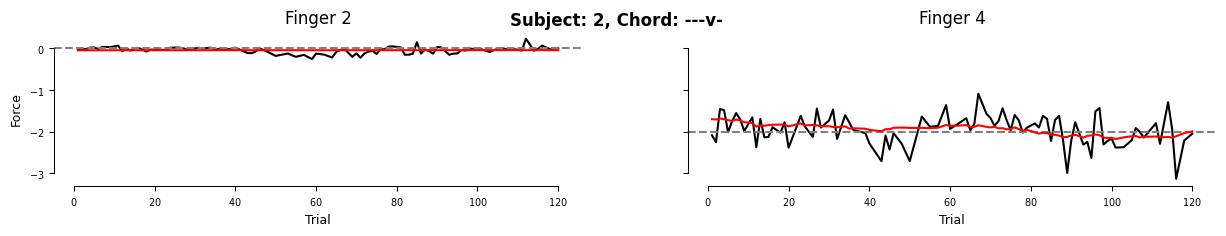

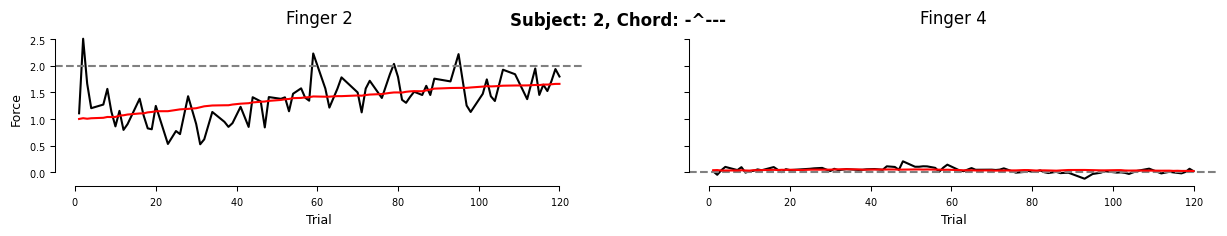

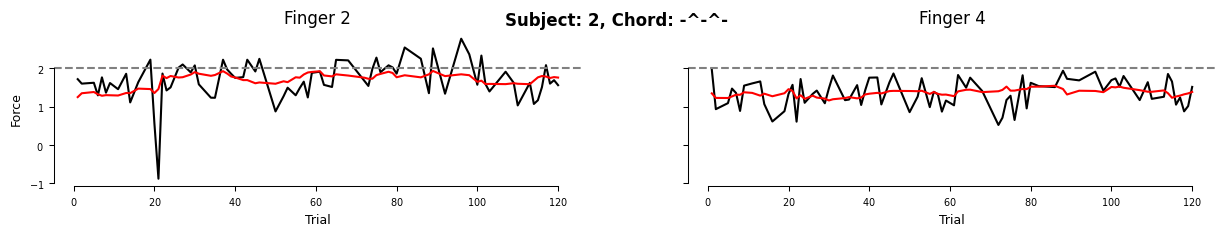

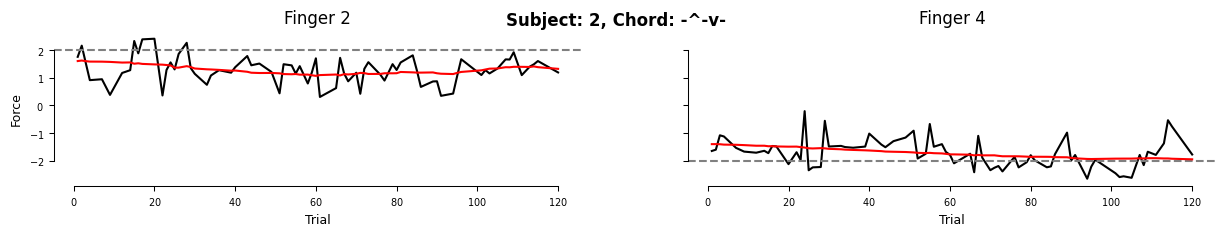

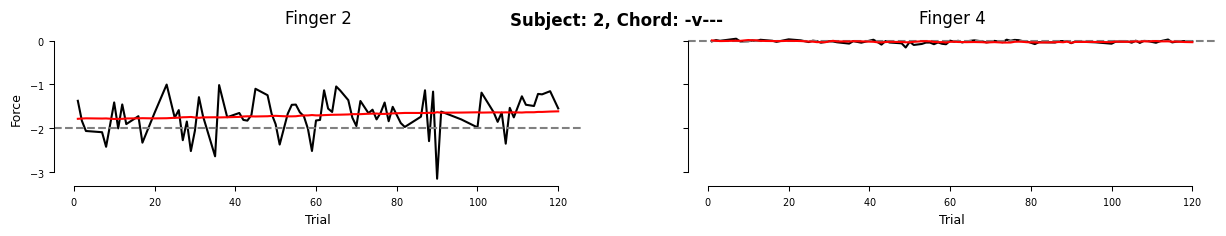

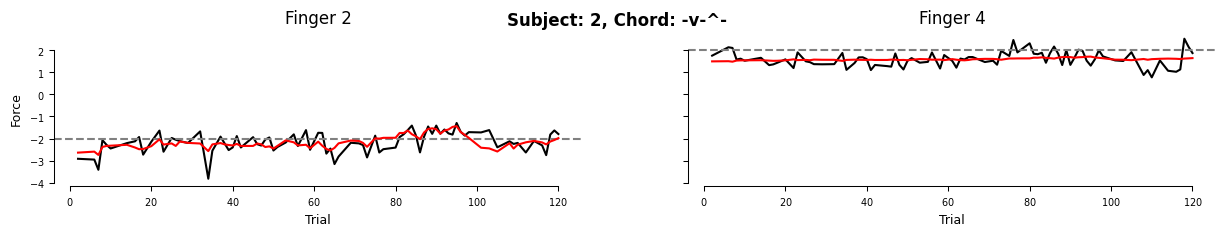

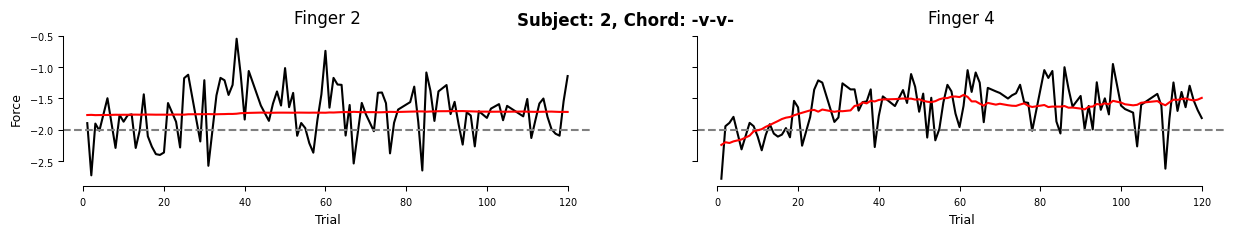

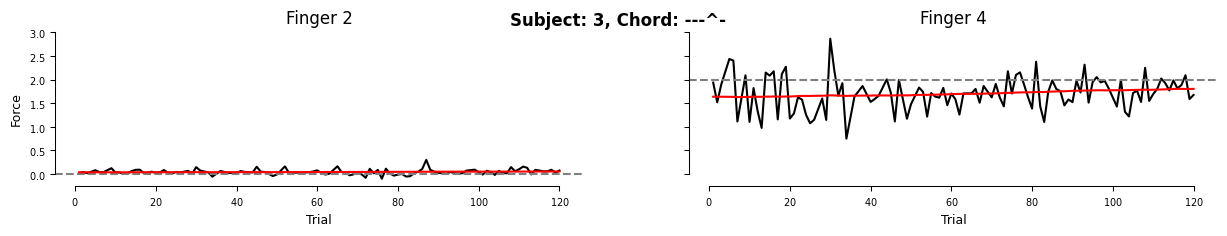

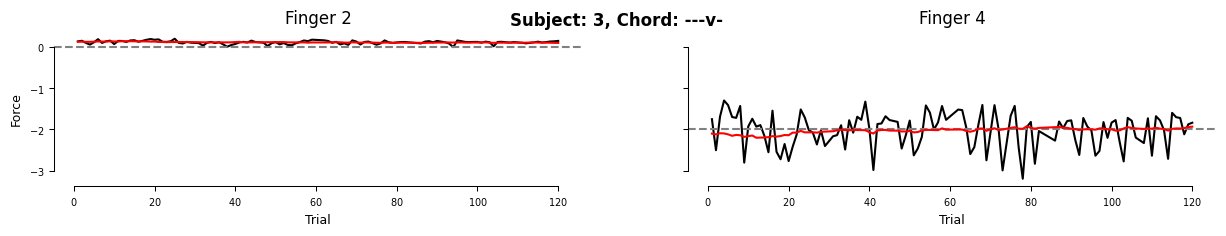

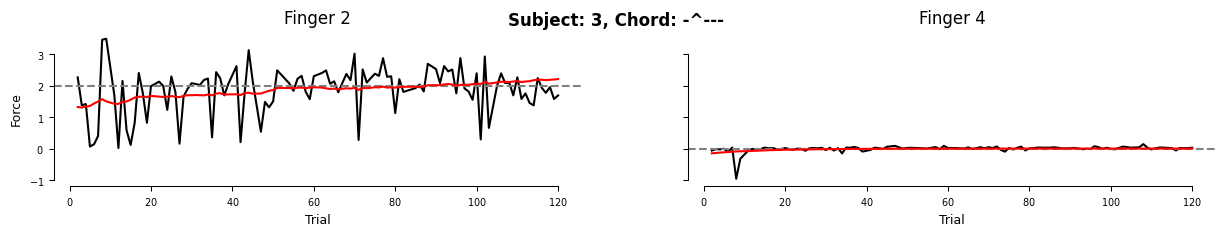

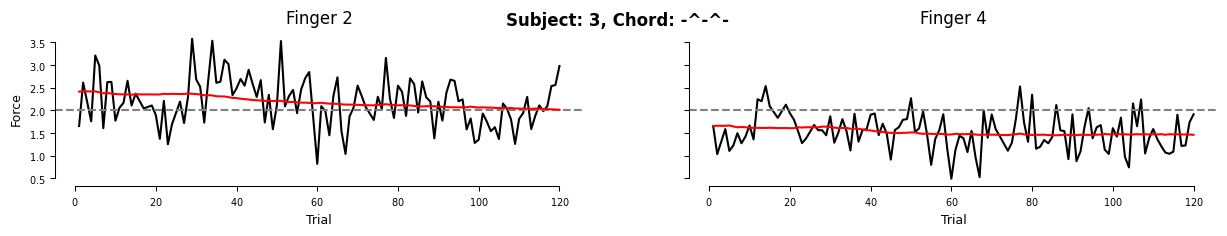

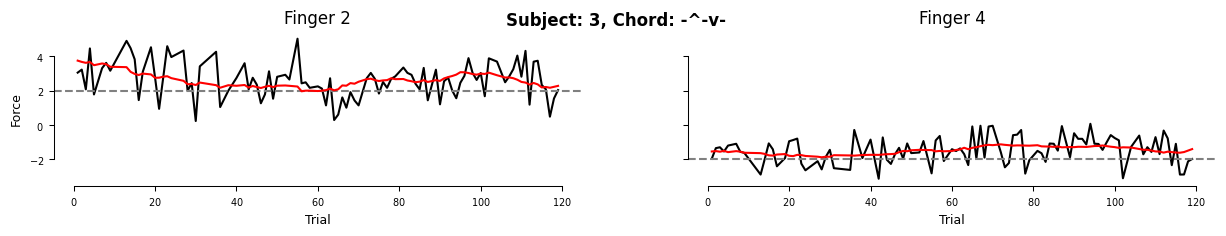

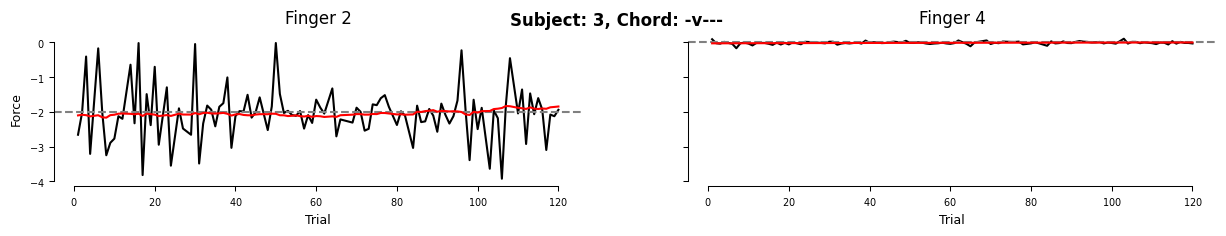

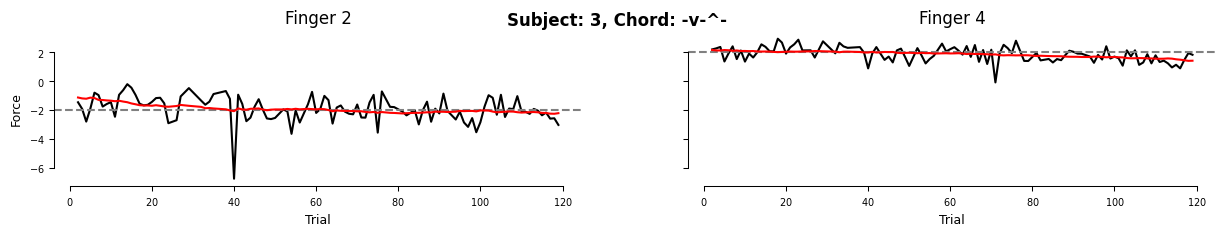

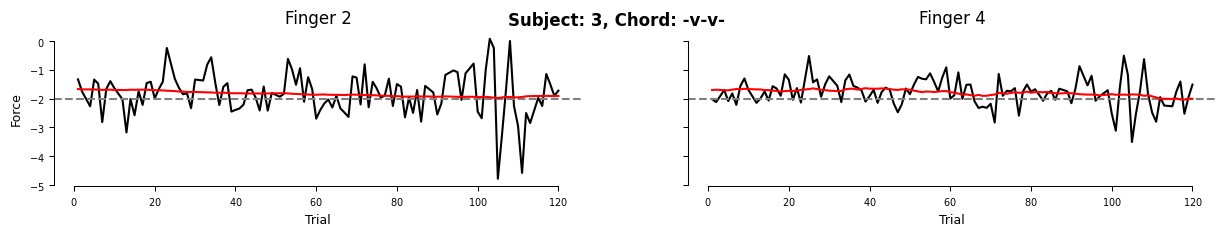

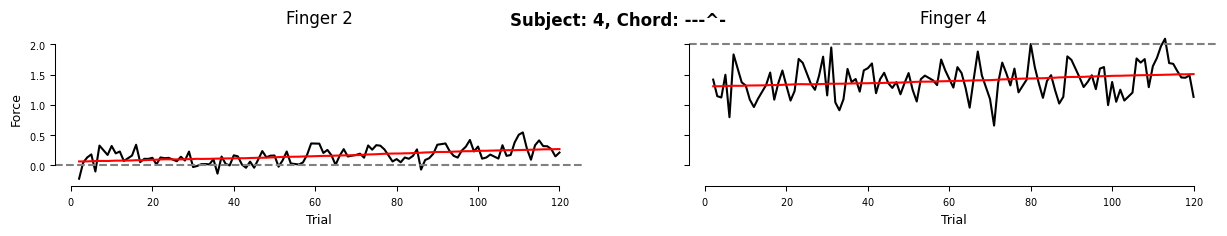

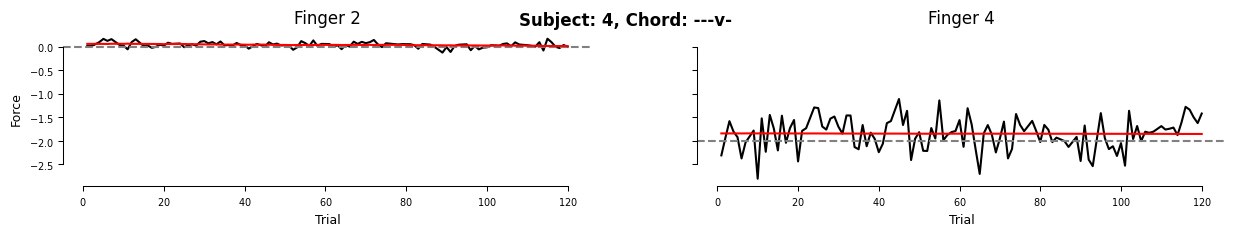

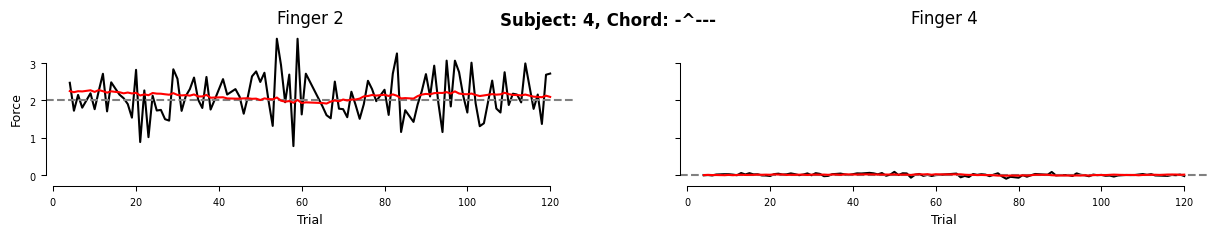

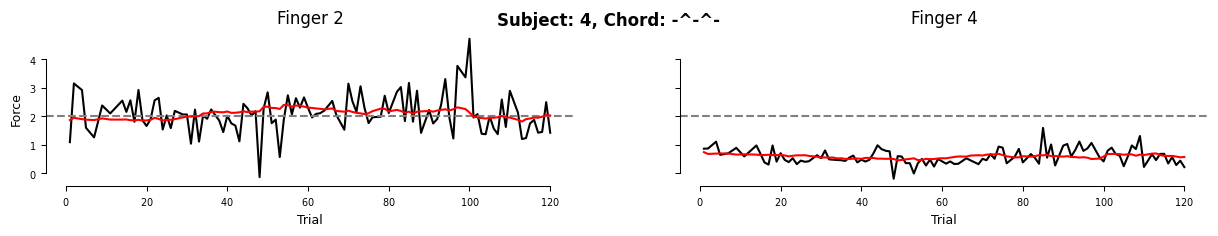

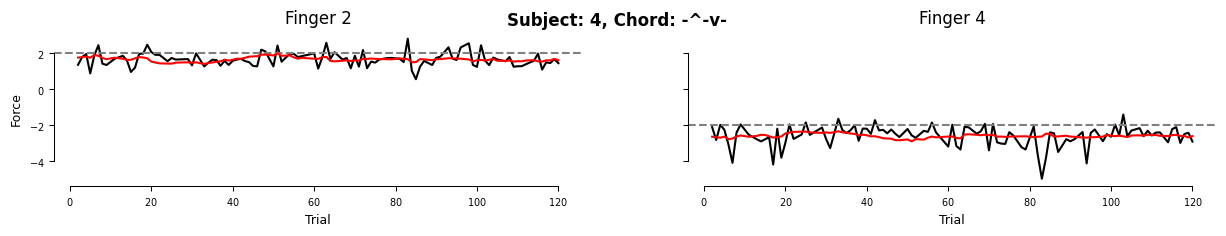

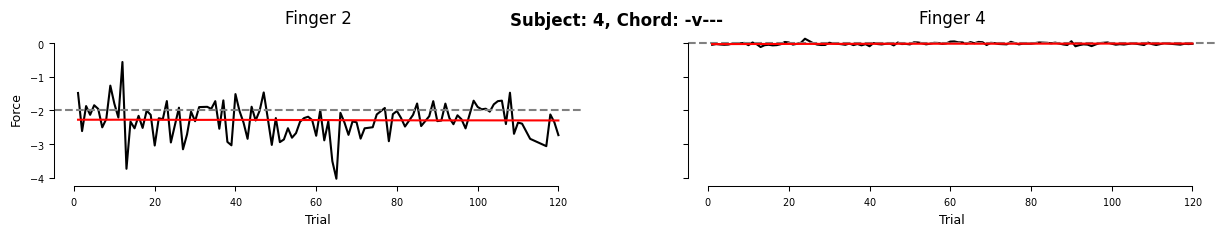

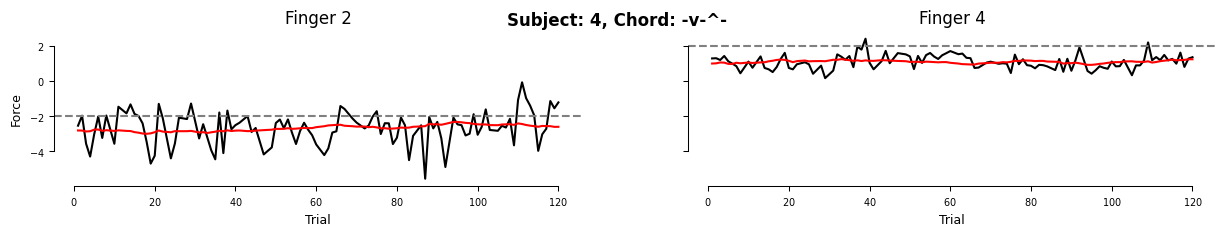

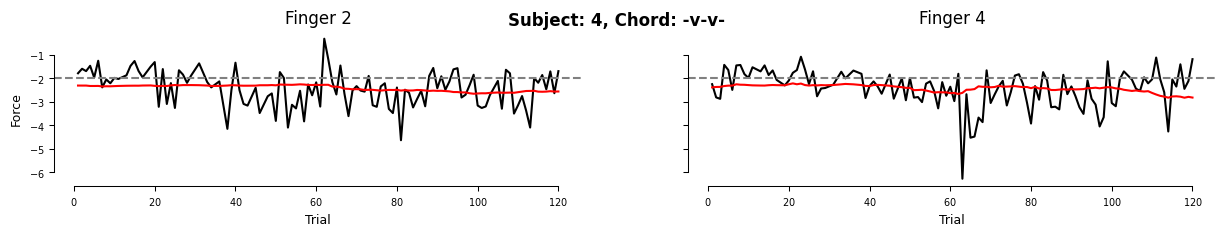

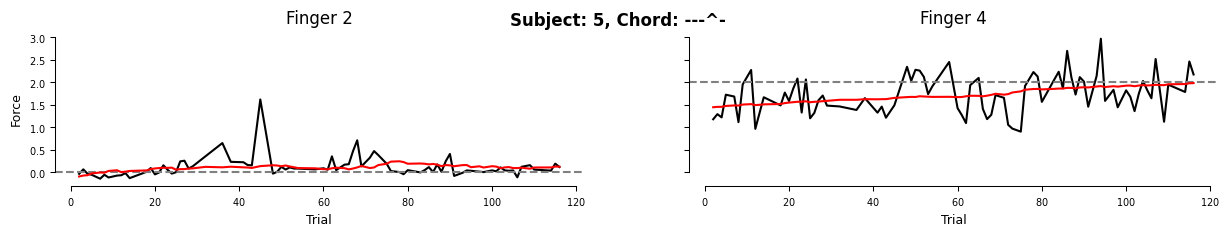

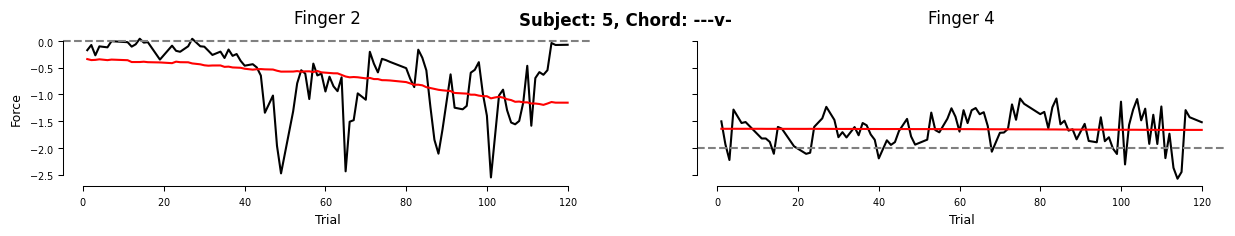

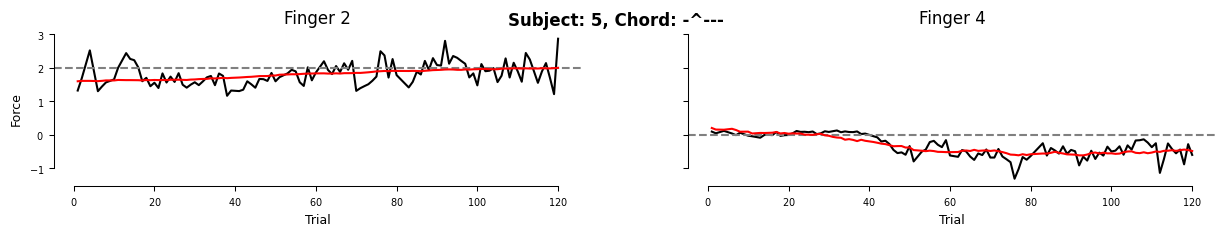

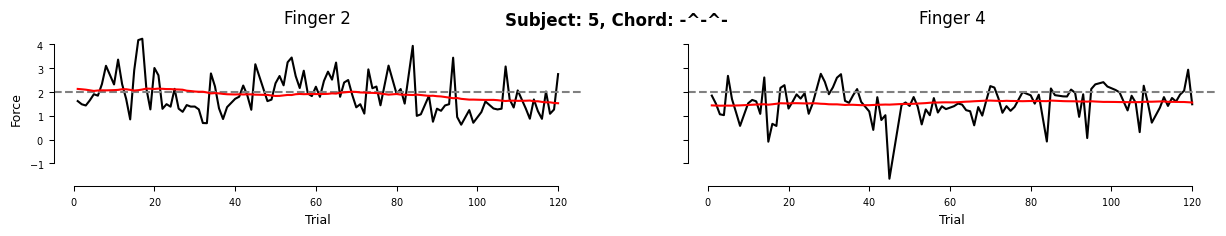

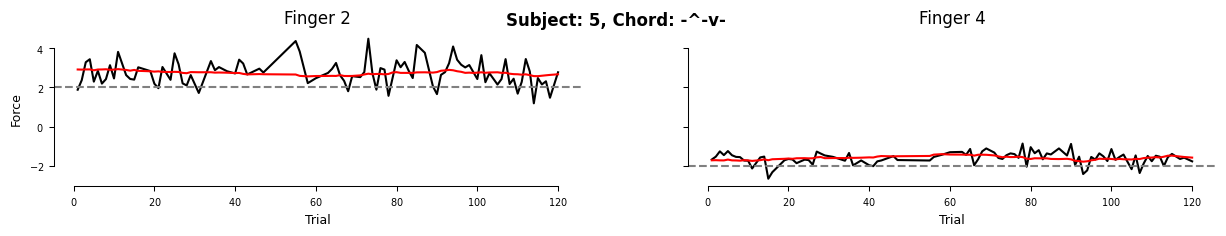

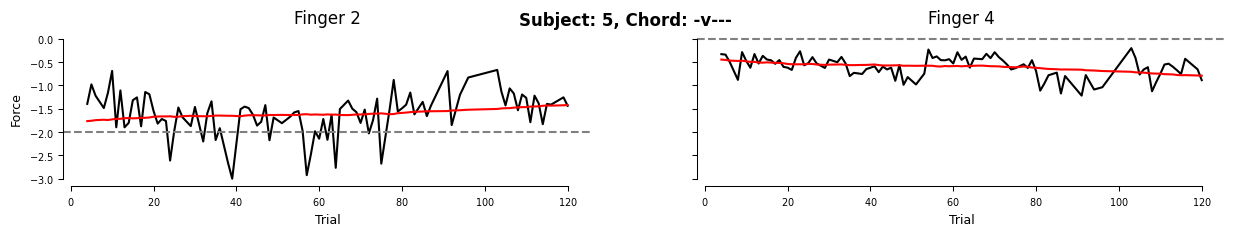

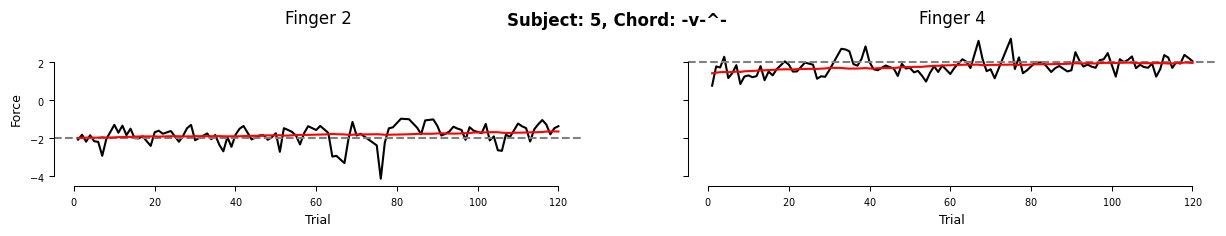

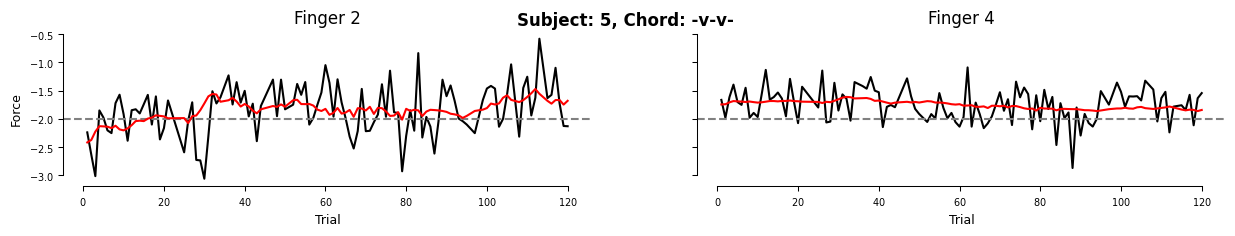

In [47]:
# Model (target subtracted; deviations from target):
#   Z_t                       : hidden state (plan)
#   X_t = Z_t + nu_t          : produced force   (endForce - target)
#   Y_t = X_t + p_t           : perturbed force  (endForcePurturbed - target)
#   Z_{t+1} = A Z_t - B Y_t   : learning rule (MINUS sign; error = perturbed force Y_t)
#
# Method B fits A and B by minimizing the sum of squared residuals
#   nu_t = X_t - Z_t = (Y_t - p_t) - Z_t   (the measurement noise)
# over the whole perturbed series.


from scipy.optimize import minimize

# --- 1. Define Model Functions ---

def unpack_params(params):

    """
    Unpacks the 8-parameter array.
    A is explicitly built as a diagonal matrix.
    """
    # Force A to be a diagonal matrix using the first two parameters
    A = np.array([[params[0], 0.0],
                  [0.0, params[1]]])
    
    # B remains a full 2x2 matrix
    B = params[2:6].reshape((2, 2))
    
    # Z0 is the initial state
    Z0 = params[6:8]
    
    return A, B, Z0
    # return A, B

def get_residuals(params, Y, P, mask, targets):
    r"""Simulate the plan forward and return the measurement noise nu_t = X_t - Z_t."""
    A, B, Z0 = unpack_params(params)
    # A, B = unpack_params(params)

    B_masked = B * mask

    num_trials = Y.shape[0]
    Z = np.zeros((num_trials, 2))
    Z[0] = Z0
    # Z[0] = targets[0]

    for t in range(num_trials - 1):
         # learning rule: Z_{t+1} = A Z_t - B Y_t  (error fed back = perturbed force Y_t)
         Z[t+1] = A @ Z[t] - B_masked @ (Y[t] - targets[t])
         # Optional safety clip to absolutely prevent infinity if data is extremely noisy
         Z[t+1] = np.clip(Z[t+1], -10, 10)

    nu = Y - Z - P                       # = (Y - p) - Z = produced - plan
    return nu

def objective(params, Y, P, mask, targets):
    r"""Minimize the sum of squared measurement noise (equivalent to MLE)."""
    nu = get_residuals(params, Y, P, mask, targets)
    return np.sum(nu**2)



# --- 2. Process the Data ---

betas = []

# Define bounds for the 8 parameters
# A matrix (retention): only the diagonals, bounded strictly between 0 and 1
bounds_A = [(0.99, 1.0), (0.99, 1.0)]
bounds_A = [(0.9, 1.0), (0.9, 1.0)]

# B matrix (learning rates): generously bounded between -1 and +1
bounds_B = [(-1, 1), (-1, 1), (-1, 1), (-1, 1)]
# Z0 (initial state): unconstrained
bounds_Z0 = [(None, None), (None, None)]

all_bounds = bounds_A + bounds_B + bounds_Z0
# all_bounds = bounds_A + bounds_B

for subnum, subj_data in subjs_correct.groupby('subNum'):
    for chord, chord_data in subj_data.groupby('chord'):
            
        print(f"processing subject {subnum}, chord {chord}")
        mask = np.ones((2, 2))
        for idx, finger in enumerate([2, 4]):
            if chord_data[f'targetForce{finger}'].iloc[0] == 0:
                mask[:, idx] = 0
                

        # Initial parameters (Length 8)
        # A_diag = [1.0, 1.0], B_flat = [0,0,0,0], Z0 = [0,0]
        # initial_params = np.concatenate([[1.0, 1.0], np.zeros(4), np.zeros(2)])
        # initial_params = np.concatenate([[1.0, 1.0], np.ones(4) / 2, np.zeros(2)])
        # initial_params = np.concatenate([[1.0, 1.0], np.zeros(4)])
        # initial_params = np.concatenate([[1.0, 1.0], np.ones(4)])
        # initial_params = np.concatenate([[1.0, 1.0], np.ones(4) / 2])

        # unpert_data = chord_data[chord_data['block_type'] == 'unpurturbed'].sort_values('TN')
        pert_data = chord_data[chord_data['block_type'] == 'purturbed'].sort_values('TN')

        # plot pert data 
        fig, axs = plt.subplots(1,2, figsize = (15,2), sharey = True)
        for idx, finger in enumerate([2,4]):
            sns.lineplot(data = pert_data, x = 'TN', y = f'endForce{finger}', ax = axs[idx],
            color = 'black')
            axs[idx].axhline(y = pert_data[f'targetForce{finger}'].iloc[0], color = 'gray', linestyle = '--')
            axs[idx].set_title(f'Finger {finger}')
            axs[idx].set_xlabel('Trial')
            axs[idx].set_ylabel('Force')
            axs[idx].set_title(f'Finger {finger}')

        # --- Fit Perturbed Data ---
        if not pert_data.empty:
            Y_pert = pert_data[[f'endForcePurturbed{i}' for i in [2, 4]]].values
            target_force = pert_data[[f'targetForce{i}' for i in [2, 4]]].values
            # Y_pert = Y_pert - target_force
            P_pert = pert_data[[f'purturbation{i}' for i in [1, 2]]].values

            Z0_init = Y_pert[0] - P_pert[0]
            initial_params = np.concatenate([[1.0, 1.0], np.zeros(4), Z0_init])

            res_pert = minimize(
                objective, 
                initial_params, 
                args=(Y_pert, P_pert, mask, target_force), 
                # method='L-BFGS-B',
                method = 'Nelder-Mead',
                bounds=all_bounds,
                options = {'disp': True, 'maxiter': 20000}
            )
            
            A_final, B_final, Z0_final = unpack_params(res_pert.x)
            # A_final, B_final = unpack_params(res_pert.x)

            B_masked = B_final * mask

            
            # B_final = np.where(mask == 1, B_final, np.nan)

            # generate the predicted force
            Z_pert = pd.DataFrame(columns = ['TN', 'endForce2', 'endForce4'])
            pert_data.reset_index(drop = True, inplace = True)
            Z_pert['TN'] = pert_data['TN']
            Z_pert['endForce2'] = Z0_final[0]
            Z_pert['endForce4'] = Z0_final[1]
            # Z_pert['endForce2'] = 0.0
            # Z_pert['endForce4'] = 0.0
            # Z_pert['endForce2'] = target_force[0, 0]
            # Z_pert['endForce4'] = target_force[0, 1]


            for t in range(Y_pert.shape[0] - 1):
                Z_pert.loc[t+1, 'endForce2'] = A_final[0, 0] * Z_pert.loc[t, 'endForce2'] - B_masked[0, 0] * (Y_pert[t, 0] - target_force[t, 0]) - B_masked[0, 1] * (Y_pert[t, 1] - target_force[t, 1])
                Z_pert.loc[t+1, 'endForce4'] = A_final[1, 1] * Z_pert.loc[t, 'endForce4'] - B_masked[1, 0] * (Y_pert[t, 0] - target_force[t, 0]) - B_masked[1, 1] * (Y_pert[t, 1] - target_force[t, 1])

            # for t in range(Y_pert.shape[0]):
            #     Z_pert.loc[t, 'endForce2'] += pert_data['targetForce2'].iloc[0]
            #     Z_pert.loc[t, 'endForce4'] += pert_data['targetForce4'].iloc[0]
            # plot the predicted force
            for idx, finger in enumerate([2,4]):
                sns.lineplot(data = Z_pert, x = 'TN', y = f'endForce{finger}', ax = axs[idx],
                color = 'red')

                axs[idx].set_title(f'Finger {finger}')
                axs[idx].set_xlabel('Trial')
                axs[idx].set_ylabel('Force')

            fig.suptitle(f'Subject: {subnum}, Chord: {chord}')
            sns.despine(trim = True)
        

            B_final = np.where(mask == 1, B_final, np.nan)


            nu_final = get_residuals(res_pert.x, Y_pert, P_pert, mask, target_force)
            # print(np.sum(nu_final**2))
            cov_eps = np.cov(nu_final.T)
            
            betas.append({
                'subNum': subnum,
                'chord': chord,
                'num_fingers': pert_data['num_targets'].iloc[0],
                'A11': np.round(A_final[0, 0], 3),
                'A12': 0.0, # Explicitly zero now
                'A21': 0.0, # Explicitly zero now
                'A22': np.round(A_final[1, 1], 3),
                'B11': np.round(B_final[0, 0], 3),
                'B12': np.round(B_final[0, 1], 3),
                'B21': np.round(B_final[1, 0], 3),
                'B22': np.round(B_final[1, 1], 3),
                'eps_var1': np.round(cov_eps[0, 0], 3),
                'eps_var2': np.round(cov_eps[1, 1], 3)
            })

betas_B = pd.DataFrame(betas)

betas_B['mean_B_diag'] = betas_B[['B11', 'B22']].mean(axis = 1)
betas_B['mean_B_off_diag'] = betas_B[['B12', 'B21']].mean(axis = 1)
betas_B['chord_type'] = betas_B.apply(utils.determine_two_finger_chord_type, axis = 1)

print("Group-mean self-learning rate (B):")
print(f" method B: {betas_B['mean_B_diag'].mean():.3f}")


In [50]:
betas_B

,subNum,chord,num_fingers,A11,A12,A21,A22,B11,B12,B21,B22,eps_var1,eps_var2,mean_B_diag,mean_B_off_diag,chord_type
0,2,---^-,1,0.939,0.0,0.0,1.000,NaN,0.016,NaN,-0.015,0.024,0.152,-0.0150,0.0160,one_finger
1,2,---v-,1,0.990,0.0,0.0,1.000,NaN,0.010,NaN,0.003,0.007,0.130,0.0030,0.0100,one_finger
2,2,-^---,1,1.000,0.0,0.0,0.900,-0.014,NaN,0.006,NaN,0.300,0.002,-0.0140,0.0060,one_finger
3,2,-^-^-,2,1.000,0.0,0.0,0.952,-0.006,-0.005,-0.142,0.209,0.295,0.163,0.1015,-0.0735,symmetric
4,2,-^-v-,2,0.977,0.0,0.0,1.000,0.037,0.031,-0.009,-0.031,0.231,0.301,0.0030,0.0110,asymmetric
5,2,-v---,1,1.000,0.0,0.0,0.900,-0.025,NaN,0.013,NaN,0.172,0.001,-0.0250,0.0130,one_finger
6,2,-v-^-,2,1.000,0.0,0.0,1.000,0.120,-0.027,-0.045,-0.005,0.194,0.159,0.0575,-0.0360,asymmetric
7,2,-v-v-,2,1.000,0.0,0.0,1.000,-0.042,0.026,-0.054,0.032,0.176,0.108,-0.0050,-0.0140,symmetric
8,3,---^-,1,0.916,0.0,0.0,1.000,NaN,0.010,NaN,-0.010,0.003,0.159,-0.0100,0.0100,one_finger
9,3,---v-,1,1.000,0.0,0.0,1.000,NaN,0.028,NaN,0.008,0.005,0.174,0.0080,0.0280,one_finger


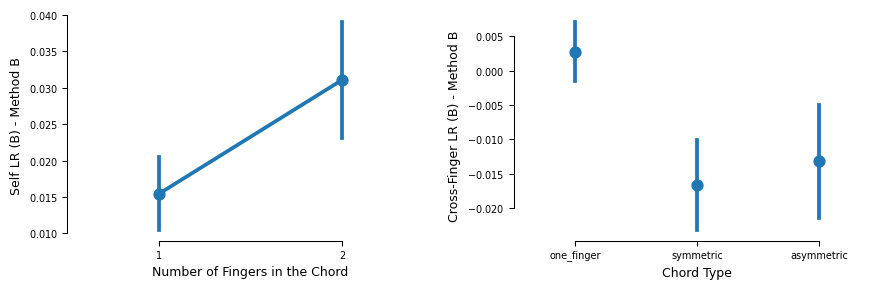

var of residuals
finger 1: 0.289, finger 2: 0.150


In [49]:
# Method C versions of the two summary plots
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
sns.pointplot(data= betas_B, x='num_fingers', y='mean_B_diag', errorbar='se', ax=axs[0])
axs[0].set_xlabel('Number of Fingers in the Chord')
axs[0].set_ylabel('Self LR (B) - Method B')
sns.pointplot(data= betas_B, x='chord_type', y='mean_B_off_diag', errorbar='se',
              linestyle=' ', ax=axs[1])
axs[1].set_xlabel('Chord Type')
axs[1].set_ylabel('Cross-Finger LR (B) - Method B')
sns.despine(trim=True)
plt.tight_layout()
plt.show()

print("var of residuals")
print(f"finger 1: {betas_B['eps_var1'].mean():.3f}, finger 2: {betas_B['eps_var2'].mean():.3f}")

# Method C — Method B without feeding the measurement noise into learning

Method C is **identical to Method B** — same least-squares trajectory fit, same `A`, `B`, `Z0` parameters, same Nelder–Mead optimiser — with **one change**: the plan is updated from `Z_t + p_t` instead of the full perturbed force `Y_t`. That is, the measurement noise `ν_t` is **not** fed back into the learning update. The schematic in the next cell highlights this single difference in the learning regressor.

- **Method B:** `Z_{t+1} = A Z_t − B Y_t = A Z_t − B (Z_t + ν_t + p_t)`  → the noisy `ν_t` enters the regressor, causing **errors-in-variables attenuation** (B collapses toward 0).
- **Method C:** `Z_{t+1} = A Z_t − B (Z_t + p_t)`  → the state is driven only by the (known) perturbation, so `B` is **not** attenuated.

The minimised residual is the same in both: `ν_t = X_t − Z_t = (Y_t − p_t) − Z_t`.

On the simulation Method C stays close to the true `B` even with large measurement noise, and on the real data it recovers positive learning rates like Method A.

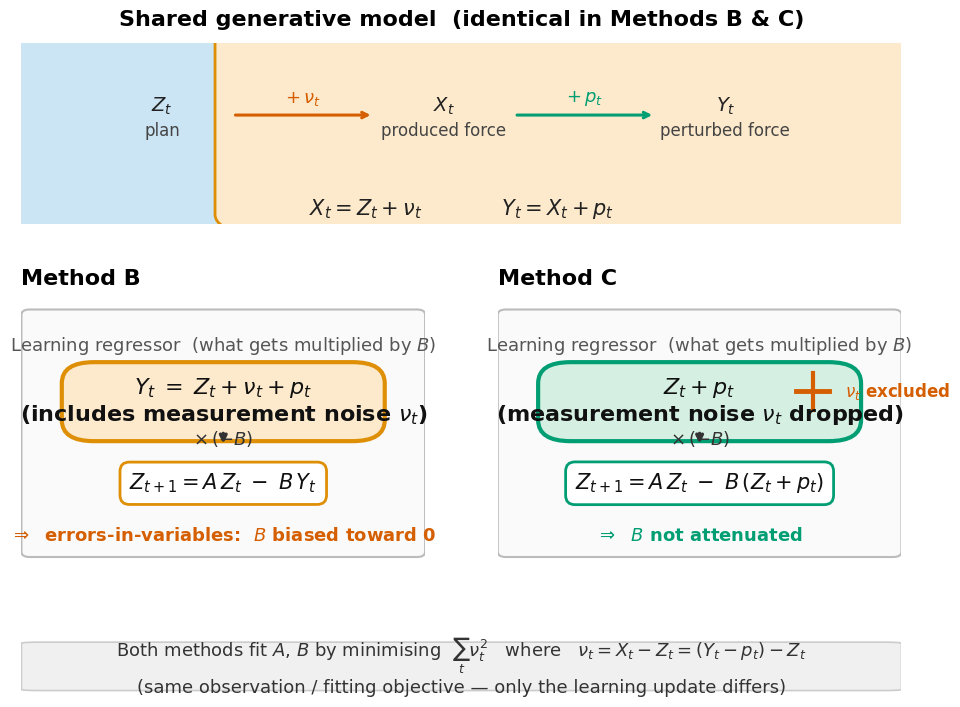

In [70]:
# Schematic: conceptual difference between Method B and Method C
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.gridspec import GridSpec

# colours — light fills + dark text for readability
C_PLAN  = '#cce5f5'   # blue
C_NOISE = '#fddbc7'   # orange
C_PERT  = '#d5f0e3'   # green
C_OBS   = '#fdeacc'   # amber
EC_PLAN, EC_NOISE, EC_PERT, EC_OBS = '#0173b2', '#d55e00', '#029e73', '#de8f05'

fig = plt.figure(figsize=(10, 7.5))
gs = GridSpec(3, 2, figure=fig, height_ratios=[1.1, 1.6, 0.35],
              hspace=0.45, wspace=0.18, left=0.06, right=0.94, top=0.93, bottom=0.06)

FS_LABEL  = 13
FS_EQ     = 15
FS_TITLE  = 16
FS_SMALL  = 12
BOX_STYLE = dict(boxstyle='round,pad=0.5,rounding_size=0.15', linewidth=2.0)


def label_box(ax, xy, w, h, title, subtitle, fc, ec, fs=FS_LABEL):
  x, y = xy
  ax.add_patch(FancyBboxPatch((x, y), w, h, facecolor=fc, edgecolor=ec, **BOX_STYLE))
  ax.text(x + w/2, y + h*0.62, title, ha='center', va='center',
          fontsize=fs + 1, fontweight='bold', color='#222222')
  if subtitle:
    ax.text(x + w/2, y + h*0.28, subtitle, ha='center', va='center',
            fontsize=fs - 1, color='#444444')


def harrow(ax, x0, x1, y, label=None, color='#333333'):
  ax.annotate('', xy=(x1, y), xytext=(x0, y),
              arrowprops=dict(arrowstyle='->', lw=2.2, color=color))
  if label:
    ax.text((x0 + x1) / 2, y + 0.04, label, ha='center', va='bottom',
            fontsize=FS_LABEL, color=color, fontweight='bold')


# ── top panel: shared generative model (drawn once) ──────────────────────────
ax_top = fig.add_subplot(gs[0, :])
ax_top.set_xlim(0, 1)
ax_top.set_ylim(0, 1)
ax_top.axis('off')
ax_top.set_title('Shared generative model  (identical in Methods B & C)',
                 fontsize=FS_TITLE, fontweight='bold', pad=12)

bw, bh = 0.16, 0.40
y_box = 0.40
xs = [0.08, 0.40, 0.72]
label_box(ax_top, (xs[0], y_box), bw, bh, r'$Z_t$', 'plan',            C_PLAN, EC_PLAN)
label_box(ax_top, (xs[1], y_box), bw, bh, r'$X_t$', 'produced force',  C_PLAN, EC_PLAN)
label_box(ax_top, (xs[2], y_box), bw, bh, r'$Y_t$', 'perturbed force', C_OBS,  EC_OBS)

harrow(ax_top, xs[0]+bw, xs[1], y_box + bh/2, r'$+\,\nu_t$', EC_NOISE)
harrow(ax_top, xs[1]+bw, xs[2], y_box + bh/2, r'$+\,p_t$',    EC_PERT)

ax_top.text(0.50, 0.08,
            r'$X_t = Z_t + \nu_t \qquad\qquad Y_t = X_t + p_t$',
            ha='center', va='center', fontsize=FS_EQ, color='#222222')


def draw_method_panel(ax, method, regressor, reg_fc, reg_ec, eqn, consequence, cons_color):
  ax.set_xlim(0, 1)
  ax.set_ylim(0, 1)
  ax.axis('off')
  ax.set_title(method, fontsize=FS_TITLE, fontweight='bold', loc='left', pad=10)

  # panel border
  ax.add_patch(FancyBboxPatch((0.02, 0.04), 0.96, 0.90,
              facecolor='#fafafa', edgecolor='#bbbbbb', linewidth=1.5,
              boxstyle='round,pad=0.02,rounding_size=0.02'))

  ax.text(0.50, 0.82, 'Learning regressor  (what gets multiplied by $B$)',
          ha='center', va='center', fontsize=FS_LABEL, color='#555555')

  # highlighted regressor box — the key visual
  rw, rh = 0.72, 0.22
  rx, ry = 0.14, 0.50
  ax.add_patch(FancyBboxPatch((rx, ry), rw, rh,
              facecolor=reg_fc, edgecolor=reg_ec, linewidth=3.0,
              boxstyle='round,pad=0.04,rounding_size=0.08'))
  ax.text(0.50, 0.61, regressor, ha='center', va='center',
          fontsize=FS_EQ + 1, fontweight='bold', color='#111111')

  ax.annotate('', xy=(0.50, 0.44), xytext=(0.50, 0.50),
              arrowprops=dict(arrowstyle='->', lw=2.5, color='#333333'))
  ax.text(0.50, 0.47, r'$\times\,(-B)$', ha='center', va='center',
          fontsize=FS_LABEL, color='#333333')

  ax.text(0.50, 0.30, eqn, ha='center', va='center',
          fontsize=FS_EQ, color='#111111',
          bbox=dict(boxstyle='round,pad=0.45', facecolor='white',
                    edgecolor=reg_ec, linewidth=2.0))

  ax.text(0.50, 0.10, consequence, ha='center', va='center',
          fontsize=FS_LABEL, fontweight='bold', color=cons_color)


# ── Method B ─────────────────────────────────────────────────────────────────
ax_b = fig.add_subplot(gs[1, 0])
draw_method_panel(
    ax_b, 'Method B',
    regressor=r'$Y_t \;=\; Z_t + \nu_t + p_t$' + '\n' + r'(includes measurement noise $\nu_t$)',
    reg_fc=C_OBS, reg_ec=EC_OBS,
    eqn=r'$Z_{t+1} = A\,Z_t \;-\; B\,Y_t$',
    consequence=r'$\Rightarrow$  errors-in-variables:  $B$ biased toward 0',
    cons_color=EC_NOISE)

# ── Method C ─────────────────────────────────────────────────────────────────
ax_c = fig.add_subplot(gs[1, 1])
draw_method_panel(
    ax_c, 'Method C',
    regressor=r'$Z_t + p_t$' + '\n' + r'(measurement noise $\nu_t$ dropped)',
    reg_fc=C_PERT, reg_ec=EC_PERT,
    eqn=r'$Z_{t+1} = A\,Z_t \;-\; B\,(Z_t + p_t)$',
    consequence=r'$\Rightarrow$  $B$ not attenuated',
    cons_color=EC_PERT)

# crossed-out nu_t on Method C side (visual cue)
ax_c.plot([0.78, 0.78], [0.58, 0.72], color=EC_NOISE, lw=3.0)
ax_c.plot([0.74, 0.82], [0.65, 0.65], color=EC_NOISE, lw=3.5)
ax_c.text(0.86, 0.65, r'$\nu_t$ excluded', ha='left', va='center',
          fontsize=FS_SMALL, color=EC_NOISE, fontweight='bold')

# ── footer ───────────────────────────────────────────────────────────────────
ax_f = fig.add_subplot(gs[2, :])
ax_f.set_xlim(0, 1)
ax_f.set_ylim(0, 1)
ax_f.axis('off')
ax_f.add_patch(FancyBboxPatch((0.02, 0.10), 0.96, 0.80,
              facecolor='#f0f0f0', edgecolor='#cccccc', linewidth=1.2,
              boxstyle='round,pad=0.02,rounding_size=0.02'))
ax_f.text(0.50, 0.50,
          r'Both methods fit $A$, $B$ by minimising  $\sum_t \nu_t^2$'
          r'   where   $\nu_t = X_t - Z_t = (Y_t - p_t) - Z_t$'
          '\n(same observation / fitting objective — only the learning update differs)',
          ha='center', va='center', fontsize=FS_LABEL, color='#333333')

plt.savefig(path_figs + 'schematic_method_B_vs_C.pdf', bbox_inches='tight')
plt.savefig(path_figs + 'schematic_method_B_vs_C.png', dpi=300, bbox_inches='tight')
plt.show()

Processing chord: -^---, subject: 2
Optimization terminated successfully.
         Current function value: 9.655846
         Iterations: 1927
         Function evaluations: 2757
Processing chord: -^-v-, subject: 2
Optimization terminated successfully.
         Current function value: 31.346203
         Iterations: 2759
         Function evaluations: 3971
Processing chord: -v---, subject: 2
Optimization terminated successfully.
         Current function value: 10.786030
         Iterations: 2359
         Function evaluations: 3480
Processing chord: -v-^-, subject: 2
Optimization terminated successfully.
         Current function value: 19.234092
         Iterations: 1232
         Function evaluations: 1796
Processing chord: -v-v-, subject: 2
Optimization terminated successfully.
         Current function value: 51.145886
         Iterations: 2954
         Function evaluations: 4400
Processing chord: -^-^-, subject: 3
Optimization terminated successfully.
         Current function value:

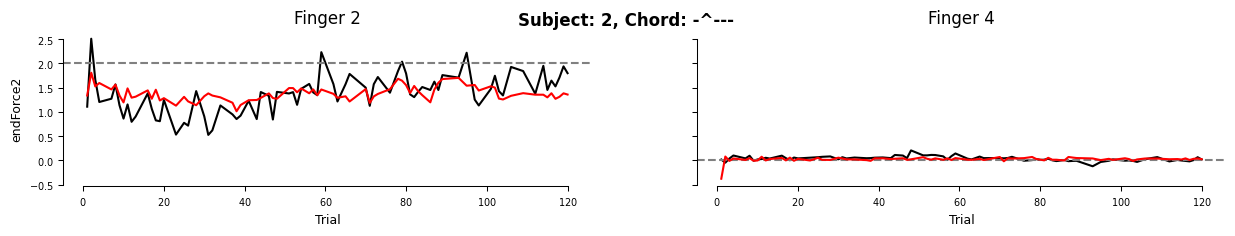

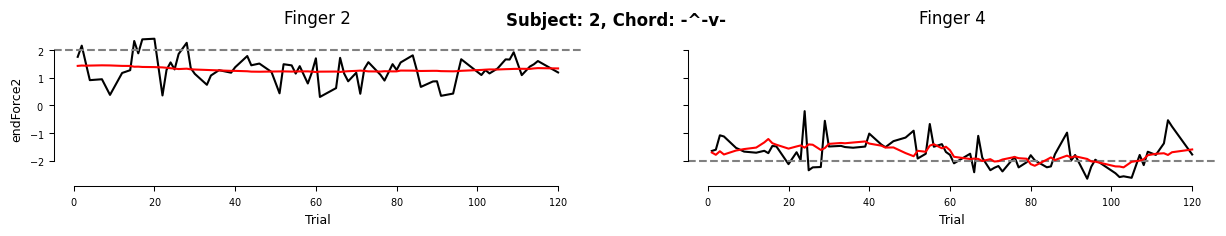

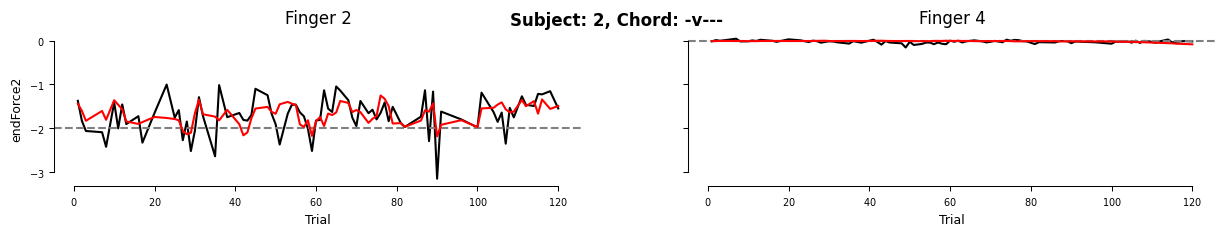

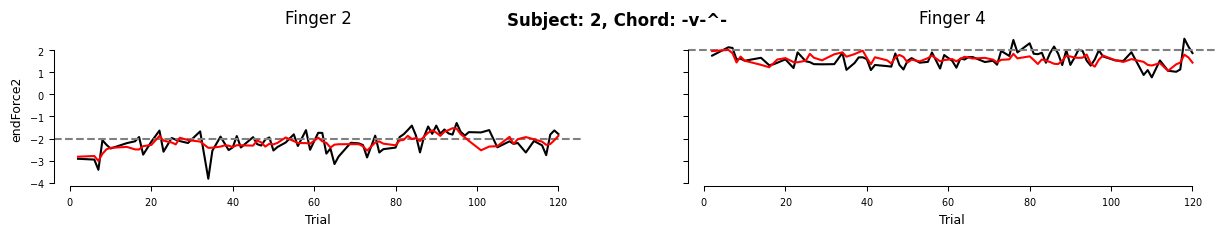

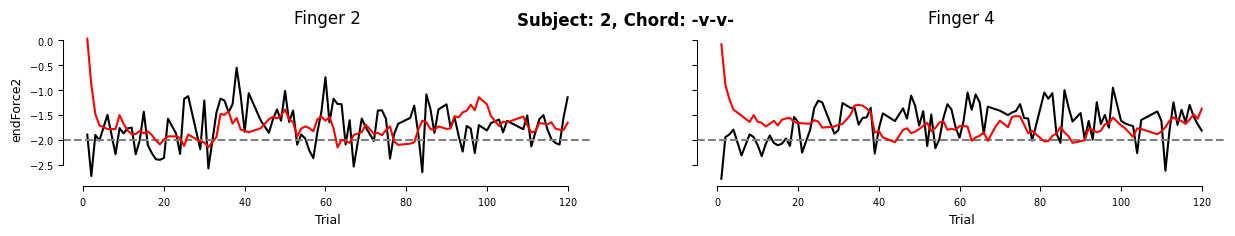

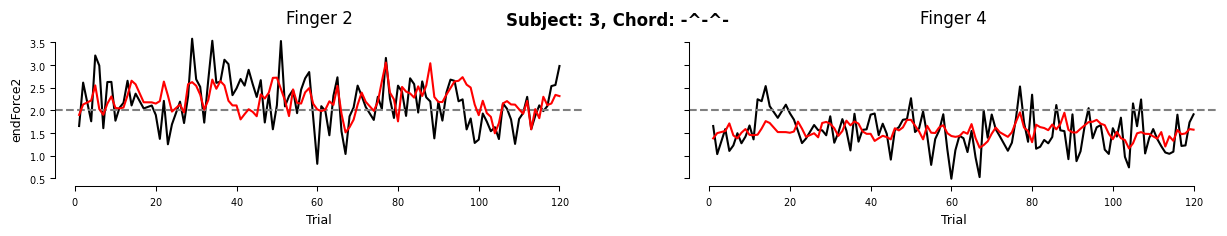

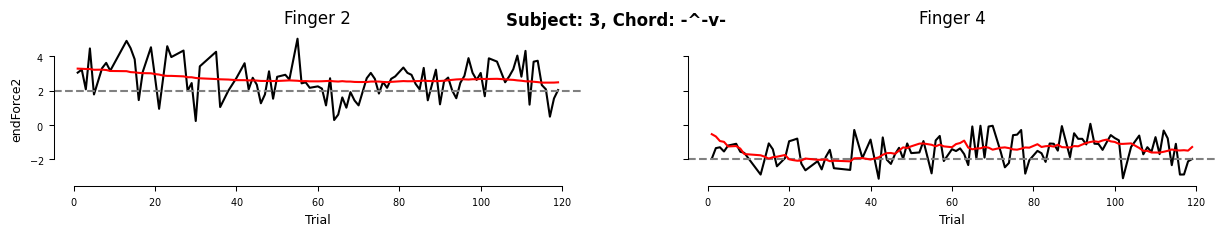

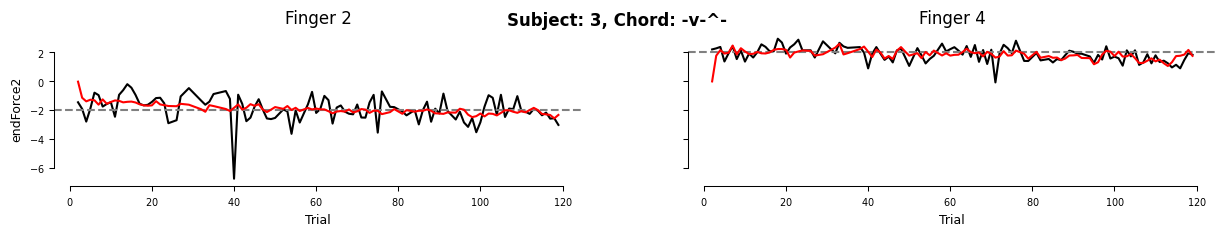

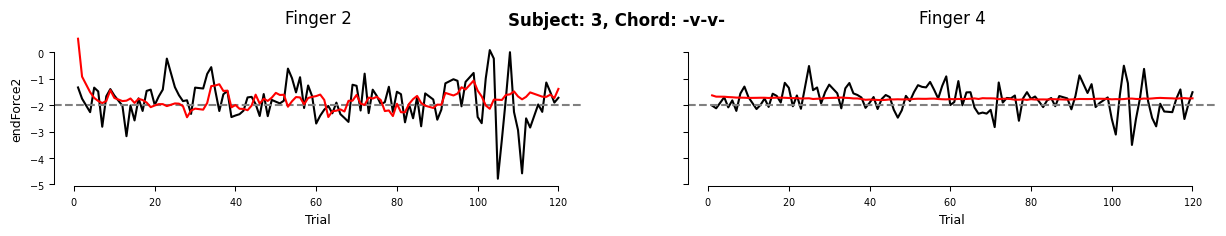

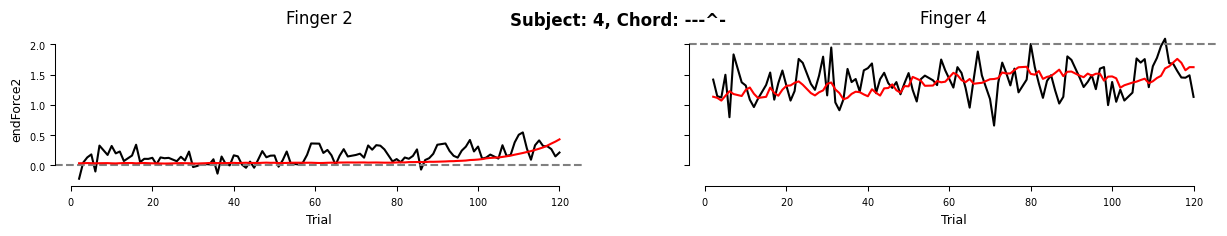

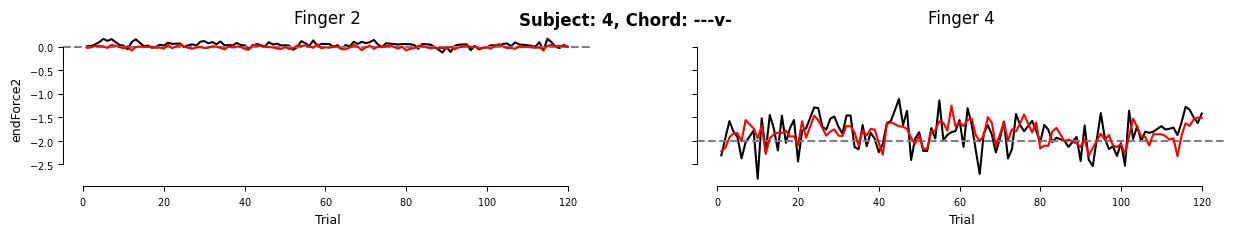

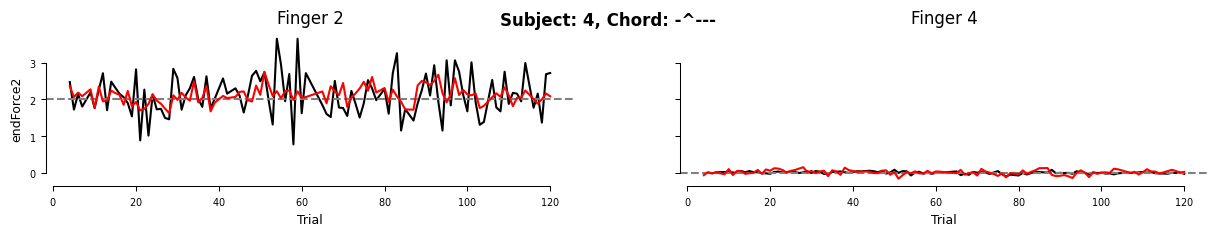

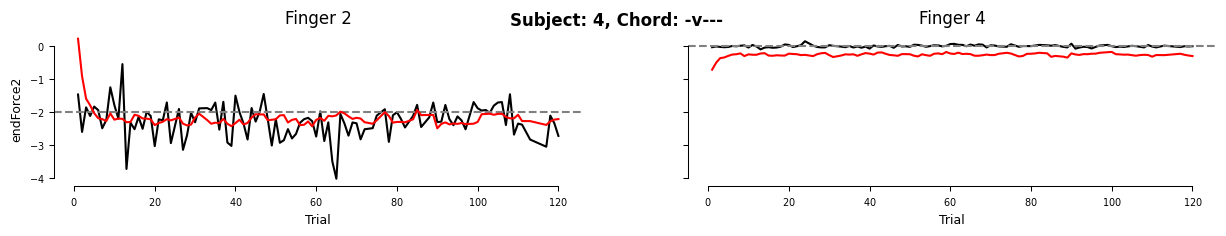

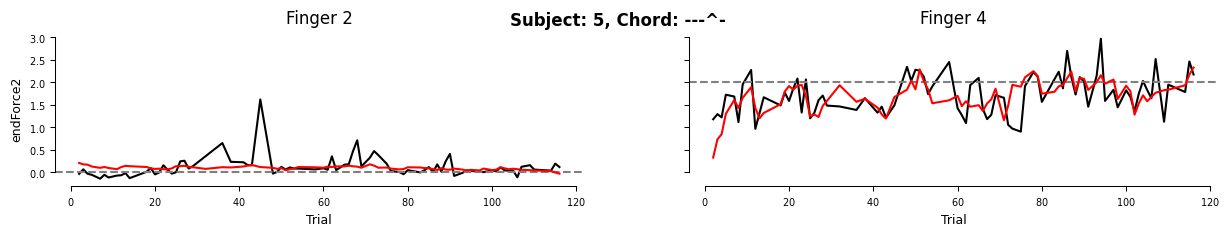

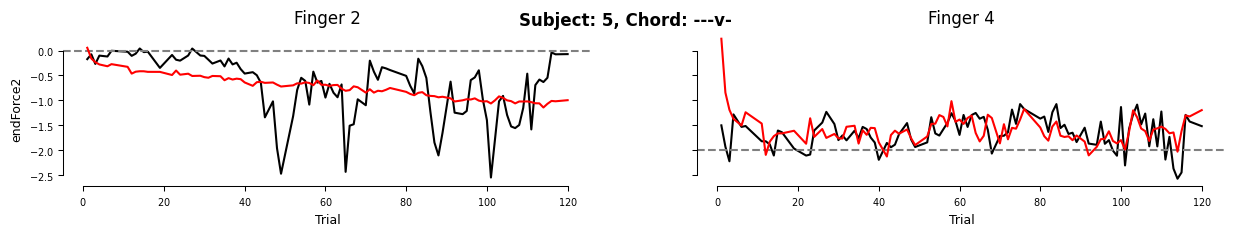

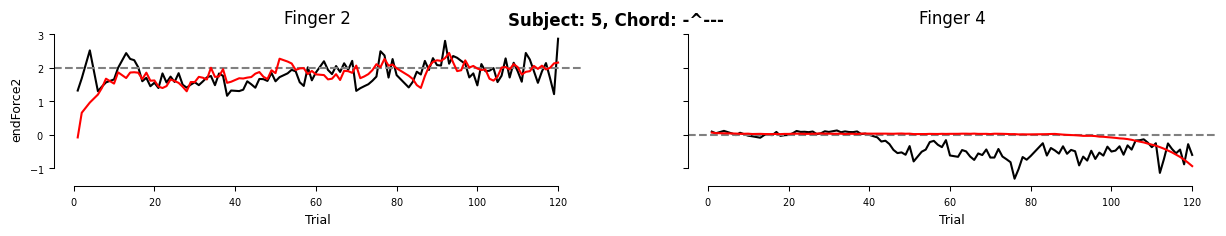

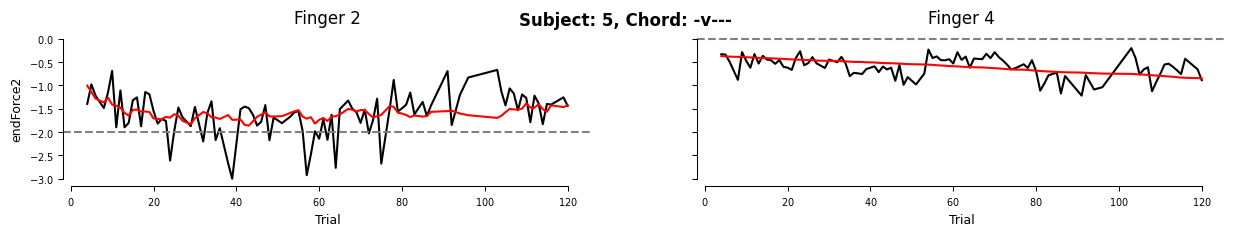

In [49]:
from scipy.optimize import minimize

# ============================================================
# Method C - exactly like Method B, but the measurement noise
#            is NOT fed back into the learning update.
# ============================================================
# Method B drives the plan with the full perturbed force Y_t (which contains the
# measurement noise nu_t), so the noisy regressor attenuates B toward 0.
# Method C drives the plan with (Z_t + p_t) instead -- i.e. it drops nu_t from
# the error that feeds learning -- so B is not attenuated. Everything else
# (objective, parameters A/B/Z0, Nelder-Mead optimiser) is identical to Method B.
#
#   Method B:  Z_{t+1} = A Z_t - B Y_t        = A Z_t - B (Z_t + nu_t + p_t)
#   Method C:  Z_{t+1} = A Z_t - B (Z_t + p_t)
#   residual (both):  nu_t = X_t - Z_t = (Y_t - p_t) - Z_t



def get_residuals_C(params, Y, P, mask, targets):
    r"""Like get_residuals, but the plan is driven by (Z_t + p_t), not Y_t."""
    A, B, Z0 = unpack_params(params)
    B_masked = B * mask
    num_trials = Y.shape[0]
    Z = np.zeros((num_trials, 2))
    Z[0] = Z0
    # Z[0] = 0
    # Z[0] = targets[0]
    for t in range(num_trials - 1):
        # error excludes the measurement noise: (Z_t + p_t) instead of Y_t
        Z[t+1] = A @ Z[t] - B_masked @ (Z[t] + P[t] - targets[t])
        Z[t+1] = np.clip(Z[t+1], -10, 10)
    nu = Y - Z - P                            # = X - Z = produced - plan
    return nu

def objective_C(params, Y, P, mask, targets):
    r"""Sum of squared measurement noise for Method C."""
    return np.sum(get_residuals_C(params, Y, P, mask, targets)**2)


def estimate_method_C(Y_abs, P, target, mask=None, targets = None):
    """Least-squares fit identical to Method B, but without feeding the
    measurement noise into learning. `Y_abs` is the perturbed force."""
    if mask is None:
        mask = np.ones((2, 2))
    # Y_centered = Y_abs - target

    initial_params = np.concatenate([[1.0, 1.0], np.zeros(4), np.zeros(2)])
    # initial_params = np.concatenate([[1.0, 1.0], np.ones(4), np.zeros(2)])

    # all_bounds = [(0.9, 1.0), (0.9, 1.0)] + [(-1, 1)] * 4 + [(None, None), (None, None)]
    all_bounds = [(0.9, 1.0), (0.9, 1.0)] + [(-1, 1)] * 4 + [(None, None), (None, None)]
    # all_bounds = [(1.0, 1.0), (1.0, 1.0)] + [(-1, 1)] * 4 + [(None, None), (None, None)]


    def callback(xk):
        f = objective_C(xk, Y_abs, P, mask)
        print(f" SSE = {f:.3f}, params = {np.round(xk, 3)}")



    res = minimize(objective_C, initial_params, args=(Y_abs, P, mask, targets),
                   method='Nelder-Mead', bounds=all_bounds, options = {'disp': True,
                   'maxiter': 10000})

    A_fit, B_fit, Z0_fit = unpack_params(res.x)
    B_fit = B_fit * mask
    return A_fit, np.where(mask == 1, B_fit, np.nan), Z0_fit, res.x


# ---- Apply Method C to the real data (with Method A side-by-side) ----
betas_C = []
for subnum, subj_data in subjs_correct.groupby('subNum'):
    for chord, chord_data in subj_data.groupby('chord'):
        print(f"Processing chord: {chord}, subject: {subnum}")
        pert_data = chord_data[chord_data['block_type'] == 'purturbed'].sort_values('TN')
        if pert_data.empty:
            continue

        mask = np.ones((2, 2))
        for idx, finger in enumerate([2, 4]):
            if pert_data[f'targetForce{finger}'].iloc[0] == 0:
                mask[:, idx] = 0

        Y_pert = pert_data[[f'endForcePurturbed{i}' for i in [2, 4]]].values
        target_force = pert_data[[f'targetForce{i}' for i in [2, 4]]].values
        P_pert = pert_data[[f'purturbation{i}' for i in [1, 2]]].values

        # plot pert data 
        fig, axs = plt.subplots(1,2, figsize = (15,2), sharey = True)
        for idx, finger in enumerate([2,4]):
            sns.lineplot(data = pert_data, x = 'TN', y = f'endForce{finger}', ax = axs[idx],
            color = 'black')
            axs[idx].axhline(y = pert_data[f'targetForce{finger}'].iloc[0], color = 'gray', linestyle = '--')
            axs[idx].set_title(f'Finger {finger}')
            axs[idx].set_xlabel('Trial')

        # Method C (no measurement-noise feedback)
        A_C, B_C, Z0_C, res_C = estimate_method_C(Y_pert, P_pert, mask, targets = target_force)
        B_masked_C = np.nan_to_num(B_C, nan = 0)

        residuals = get_residuals_C(res_C, Y_pert, P_pert, mask, targets = target_force)
        # print(np.sum(residuals**2))
        cov_eps = np.cov(residuals.T)
        # print(f"finger 1: {cov_eps[0, 0]:.3f}, finger 2: {cov_eps[1, 1]:.3f}")


        # generate the predicted force
        Z_pert = pd.DataFrame(columns = ['TN', 'endForce2', 'endForce4'])
        pert_data.reset_index(drop = True, inplace = True)
        Z_pert['TN'] = pert_data['TN']
        Z_pert['endForce2'] = Z0_C[0]
        Z_pert['endForce4'] = Z0_C[1]

        for t in range(Y_pert.shape[0] - 1):
            Z_pert.loc[t+1, 'endForce2'] = A_C[0, 0] * Z_pert.loc[t, 'endForce2'] - B_masked_C[0, 0] * (Z_pert.loc[t, 'endForce2'] + P_pert[t, 0] - target_force[t, 0]) - B_masked_C[0, 1] * (Z_pert.loc[t, 'endForce4'] + P_pert[t, 1] - target_force[t, 1])
            Z_pert.loc[t+1, 'endForce4'] = A_C[1, 1] * Z_pert.loc[t, 'endForce4'] - B_masked_C[1, 0] * (Z_pert.loc[t, 'endForce2'] + P_pert[t, 0] - target_force[t, 0]) - B_masked_C[1, 1] * (Z_pert.loc[t, 'endForce4'] + P_pert[t, 1] - target_force[t, 1])

        # for t in range(Y_pert.shape[0]):
        #     Z_pert.loc[t, 'endForce2'] += pert_data['targetForce2'].iloc[0]
        #     Z_pert.loc[t, 'endForce4'] += pert_data['targetForce4'].iloc[0]

        # plot the predicted force
        for idx, finger in enumerate([2,4]):
            sns.lineplot(data = Z_pert, x = 'TN', y = f'endForce{finger}', ax = axs[idx],
            color = 'red')

            axs[idx].set_title(f'Finger {finger}')
            axs[idx].set_xlabel('Trial')

        fig.suptitle(f'Subject: {subnum}, Chord: {chord}')
        sns.despine(trim = True)
            
            

        # Method A (covariance) for comparison
        dY = Y_pert[1:] - Y_pert[:-1]
        Pt = P_pert[:-1]
        cov_Y_P = np.cov(dY.T, Pt.T)[:2, 2:]
        var_P = np.cov(Pt.T)
        B_A = -1 * (np.eye(2) + cov_Y_P @ np.linalg.pinv(var_P))
        B_A = np.where(mask == 1, B_A, np.nan)

        betas_C.append({
            'subNum': subnum, 'chord': chord,
            'num_fingers': pert_data['num_targets'].iloc[0],
            'B11': np.round(B_C[0, 0], 3), 'B12': np.round(B_C[0, 1], 3),
            'B21': np.round(B_C[1, 0], 3), 'B22': np.round(B_C[1, 1], 3),
            'A11': np.round(A_C[0, 0], 3), 'A12': np.round(A_C[0, 1], 3),
            'A21': np.round(A_C[1, 0], 3), 'A22': np.round(A_C[1, 1], 3),
            'A_diag': np.round(np.nanmean([B_A[0, 0], B_A[1, 1]]), 3),
            'C_diag': np.round(np.nanmean([B_C[0, 0], B_C[1, 1]]), 3),
            'eps_var1': np.round(cov_eps[0, 0], 3),
            'eps_var2': np.round(cov_eps[1, 1], 3)
        })

betas_C = pd.DataFrame(betas_C)
betas_C['mean_B_diag'] = betas_C[['B11', 'B22']].mean(axis=1)
betas_C['mean_B_off_diag'] = betas_C[['B12', 'B21']].mean(axis=1)
betas_C['chord_type'] = betas_C.apply(utils.determine_two_finger_chord_type, axis=1)

print("Group-mean self-learning (diagonal B):")
print(f"  Method A (covariance):    {np.nanmean(betas_C['A_diag']):.3f}")
print(f"  Method C (no noise feedback): {np.nanmean(betas_C['C_diag']):.3f}")

In [50]:
betas_C

,subNum,chord,num_fingers,B11,B12,B21,B22,A11,A12,A21,A22,A_diag,C_diag,eps_var1,eps_var2,mean_B_diag,mean_B_off_diag,chord_type
0,2,-^---,1,0.251,1.000,0.046,1.000,0.900,0.0,0.0,0.900,0.247,0.626,0.128,0.025,0.6255,0.5230,one_finger
1,2,-^-v-,2,0.004,0.018,-0.246,-0.032,1.000,0.0,0.0,0.900,-0.060,-0.014,0.225,0.216,-0.0140,-0.1140,asymmetric
2,2,-v---,1,0.394,0.653,-0.005,-0.227,0.947,0.0,0.0,0.900,0.468,0.083,0.132,0.001,0.0835,0.3240,one_finger
3,2,-v-^-,2,0.255,-0.033,-0.030,0.313,1.000,0.0,0.0,0.900,0.333,0.284,0.136,0.098,0.2840,-0.0315,asymmetric
4,2,-v-v-,2,0.063,0.293,0.256,0.054,0.935,0.0,0.0,0.951,0.077,0.058,0.254,0.256,0.0585,0.2745,symmetric
5,3,-^-^-,2,0.405,0.203,0.205,0.103,1.000,0.0,0.0,1.000,0.192,0.254,0.230,0.146,0.2540,0.2040,symmetric
6,3,-^-v-,2,0.029,-0.023,0.212,-0.001,1.000,0.0,0.0,0.900,0.626,0.014,1.002,0.617,0.0140,0.0945,asymmetric
7,3,-v-^-,2,0.128,-0.281,-0.235,0.420,0.972,0.0,0.0,0.943,0.271,0.274,0.718,0.242,0.2740,-0.2580,asymmetric
8,3,-v-v-,2,0.342,0.306,0.019,-0.011,0.909,0.0,0.0,1.000,0.089,0.166,0.637,0.238,0.1655,0.1625,symmetric
9,4,---^-,1,-0.176,-0.005,-0.206,0.140,0.923,0.0,0.0,0.923,-0.131,-0.018,0.020,0.077,-0.0180,-0.1055,one_finger


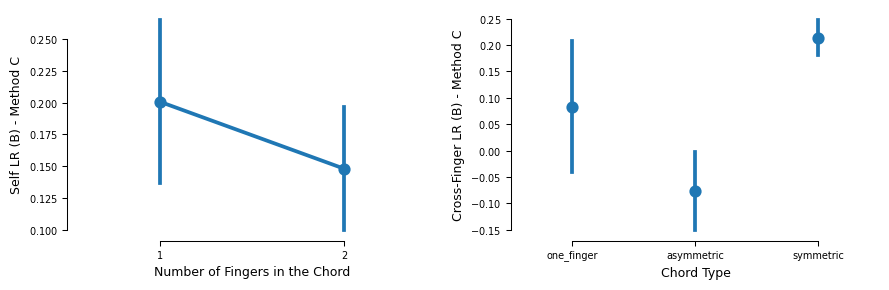

var of residuals
finger 1: 0.284, finger 2: 0.149


In [51]:
# Method C versions of the two summary plots
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
sns.pointplot(data=betas_C, x='num_fingers', y='mean_B_diag', errorbar='se', ax=axs[0])
axs[0].set_xlabel('Number of Fingers in the Chord')
axs[0].set_ylabel('Self LR (B) - Method C')
sns.pointplot(data=betas_C, x='chord_type', y='mean_B_off_diag', errorbar='se',
              linestyle=' ', ax=axs[1])
axs[1].set_xlabel('Chord Type')
axs[1].set_ylabel('Cross-Finger LR (B) - Method C')
sns.despine(trim=True)
plt.tight_layout()
plt.show()

print("var of residuals")
print(f"finger 1: {betas_C['eps_var1'].mean():.3f}, finger 2: {betas_C['eps_var2'].mean():.3f}")

# Method D — Kalman-filter MLE (state-space version)

Method D fits the **same** state-space model as Method C, but as a proper linear-Gaussian model estimated by maximum likelihood with a **Kalman filter**. Unlike the deterministic least-squares Method C, it includes a **process-noise** term `Q` that lets the latent plan drift, which makes it more robust on the real data (it sits closer to Method A) at the cost of extra parameters.

- **state (plan):** `Z_{t+1} = (A − B) Z_t − B p_t + η_t`,  `η ~ N(0, Q)`
- **observation:** `X_t = Z_t + ν_t`,  `ν ~ N(0, R)`,  with `X_t = endForce − target` (produced force)

As in Method C, the perturbation `p_t` enters only as a known input and the measurement noise is modelled as observation noise `R`, so `B` is not attenuated.

In [18]:
from scipy.optimize import minimize

# ============================================================
# Method D - Kalman-filter MLE of the same model as Method C
# ============================================================
#   plan (state):  Z_{t+1} = (A - B) Z_t  -  B p_t  +  eta_t      eta ~ N(0, Q)
#   observation:   X_t     = Z_t  +  nu_t                          nu  ~ N(0, R)
# where X_t = endForce - target (produced force) and p_t = perturbation.

def _kalman_negloglik(params, X, P, mask):
    a    = params[0:2]
    B    = params[2:6].reshape(2, 2) * mask
    Q    = np.diag(np.exp(params[6:8]))      # process noise    (log-parametrised)
    R    = np.diag(np.exp(params[8:10]))     # observation noise (log-parametrised)
    Z    = params[10:12].copy()              # initial plan
    F    = np.diag(a) - B
    Pcov = np.eye(2) * 10.0                   # diffuse prior on the initial state
    nll  = 0.0
    for t in range(X.shape[0]):
        e = X[t] - Z                          # innovation (produced force - plan)
        S = Pcov + R
        sign, logdet = np.linalg.slogdet(S)
        if sign <= 0:
            return 1e12
        Sinv = np.linalg.inv(S)
        nll += 0.5 * (2 * np.log(2 * np.pi) + logdet + e @ Sinv @ e)
        K = Pcov @ Sinv                       # Kalman gain
        Z = Z + K @ e
        Pcov = (np.eye(2) - K) @ Pcov
        Z = F @ Z - B @ P[t]                  # predict next plan
        Pcov = F @ Pcov @ F.T + Q
    return nll


def estimate_method_D(Y_abs, P, target, mask=None):
    """Kalman-filter MLE of B. `Y_abs` is the perturbed force (endForcePurturbed);
    the produced force is recovered as X = Y_abs - target - P."""
    if mask is None:
        mask = np.ones((2, 2))
    X = (Y_abs - target) - P                  # produced-force deviation (endForce - target)
    init   = np.concatenate([[1.0, 1.0], np.zeros(4), [-2.0, -2.0], [-1.0, -1.0], X[0]])
    bounds = [(0.5, 1.0), (0.5, 1.0)] + [(-1, 1)] * 4 + [(-12, 2)] * 4 + [(None, None), (None, None)]
    res = minimize(_kalman_negloglik, init, args=(X, P, mask),
                   method='L-BFGS-B', bounds=bounds)
    B = res.x[2:6].reshape(2, 2) * mask
    return np.where(mask == 1, B, np.nan)


# ---- Apply Method D to the real data (with Method A side-by-side) ----
betas_D = []
for subnum, subj_data in subjs_correct.groupby('subNum'):
    for chord, chord_data in subj_data.groupby('chord'):
        pert_data = chord_data[chord_data['block_type'] == 'purturbed'].sort_values('TN')
        if pert_data.empty:
            continue

        mask = np.ones((2, 2))
        for idx, finger in enumerate([2, 4]):
            if pert_data[f'targetForce{finger}'].iloc[0] == 0:
                mask[:, idx] = 0

        Y_pert = pert_data[[f'endForcePurturbed{i}' for i in [2, 4]]].values
        target_force = pert_data[[f'targetForce{i}' for i in [2, 4]]].values
        P_pert = pert_data[[f'purturbation{i}' for i in [1, 2]]].values

        # Method D (Kalman)
        B_D = estimate_method_D(Y_pert, P_pert, target_force, mask)

        # Method A (covariance) for comparison
        dY = Y_pert[1:] - Y_pert[:-1]
        Pt = P_pert[:-1]
        cov_Y_P = np.cov(dY.T, Pt.T)[:2, 2:]
        var_P = np.cov(Pt.T)
        B_A = -1 * (np.eye(2) + cov_Y_P @ np.linalg.pinv(var_P))
        B_A = np.where(mask == 1, B_A, np.nan)

        betas_D.append({
            'subNum': subnum, 'chord': chord,
            'num_fingers': pert_data['num_targets'].iloc[0],
            'B11': np.round(B_D[0, 0], 3), 'B12': np.round(B_D[0, 1], 3),
            'B21': np.round(B_D[1, 0], 3), 'B22': np.round(B_D[1, 1], 3),
            'A_diag': np.round(np.nanmean([B_A[0, 0], B_A[1, 1]]), 3),
            'D_diag': np.round(np.nanmean([B_D[0, 0], B_D[1, 1]]), 3),
        })

betas_D = pd.DataFrame(betas_D)
betas_D['mean_B_diag'] = betas_D[['B11', 'B22']].mean(axis=1)
betas_D['mean_B_off_diag'] = betas_D[['B12', 'B21']].mean(axis=1)
betas_D['chord_type'] = betas_D.apply(utils.determine_two_finger_chord_type, axis=1)

print("Group-mean self-learning (diagonal B):")
print(f"  Method A (covariance):    {np.nanmean(betas_D['A_diag']):.3f}")
print(f"  Method D (Kalman MLE):    {np.nanmean(betas_D['D_diag']):.3f}")
betas_D

Group-mean self-learning (diagonal B):
  Method A (covariance):    0.254
  Method D (Kalman MLE):    0.141


,subNum,chord,num_fingers,B11,B12,B21,B22,A_diag,D_diag,mean_B_diag,mean_B_off_diag,chord_type
0,2,-^---,1,0.015,NaN,0.004,NaN,0.247,0.015,0.0150,0.0040,one_finger
1,2,-^-v-,2,-0.057,0.039,0.022,0.042,-0.060,-0.007,-0.0075,0.0305,asymmetric
2,2,-v---,1,0.361,NaN,0.013,NaN,0.468,0.361,0.3610,0.0130,one_finger
3,2,-v-^-,2,0.246,-0.073,-0.128,0.116,0.333,0.181,0.1810,-0.1005,asymmetric
4,2,-v-v-,2,-0.025,0.019,-0.079,0.003,0.077,-0.011,-0.0110,-0.0300,symmetric
5,3,-^-^-,2,0.327,0.201,0.077,0.094,0.192,0.211,0.2105,0.1390,symmetric
6,3,-^-v-,2,0.057,-0.053,-0.003,-0.059,0.626,-0.001,-0.0010,-0.0280,asymmetric
7,3,-v-^-,2,0.107,-0.238,-0.128,0.280,0.271,0.194,0.1935,-0.1830,asymmetric
8,3,-v-v-,2,0.174,0.041,-0.017,0.020,0.089,0.097,0.0970,0.0120,symmetric
9,4,---^-,1,NaN,0.039,NaN,-0.004,-0.131,-0.004,-0.0040,0.0390,one_finger


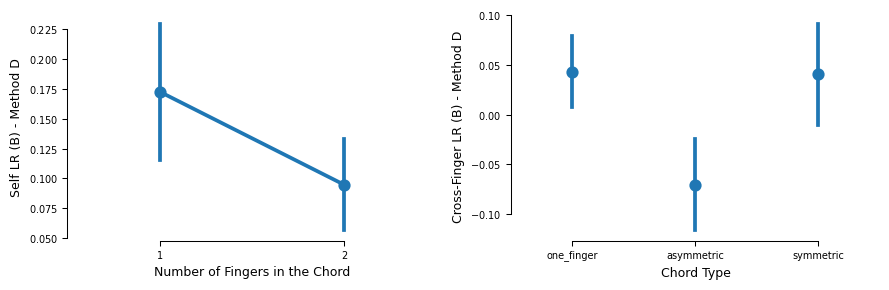

In [19]:
# Method D versions of the two summary plots
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
sns.pointplot(data=betas_D, x='num_fingers', y='mean_B_diag', errorbar='se', ax=axs[0])
axs[0].set_xlabel('Number of Fingers in the Chord')
axs[0].set_ylabel('Self LR (B) - Method D')
sns.pointplot(data=betas_D, x='chord_type', y='mean_B_off_diag', errorbar='se',
              linestyle=' ', ax=axs[1])
axs[1].set_xlabel('Chord Type')
axs[1].set_ylabel('Cross-Finger LR (B) - Method D')
sns.despine(trim=True)
plt.tight_layout()
plt.show()

# Simulation: how well do Methods A, B, C and D recover B?

We generate data from the state-space model with a **known** `A`, `B`, perturbation std and measurement-noise std, then run the four estimators on the synthetic data and compare to ground truth.

Notation (deviations from target): `Z` is the hidden plan, `X` the produced force, `Y` the perturbed force.

Generative model:

$$X_t = Z_t + \nu_t, \qquad Y_t = X_t + p_t, \qquad Z_{t+1} = A\,Z_t - B\,(\text{error}_t) + \eta_t$$

where $\nu_t \sim \mathcal{N}(0, \texttt{meas\_std})$, $p_t \sim \mathcal{N}(0, \texttt{pert\_std})$, and $\eta_t \sim \mathcal{N}(0, \texttt{proc\_std})$ (set `proc_std = 0` to omit process noise).

The **toggle** `feed_noise_back` controls the error that is fed back to the plan:

- `True`  → $\text{error}_t = Y_t - \text{target}$ (the measurement noise *is* learned from). **Model 1**: Methods A and B agree (with `proc_std = 0`).
- `False` → $\text{error}_t = Z_t + p_t - \text{target}$ (the measurement noise is *not* learned from). **Model 2**: plain Method B is biased toward 0, while Methods A, C and D stay unbiased.
- **Model 3** → same error as Model 1 but with `proc_std > 0`, so the plan drifts: $Z_{t+1} = A Z_t - B(\text{error}_t) + \eta_t$. Method B (no explicit process noise) is misspecified; Method A may also be affected.

- **Single run** (120 trials) shows what one subject × chord looks like — it is noisy.
- **Monte-Carlo** over many repetitions reveals the *bias* and *variance* of each estimator.

Model 1 (no process noise)
feed_noise_back = True, proc_std = 0.0
True B:
 [[0.15 0.04]
 [0.03 0.18]]

Method A estimate:
 [[0.08  0.035]
 [0.067 0.206]]

Method B estimate:
 [[0.12  0.102]
 [0.075 0.274]]



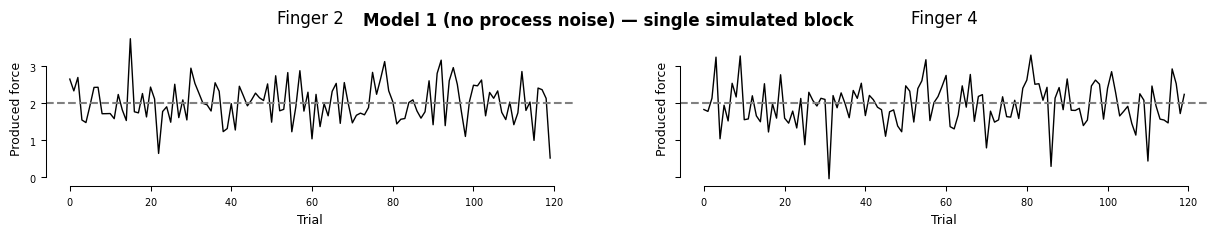

Model 3 (process noise)
feed_noise_back = True, proc_std = 0.1
True B:
 [[0.15 0.04]
 [0.03 0.18]]

Method A estimate:
 [[ 0.054 -0.077]
 [ 0.102  0.238]]

Method B estimate:
 [[-0.011 -0.018]
 [ 0.     0.102]]



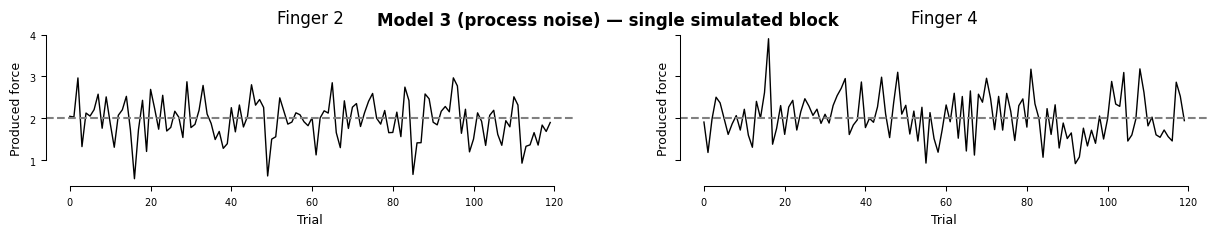

In [106]:
from scipy.optimize import minimize

# ------------------------------------------------------------------
# Ground-truth parameters
# ------------------------------------------------------------------
A_true   = np.eye(2)                       # retention (pinned to 1, as in Method B)
B_true   = np.array([[0.15, 0.04],
                     [0.03, 0.18]])         # learning rates (diag = self, off-diag = cross)
target   = np.array([2.0, 2.0])            # N; irrelevant to B but kept for realism
pert_std = 0.5                             # N, perturbation     (matches experiment: N(0, 0.5))
meas_std = 0.5                             # N, measurement noise on the produced force
proc_std = 0.1                            # N, process noise on plan update (Model 3)
n_trials = 120


def simulate(A, B, pert_std, meas_std, n_trials, target, rng, feed_noise_back=True, proc_std=0.0):
    """Generate one perturbed block from the state-space model.

    Notation (deviations from target):
        Z = hidden plan,  X = produced force (Z + meas),  Y = perturbed force (X + p).
    Learning rule (note the MINUS sign):
        Z_{t+1} = A Z_t - B * error_t + eta_t

    TOGGLE `feed_noise_back`:
      * True  -> error_t = Y_t - target  (the measurement noise IS learned from).
                 Model 1 (proc_std=0): Methods A and B AGREE.
      * False -> error_t = Z_t + p_t - target  (the measurement noise is NOT learned from).
                 Model 2: plain Method B is biased toward 0; A and C stay unbiased.

    `proc_std` > 0 adds plan drift eta_t ~ N(0, proc_std) each trial.
                 Model 3: Methods A and B are fit to a misspecified (no-Q) model.

    Returns
    -------
    Y : (n_trials, 2) perturbed force (like `endForcePurturbed`)
    P : (n_trials, 2) perturbation             (like `purturbation`)
    """
    # Z = np.zeros((n_trials, 2))            # hidden plan      (deviation from target)
    Z = np.repeat([target], n_trials, axis = 0)
    X = np.zeros((n_trials, 2))            # produced force   (deviation from target)
    Y = np.zeros((n_trials, 2))            # perturbed force  (deviation from target)
    P    = rng.normal(0.0, pert_std, size=(n_trials, 2))   # perturbation
    meas = rng.normal(0.0, meas_std, size=(n_trials, 2))   # measurement noise
    for t in range(n_trials):
        X[t] = Z[t] + meas[t]
        Y[t] = X[t] + P[t]
        if t < n_trials - 1:
            error = (Y[t] - target) if feed_noise_back else (Z[t] + P[t] - target)
            eta = rng.normal(0.0, proc_std, size=2)          # process noise on plan
            Z[t + 1] = A @ Z[t] - B @ error + eta
    return Y, P


def estimate_method_A(Y, P):
    """Covariance / single-moment estimator:  B = -cov(X_t+1, p_t) @ var(p_t)^-1."""
    X = Y - P
    X_lagged = X[1:]
    P_lagged = P[:-1]
    cov_X_P = np.cov(X_lagged.T, P_lagged.T)[:2, 2:]
    var_P = np.cov(P_lagged.T)
    return - cov_X_P @ np.linalg.pinv(var_P)


def estimate_method_B(Y, P, target):
    """Full-trajectory least squares. Reuses the notebook's `objective`/`unpack_params`."""
    # Y_centered = Y - target
    mask = np.ones((2, 2))
    targets = np.tile(target, (len(Y), 1))
    # initial_params = np.concatenate([[1.0, 1.0], np.ones(4) / 2, np.zeros(2)])
    initial_params = np.concatenate([[1.0, 1.0], np.zeros(4), Y[0] - P[0]])
    all_bounds = [(0.9, 1.0), (0.9, 1.0)] + [(-1, 1)] * 4 + [(None, None), (None, None)]
    res = minimize(objective, initial_params, args=(Y, P, mask, targets),
                   method='Nelder-Mead', 
                #    method = 'L-BFGS-B',
                   bounds=all_bounds)
    _, B_fit, _ = unpack_params(res.x)
    return B_fit


# ------------------------------------------------------------------
# Single simulated datasets: Model 1 vs Model 3
# ------------------------------------------------------------------
model_configs = {
    'Model 1 (no process noise)': dict(feed_noise_back=True, proc_std=0.0),
    'Model 3 (process noise)':    dict(feed_noise_back=True, proc_std=proc_std),
}

for seed, (model_name, sim_kwargs) in enumerate(model_configs.items()):
    print('=' * 60)
    print(model_name)
    rng = np.random.default_rng(seed)
    Y, P = simulate(A_true, B_true, pert_std, meas_std, n_trials, target, rng, **sim_kwargs)
    X = Y - P

    B_A = estimate_method_A(Y, P)
    B_B = estimate_method_B(Y, P, target)

    print(f"feed_noise_back = {sim_kwargs['feed_noise_back']}, proc_std = {sim_kwargs['proc_std']}")
    print("True B:\n", np.round(B_true, 3))
    print("\nMethod A estimate:\n", np.round(B_A, 3))
    print("\nMethod B estimate:\n", np.round(B_B, 3))
    print()

    fig, axs = plt.subplots(1, 2, figsize=(15, 2), sharey=True)
    for idx, finger in enumerate([2, 4]):
        axs[idx].plot(X[:, idx], color='black', lw=1)
        axs[idx].axhline(target[idx], color='gray', linestyle='--')
        axs[idx].set_title(f'Finger {finger}')
        axs[idx].set_xlabel('Trial')
        axs[idx].set_ylabel('Produced force')
    fig.suptitle(f'{model_name} — single simulated block')
    sns.despine(trim=True)
    plt.show()

Model 1 (no process noise): 100%|██████████| 100/100 [00:51<00:00,  1.95it/s]


Model 1 (no process noise) — Monte-Carlo over 100 reps of 120 trials
feed_noise_back=True, proc_std=0.0 (mean +/- std):

 entry |   true |         Method A |         Method B
B[0,0] |  0.150 |   0.145 +/- 0.092 |   0.145 +/- 0.053 | 
B[0,1] |  0.040 |   0.052 +/- 0.088 |   0.025 +/- 0.057 | 
B[1,0] |  0.030 |   0.014 +/- 0.103 |   0.014 +/- 0.063 | 
B[1,1] |  0.180 |   0.190 +/- 0.108 |   0.177 +/- 0.059 | 



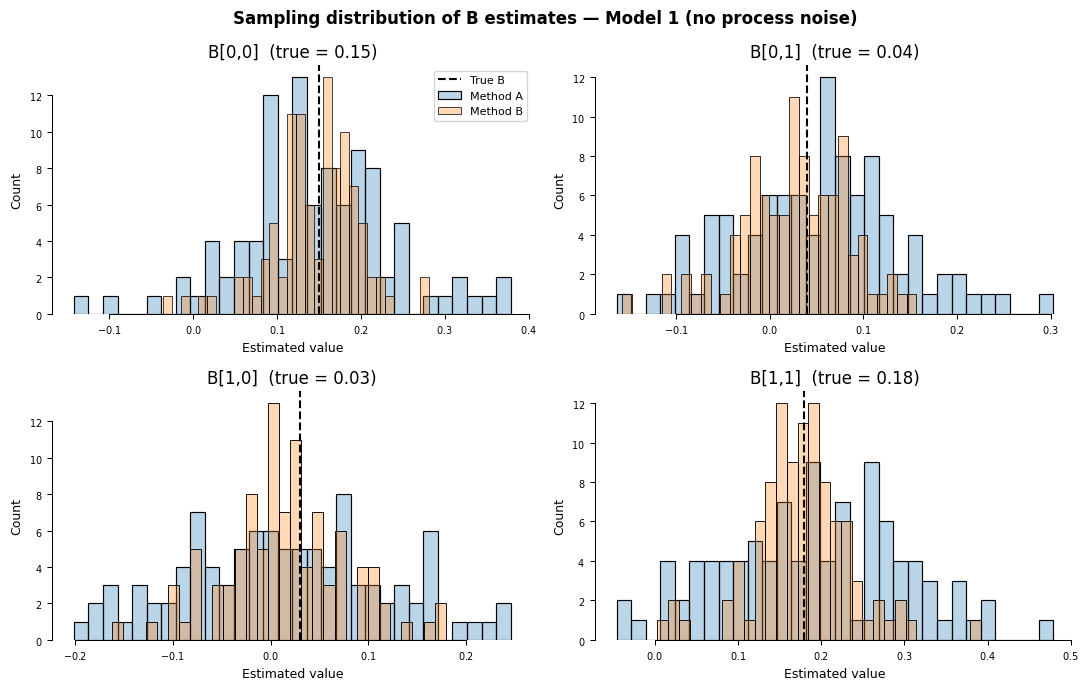

Model 3 (process noise): 100%|██████████| 100/100 [00:55<00:00,  1.80it/s]


Model 3 (process noise) — Monte-Carlo over 100 reps of 120 trials
feed_noise_back=True, proc_std=0.1 (mean +/- std):

 entry |   true |         Method A |         Method B
B[0,0] |  0.150 |   0.142 +/- 0.100 |   0.056 +/- 0.040 | 
B[0,1] |  0.040 |   0.055 +/- 0.099 |   0.019 +/- 0.044 | 
B[1,0] |  0.030 |   0.011 +/- 0.104 |   0.018 +/- 0.049 | 
B[1,1] |  0.180 |   0.190 +/- 0.111 |   0.069 +/- 0.046 | 



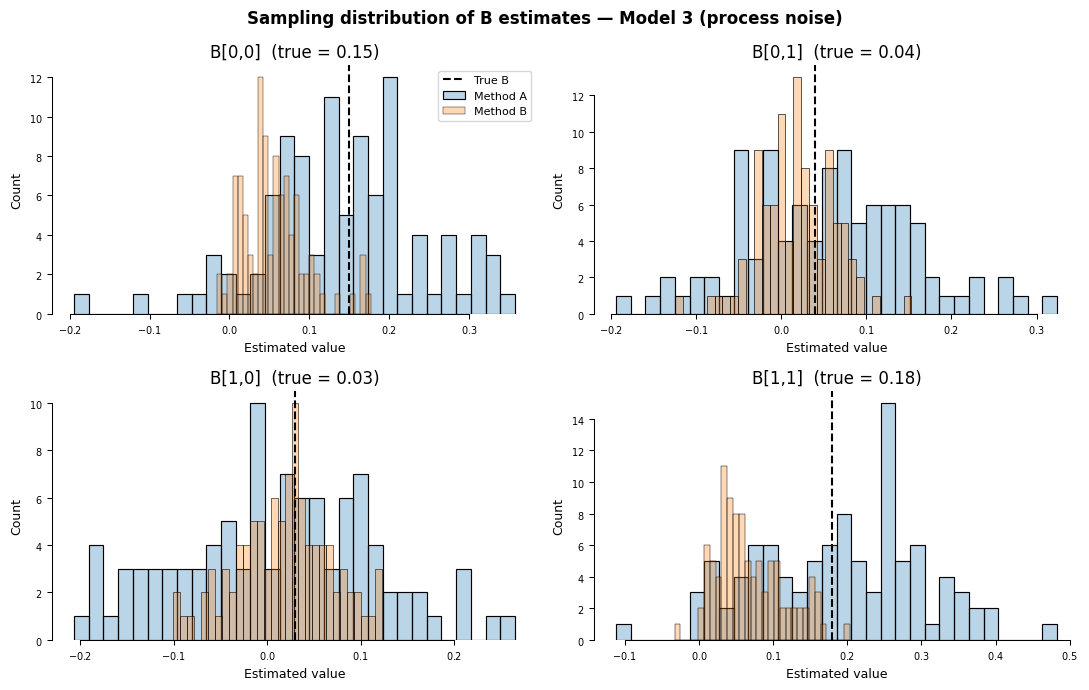

In [107]:
# ------------------------------------------------------------------
# Monte-Carlo: repeat the simulation many times to see bias & variance
# ------------------------------------------------------------------
n_reps = 100

mc_configs = {
    'Model 1 (no process noise)': dict(feed_noise_back=True, proc_std=0.0),
    'Model 3 (process noise)':    dict(feed_noise_back=True, proc_std=proc_std),
}

for model_name, sim_kwargs in mc_configs.items():
    est_A = np.zeros((n_reps, 2, 2))
    est_B = np.zeros((n_reps, 2, 2))

    rng_mc = np.random.default_rng(42)
    for r in tqdm(range(n_reps), desc=model_name):
        Yr, Pr = simulate(A_true, B_true, pert_std, meas_std, n_trials, target, rng_mc, **sim_kwargs)
        est_A[r] = estimate_method_A(Yr, Pr)
        est_B[r] = estimate_method_B(Yr, Pr, target)

    print('=' * 60)
    print(f"{model_name} — Monte-Carlo over {n_reps} reps of {n_trials} trials")
    print(f"feed_noise_back={sim_kwargs['feed_noise_back']}, proc_std={sim_kwargs['proc_std']} (mean +/- std):\n")
    print(f"{'entry':>6} | {'true':>6} | {'Method A':>16} | {'Method B':>16}")
    for i in range(2):
        for j in range(2):
            a = est_A[:, i, j]
            b = est_B[:, i, j]
            print(f"B[{i},{j}] | {B_true[i, j]:>6.3f} | "
                  f"{a.mean():>7.3f} +/- {a.std():<5.3f} | "
                  f"{b.mean():>7.3f} +/- {b.std():<5.3f} | ")
    print()

    fig, axs = plt.subplots(2, 2, figsize=(11, 7))
    for i in range(2):
        for j in range(2):
            ax = axs[i, j]
            sns.histplot(est_A[:, i, j], bins=30, alpha=0.3, label='Method A', ax=ax)
            sns.histplot(est_B[:, i, j], bins=30, alpha=0.3, label='Method B', ax=ax)
            ax.axvline(B_true[i, j], color='black', linestyle='--', label='True B')
            ax.set_title(f'B[{i},{j}]  (true = {B_true[i, j]:.2f})')
            ax.set_xlabel('Estimated value')
            if i == 0 and j == 0:
                ax.legend()
    fig.suptitle(f'Sampling distribution of B estimates — {model_name}')
    sns.despine(trim=True)
    plt.tight_layout()
    plt.show()

## Sweep the number of trials

Both estimators are consistent, so their sampling spread should shrink as the number of trials grows (roughly $\propto 1/\sqrt{n}$). This shows *how many trials* you need before Method A's estimate becomes trustworthy, and how much tighter Method B is at every sample size.

*(This cell runs several Monte-Carlo batches and can take a couple of minutes; lower `n_reps` or drop the largest `n` to speed it up.)*

n=480: 100%|██████████| 60/60 [01:05<00:00,  1.09s/it]


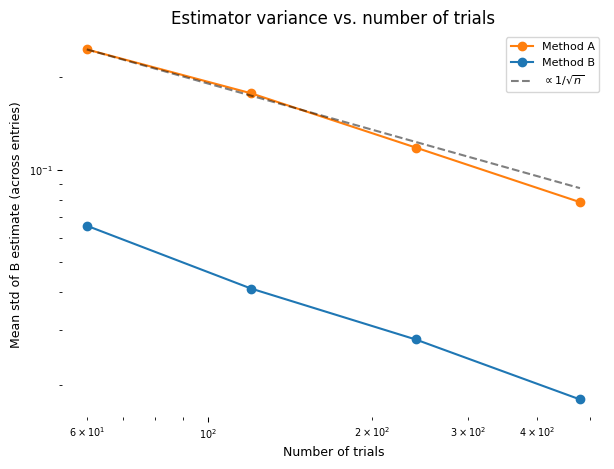

n_trials |  std(A)  |  std(B)
      60 |   0.247  |   0.066
     120 |   0.177  |   0.041
     240 |   0.118  |   0.028
     480 |   0.078  |   0.018


In [149]:
# ------------------------------------------------------------------
# How does estimator variance shrink with the number of trials?
# ------------------------------------------------------------------
n_list   = [60, 120, 240, 480]
n_reps_sweep = 60

std_A = {n: None for n in n_list}
std_B = {n: None for n in n_list}

rng_sweep = np.random.default_rng(7)
for n in n_list:
    eA = np.zeros((n_reps_sweep, 2, 2))
    eB = np.zeros((n_reps_sweep, 2, 2))
    for r in tqdm(range(n_reps_sweep), desc=f'n={n}'):
        Yr, Pr = simulate(A_true, B_true, pert_std, meas_std, n, target, rng_sweep)
        eA[r] = estimate_method_A(Yr, Pr)
        eB[r] = estimate_method_B(Yr, Pr, target)
    # summarize spread across the 4 B entries (mean of the per-entry stds)
    std_A[n] = eA.std(axis=0).mean()
    std_B[n] = eB.std(axis=0).mean()

# Plot std vs n_trials (log-log; ~1/sqrt(n) reference line)
fig, ax = plt.subplots(figsize=(7, 5))
ns = np.array(n_list, dtype=float)
ax.loglog(ns, [std_A[n] for n in n_list], 'o-', color='tab:orange', label='Method A')
ax.loglog(ns, [std_B[n] for n in n_list], 'o-', color='tab:blue',   label='Method B')
ref = std_A[n_list[0]] * np.sqrt(n_list[0]) / np.sqrt(ns)
ax.loglog(ns, ref, 'k--', alpha=0.5, label=r'$\propto 1/\sqrt{n}$')
ax.set_xlabel('Number of trials')
ax.set_ylabel('Mean std of B estimate (across entries)')
ax.set_title('Estimator variance vs. number of trials')
ax.legend()
sns.despine(trim=True)
plt.show()

print("n_trials |  std(A)  |  std(B)")
for n in n_list:
    print(f"{n:8d} | {std_A[n]:7.3f}  | {std_B[n]:7.3f}")

## Let Method B estimate `A` freely (testing the `A ≈ 1` assumption)

Method A's `B` is **invariant to the retention `A`** (in the derivation, `A` multiplies `Z_t`, which is uncorrelated with the perturbation, so it cancels). Method B, however, currently **pins `A = 1`**. If the true retention is below 1, that pinning is a misspecification that gets absorbed into `B`.

Below we simulate with a true `A = 0.9` and compare three estimators:

- **Method A** — should stay (approximately) unbiased regardless of `A`.
- **Method B, `A` pinned to 1** — should be **biased** when the true `A ≠ 1`.
- **Method B, `A` free** — should recover both the true `B` and the true `A`.

100%|██████████| 120/120 [01:30<00:00,  1.32it/s]


Simulated with true A = 0.9 (diag), true B[0,0] = 0.150

estimator              | B[0,0] mean +/- std    | B[1,1] mean +/- std
Method A               |   0.192 +/- 0.165     |   0.210 +/- 0.170
Method B (A pinned=1)  |   0.123 +/- 0.059     |   0.134 +/- 0.061
Method B (A free)      |   0.175 +/- 0.063     |   0.208 +/- 0.050

Method B (A free) recovered A diagonal: 0.842, 0.844  (true 0.9)


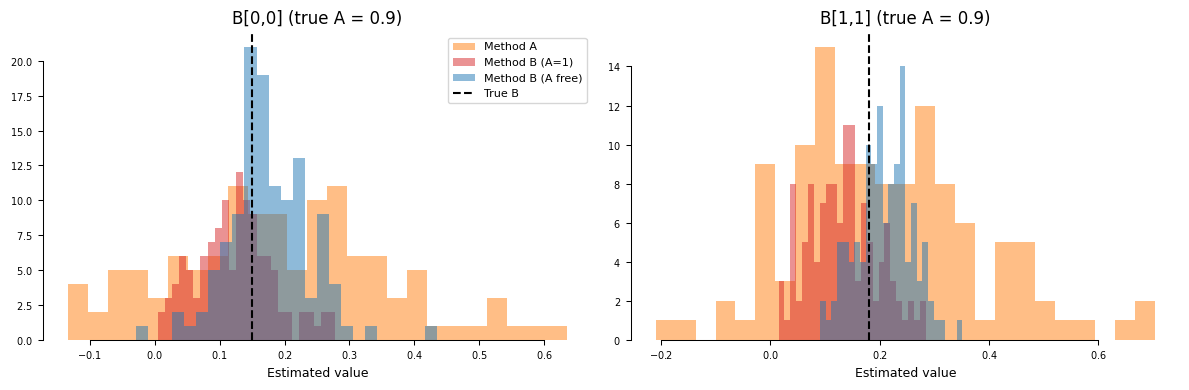

In [150]:
def estimate_method_B_freeA(Y_abs, P, target):
    """Method B variant that estimates the diagonal of A instead of pinning it to 1."""
    Y_centered = Y_abs - target
    mask = np.ones((2, 2))
    initial_params = np.concatenate([[0.95, 0.95], np.ones(4) / 2, np.zeros(2)])
    all_bounds = [(0.0, 1.0), (0.0, 1.0)] + [(-1, 1)] * 4 + [(None, None), (None, None)]
    res = minimize(objective, initial_params, args=(Y_centered, P, mask),
                   method='Nelder-Mead', bounds=all_bounds)
    A_fit, B_fit, _ = unpack_params(res.x)
    return A_fit, B_fit


# Simulate with sub-1 retention so the A=1 assumption is genuinely wrong
A_true_sub1 = np.array([[0.9, 0.0], [0.0, 0.9]])
n_reps_A = 120

est_A_mc      = np.zeros((n_reps_A, 2, 2))   # Method A
est_Bpin_mc   = np.zeros((n_reps_A, 2, 2))   # Method B, A pinned to 1
est_Bfree_mc  = np.zeros((n_reps_A, 2, 2))   # Method B, A free
A_free_mc     = np.zeros((n_reps_A, 2))      # recovered A diagonal

rng_A = np.random.default_rng(11)
for r in tqdm(range(n_reps_A)):
    Yr, Pr = simulate(A_true_sub1, B_true, pert_std, meas_std, n_trials, target, rng_A)
    est_A_mc[r] = estimate_method_A(Yr, Pr)
    est_Bpin_mc[r] = estimate_method_B(Yr, Pr, target)
    Af, Bf = estimate_method_B_freeA(Yr, Pr, target)
    est_Bfree_mc[r] = Bf
    A_free_mc[r] = np.diag(Af)

print(f"Simulated with true A = 0.9 (diag), true B[0,0] = {B_true[0,0]:.3f}\n")
print(f"{'estimator':<22} | {'B[0,0] mean +/- std':<22} | {'B[1,1] mean +/- std'}")
for name, est in [('Method A', est_A_mc),
                  ('Method B (A pinned=1)', est_Bpin_mc),
                  ('Method B (A free)', est_Bfree_mc)]:
    print(f"{name:<22} | "
          f"{est[:,0,0].mean():>7.3f} +/- {est[:,0,0].std():<5.3f}     | "
          f"{est[:,1,1].mean():>7.3f} +/- {est[:,1,1].std():<5.3f}")
print(f"\nMethod B (A free) recovered A diagonal: "
      f"{A_free_mc[:,0].mean():.3f}, {A_free_mc[:,1].mean():.3f}  (true 0.9)")

# Visualize the diagonal B estimates
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for k, (idx, lbl) in enumerate([((0, 0), 'B[0,0]'), ((1, 1), 'B[1,1]')]):
    ax = axs[k]
    ax.hist(est_A_mc[:, idx[0], idx[1]],     bins=25, alpha=0.5, label='Method A',          color='tab:orange')
    ax.hist(est_Bpin_mc[:, idx[0], idx[1]],  bins=25, alpha=0.5, label='Method B (A=1)',     color='tab:red')
    ax.hist(est_Bfree_mc[:, idx[0], idx[1]], bins=25, alpha=0.5, label='Method B (A free)',  color='tab:blue')
    ax.axvline(B_true[idx[0], idx[1]], color='black', linestyle='--', label='True B')
    ax.set_title(f'{lbl} (true A = 0.9)')
    ax.set_xlabel('Estimated value')
    if k == 0:
        ax.legend()
sns.despine(trim=True)
plt.tight_layout()
plt.show()